# Bayesian backpropagation in JAX

Gaussian moment layers, explicit backward messages, and reproducible uncertainty experiments.

Companion implementation for *Bayesian Backprop as Belief Propagation:
Single-Pass Predictive Uncertainty*, Wen Dong, NeurIPS 2026
([paper page](https://neurips.cc/virtual/2026/poster/154383)).

The implementation uses **JAX** for numerical operations, **Flax NNX** for readable model modules,
and **Optax** where an Adam recurrence is intended. Exact Gaussian inference, EP, and MFVI share
forward layers and the Gaussian coordinate bridge. Their objectives and finite updates remain distinct.

The notebook is self-contained: its collapsed setup cell carries the source, fixed data partition,
validation scripts, and small numerical evidence. It contains no trained checkpoints. Full runs download
public data/model assets when their switches are enabled. The R and PyTorch implementations are separate
references; their outputs are explicitly labeled when compared with native JAX.

In [2]:
RUN_CHECKS = True
RUN_SEMANTICS = True
RUN_MNIST = False       # all five methods, MLP40 / LeNet30 epochs
RUN_DIRTY_MNIST = False # all five methods, LeNet30 epochs on ambiguous digits
RUN_CIFAR = False       # all five methods, 100 epochs per architecture
RUN_TEXT = False        # original sampled and conditional-moment transfer protocol
DOWNLOAD_PUBLIC_DATA = False

In [3]:
#@title Source and environment (expand to inspect)
import base64,io,zipfile,pathlib,sys,subprocess,importlib.util,os,gc,json
ROOT=pathlib.Path.cwd()/"bayesify_jax_reader"
ROOT.mkdir(exist_ok=True)
zipfile.ZipFile(io.BytesIO(base64.b64decode('...'))).extractall(ROOT)
from importlib.metadata import version,PackageNotFoundError
def installed(name):
    try:return version(name)
    except PackageNotFoundError:return None
expected={'jax':'0.4.38','flax':'0.10.4','optax':'0.2.4'}
gpu=subprocess.run(['sh','-c','command -v nvidia-smi'],capture_output=True).returncode==0
if any(installed(n)!=v for n,v in expected.items()) or (gpu and installed('jax-cuda12-plugin')!='0.4.38'):
    if any(n in sys.modules for n in expected):
        raise RuntimeError('Restart the kernel before running this standalone notebook setup.')
    packages=['jax[cuda12]==0.4.38' if gpu else 'jax==0.4.38','flax==0.10.4','optax==0.2.4']
    subprocess.check_call([sys.executable,'-m','pip','install','--quiet',*packages])
if gpu:
    if installed('jax-cuda13-plugin') is not None:
        subprocess.check_call([sys.executable,'-m','pip','uninstall','-y','jax-cuda13-plugin','jax-cuda13-pjrt'])
for package in ['scipy','numpy','matplotlib','pandas','nbformat']:
    if importlib.util.find_spec(package) is None:subprocess.check_call([sys.executable,'-m','pip','install','--quiet',package])
if DOWNLOAD_PUBLIC_DATA:
    subprocess.check_call([sys.executable,'-m','pip','install','--quiet','datasets==4.8.5','transformers==5.22.1','huggingface-hub==1.33.0','safetensors==0.8.0'])
os.environ.setdefault('XLA_FLAGS','--xla_disable_hlo_passes=constant_folding')
os.environ.setdefault('XLA_PYTHON_CLIENT_PREALLOCATE','false')
sys.path.insert(0,str(ROOT/'src'));os.chdir(ROOT)
TRAIN_ENV={**os.environ,'PYTHONPATH':str(ROOT/'src'),
           'JAX_ENABLE_X64':'false','JAX_DEFAULT_MATMUL_PRECISION':'default'}
import jax
jax.config.update('jax_enable_x64', True)
jax.config.update('jax_default_matmul_precision','highest')
import jax.numpy as jnp
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display,Image,HTML
from bayesify_jax import gaussian,layers,heads,messages,models,covariance,inference
from bayesify_jax import experiments,results,inspection
def artifact(path,label):
    # Colab downloads through its kernel; ordinary Jupyter serves the extracted
    # directory. Static HTML/PDF builders use the same recorded relative file.
    import html,json
    path=str(path);click=''
    try:
        from google.colab import output,files
        callback='bayesify.download.'+path
        output.register_callback(callback,lambda:files.download(str(ROOT/path)))
        click='google.colab.kernel.invokeFunction('+json.dumps(callback)+', [], {}); return false;'
    except ImportError:
        pass
    display(HTML('<a href="bayesify_jax_reader/'+html.escape(path,quote=True)+'" data-reader-file="'+html.escape(path,quote=True)+'" onclick="'+html.escape(click,quote=True)+'">'+html.escape(label+pathlib.Path(path).name)+'</a>'))
print('JAX',jax.__version__,'devices',jax.devices())

JAX 0.4.38 devices [CudaDevice(id=0)]


## 1. Gaussian coordinates and shared layers

Observed inputs are fixed tensors, not Gaussian random data. Weight beliefs carry uncertainty;
nonlinear activation distributions receive an explicitly declared approximation. The first bridge
below changes coordinates of a derivative. It is not, by itself, a posterior update.

## Local Gaussian factor: the two pipelines in the original tutorial

Start with one **frozen** linearized module, $h=c+Ax+Bw$, with independent
beliefs $x\sim\mathcal N(m_x,P_x)$ and $w\sim\mathcal N(m_w,P_w)$.
Its forward moments are $m_h=c+Am_x+Bm_w$ and
$P_h=AP_xA^\top+BP_wB^\top$. This is an exact Gaussian model; keeping the
bilinear term $\delta W\,\delta x$ would define a different, nonlinear model.

**Pipeline A: explicit messages.** Given downstream target moments
$(m_h^+,P_h^+)$, form $K_x=P_xA^\top P_h^{-1}$. Gaussian conditioning and the
law of total covariance give
$$m_x^+=m_x+K_x(m_h^+-m_h),\qquad
P_x^+=P_x+K_x(P_h^+-P_h)K_x^\top.$$
The weight message uses $K_w=P_wB^\top P_h^{-1}$ in the same equations.
Indeed, $x\mid h$ has mean $m_x+K_x(h-m_h)$ and covariance
$P_x-K_xP_hK_x^\top$; integrating over the new law of $h$ proves both formulas.
The downstream factor must act through $h$ for this replacement to be valid.

**Pipeline B: autodiff and Fisher reconstruction.** Write $d=m_h^+-m_h$.
For a scalar objective being **maximized**, seed
$g_h=P_h^{-1}d$ and
$G_h=\tfrac12P_h^{-1}(P_h^+-P_h+dd^\top)P_h^{-1}$.
Use ordinary local VJPs, then reconstruct
$m_x^+=m_x+P_xg_x$ and
$P_x^+=P_x+2P_xG_xP_x-(P_xg_x)(P_xg_x)^\top$.
Substitution of $g_x=A^\top g_h$, $G_x=A^\top G_hA$ cancels the two
$K_xdd^\top K_x^\top$ terms and recovers Pipeline A. Here $G_x$ is the covariance adjoint, whereas $K_x$ is the smoothing gain.
For a minimized loss, negate both objective adjoints.

This comparison concerns **activation and weight-belief messages**, before any
Adam, canonical VI, or site-replacement update. The exact-Gaussian plots in
Section 2 check both kinds of belief. Nonlinear approximation quality is a
separate experiment in Section 3.

**Follow the implementation:**

- `src/bayesify_jax/gaussian_chain.py`: Gaussian chain candidate
- `src/bayesify_jax/gaussian_reference.py`: independent Gaussian reference


### Why a gradient becomes a moment message

The Gaussian is an exponential family with sufficient statistics
$T(u)=(u,uu^\top)$, natural parameters
$\eta=(C^{-1}m,-\tfrac12 C^{-1})$, and expectation parameters
$\mu=E[T]=(m,M)$. Its log partition function satisfies
$\nabla_\eta A=\mu$ and $\nabla_\eta^2 A=\operatorname{Cov}_q(T)=F$.
Consequently the chain rule gives $\nabla_\eta\Phi=F\nabla_\mu\Phi$.
This is a Euclidean derivative in natural coordinates, equivalently the
natural-gradient direction in expectation coordinates. It is not an ordinary
derivative with respect to the mean alone.

To compute it from familiar derivatives, write
$dC=dM-dm\,m^\top-m\,dm^\top$. Substitution into
$d\Phi=g_m^\top dm+\operatorname{tr}(G_C^\top dC)$ gives the
expectation-coordinate covector $(g_m-2G_Cm,G_C)$. For centered Gaussian
$\epsilon=u-m$, odd centered moments vanish and
$E[\epsilon_i\epsilon_j\epsilon_k\epsilon_l]
=C_{ij}C_{kl}+C_{ik}C_{jl}+C_{il}C_{jk}$.
Multiplication by $F=\operatorname{Cov}(T)$ therefore gives

$$d_m=Cg_m,\qquad d_M=md_m^\top+d_mm^\top+2CG_CC.$$

The inverse is $g_m=C^{-1}d_m$ and
$G_C=\tfrac12C^{-1}(d_M-md_m^\top-d_mm^\top)C^{-1}$.
The implementation uses solves, not matrix inverses. The full formula includes
off-diagonal covariances; its restriction to independent coordinates gives
the elementwise diagonal formulas used by the layers.

An input image or token index is observed, not a Gaussian latent variable.
Its zero variance does not admit this inverse. The code carries its ordinary
adjoint without assigning artificial input uncertainty.

### The common reverse operation

For a cached moment map $\mu_y=F_\ell(\mu_x,\mu_w)$:

1. Decode the child signal into ordinary derivatives of its moments.
2. Apply the local vector–Jacobian product of the declared forward map.
3. Sum derivatives arriving at a shared parent from **all** children.
4. Encode the parent derivative using that parent's cached Gaussian belief.
5. Update persistent beliefs only after the reverse sweep is complete.

`literal=True` supplies the handwritten local derivative; `literal=False`
uses `jax.vjp`. Both implement this same contract. A global `jax.grad`
of the scalar objective is an independent coordinate check, not the explicit
message engine. No custom autograd rule is needed to disguise one coordinate
system as another.

**Implementation: `gaussian.py`**

```python
class Moments(NamedTuple):
    mean: object
    variance: object

class Signal(NamedTuple):
    mean: object
    second: object
    centered: object
    zero_mean: object
    zero_variance: object

class FullMoments(NamedTuple):
    mean: object
    covariance: object

def encode(q, adjoint):
    if isinstance(q,FullMoments):return encode_full(q,adjoint)
    a,b=adjoint
    active=q.variance>jnp.sqrt(jnp.finfo(q.variance.dtype).tiny)
    dm=jnp.where(active,q.variance*a,0)
    c=jnp.where(active,2*q.variance**2*b,0)
    return Signal(dm,2*q.mean*dm+c,c,jnp.where(active,0,a),jnp.where(active,0,b))

def decode(q,d):
    if isinstance(q,FullMoments):return FullMoments(*decode_full(q,d))
    active=q.variance>jnp.sqrt(jnp.finfo(q.variance.dtype).tiny)
    v=jnp.where(active,q.variance,1)
    return Moments(jnp.where(active,d.mean/v,d.zero_mean),
                   jnp.where(active,d.centered/(2*v*v),d.zero_variance))

def encode_full(q,g):
    a,b=g;b=(b+jnp.swapaxes(b,-1,-2))/2;dm=jnp.einsum("...ij,...j->...i",q.covariance,a)
    return dm,q.mean[..., :,None]*dm[...,None,:]+dm[..., :,None]*q.mean[...,None,:]+2*q.covariance@b@q.covariance

def decode_full(q,d):
    dm,dM=d;L=jnp.linalg.cholesky(q.covariance)
    solve=lambda x:cho_solve((L,True),x)
    c=dM-q.mean[..., :,None]*dm[...,None,:]-dm[..., :,None]*q.mean[...,None,:]
    gm=solve(dm[...,None])[...,0]
    return gm,jnp.swapaxes(solve(jnp.swapaxes(solve(c),-1,-2)),-1,-2)/2
```

## Layer equations and their literal reverse messages

EP and MFVI share the forward layers. Their heads and finite belief updates
are different. Here $V_W$ contains **variances**, not standard deviations.
For independent coordinates and independent input/weight blocks, the affine
rule is $m_y=m_xM_W+m_b$ and
$v_y=v_xM_W^{\odot2}+(m_x^{\odot2}+v_x)V_W+v_b$.
The rule uses first and second moments of the input; it does **not** assume
that the observed input data follow a Gaussian distribution.

For incoming Euclidean adjoints $(a,b)=(\partial\Phi/\partial m_y,
\partial\Phi/\partial v_y)$, the literal affine reverse is
$$\begin{aligned}
g_{m_x}&=aM_W^\top+2m_x\odot(bV_W^\top), &
g_{v_x}&=b(M_W^{\odot2}+V_W)^\top,\\
g_{M_W}&=m_x^\top a+2M_W\odot(v_x^\top b), &
g_{V_W}&=(m_x^{\odot2}+v_x)^\top b.
\end{aligned}$$
Bias adjoints sum $(a,b)$ over examples. These equations follow by
differentiating each summand in the forward mean and variance. Encoding them
with the same parent Fisher blocks gives literal messages; applying a local
VJP to the forward formula gives projected messages. They must agree for the
same declared formula. Convolution uses the identical product rule with
convolution/input-transpose/filter-transpose operators replacing the matrix products.

For $X\sim\mathcal N(m,v)$, let $s=\sqrt v$, $a=m/s$, and let
$\phi,\Phi$ be the standard-normal density and CDF. ReLU has
$M=m\Phi(a)+s\phi(a)$,
$S=(m^2+v)\Phi(a)+ms\phi(a)$, and $V=S-M^2$.
These follow by integrating $x$ and $x^2$ over $x>0$.
Useful derivatives are $M_m=\Phi(a)$, $M_v=\phi(a)/(2s)$,
$S_m=2M$, and $S_v=\Phi(a)$; hence $V_j=S_j-2MM_j$.
At $v=0$, use the deterministic ReLU limit instead of dividing by zero.
Gaussian input is an **activation closure**, not a claim about the dataset
or the exact nonlinear network's joint distribution.

Average pooling applies a linear map $P$: $m'=Pm$, $C'=PCP^\top$.
Dropping correlations yields $v'_j=\sum_iP_{ji}^2v_i$. For two independent
Gaussian pooling candidates, put $s^2=v_1+v_2$ and $a=(m_1-m_2)/s$.
Then $E\max(X_1,X_2)=m_1\Phi(a)+m_2\Phi(-a)+s\phi(a)$ and
$E\max(X_1,X_2)^2=(v_1+m_1^2)\Phi(a)+(v_2+m_2^2)\Phi(-a)
+(m_1+m_2)s\phi(a)$. Repeated pairwise Gaussian projection is an
approximation to a larger max-pooling window, not an exact Gaussian law.

Padding/flattening only rearrange moments. A residual addition requires
$C_{x+y}=C_x+C_y+C_{xy}+C_{yx}$; concatenation retains these as off-diagonal
blocks. The shared-factor extension carries them through reused directions.
At $y=x+x$, $C_y=4C_x$, not $2C_x$. Backward contributions to the same
parent must be **summed before its update**. These checks distinguish a
shared computation graph from fictitious independent copies of a variable.

Batch normalization with frozen statistics is affine; estimating statistics
from an uncertain minibatch introduces additional dependencies. LayerNorm,
attention, GELU and LoRA are treated by their declared local moment/directional
maps in Sections 6–7. Their VJP agreement checks the derivative of that map;
it does not prove that the map is an exact nonlinear expectation.

**Follow the implementation:**

- `src/bayesify_jax/layers.py`: `dense`, `dense_backward`, `convolution`, `convolution_backward`
- `src/bayesify_jax/layers.py`: `relu`, `relu_backward`, `max_pair`, `max_pool_backward`
- `src/bayesify_jax/layers.py`: `normalization`, `normalization_backward`


### The handwritten dense-layer reverse calculation

For row-batched inputs use $M=mA+m_b$ and
$V=vA^{\odot2}+(m^{\odot2}+v)S+v_b$, with $A$ shaped input by output.
For child Euclidean adjoints $(a,b)$, direct differentiation gives
$g_m=aA^\top+2m\odot(bS^\top)$,
$g_v=b(A^{\odot2}+S)^\top$,
$g_A=m^\top a+2A\odot(v^\top b)$ and
$g_S=(m^{\odot2}+v)^\top b$.
Bias adjoints sum $a,b$ over the batch. The JAX module uses the displayed [input, output] layout, unlike PyTorch which stores the transpose
of $A,S$, following `nn.Linear`; the equations are identical after transposing
those parameter adjoints. Encoding these pairs gives the literal messages.
EP and MFVI differ in the incoming head signal, not in this layer derivative.

**Implementation: `layers.py`**

```python
def dense(x,w,b):
    # E[Y]=mM+b; Var[Y]=v M²+(m²+v)V+v_b (diagonal activation closure).
    return Moments(x.mean@w.mean+b.mean,
                   x.variance@(w.mean**2)+(x.mean**2+x.variance)@w.variance+b.variance)

def dense_backward(x,w,b,signal):
    a,c=decode(dense(x,w,b),signal)
    gx=Moments(a@w.mean.T+2*x.mean*(c@w.variance.T),c@(w.mean**2+w.variance).T)
    flat=lambda z:z.reshape(-1,z.shape[-1])
    a,c,m,v=map(flat,(a,c,x.mean,x.variance))
    gw=Moments(m.T@a+2*w.mean*(v.T@c),(m*m+v).T@c)
    return tuple(encode(q,g) for q,g in zip((x,w,b),(gx,gw,Moments(a.sum(0),c.sum(0)))))

def convolution(x,w,b,stride=1,padding=0):
    return Moments(conv(x.mean,w.mean,stride,padding)+b.mean,
        conv(x.variance,w.mean**2,stride,padding)+conv(x.mean**2+x.variance,w.variance,stride,padding)+b.variance)

def relu_terms(x):
    positive=x.variance>0;s=jnp.sqrt(jnp.where(positive,x.variance,1))
    t=x.mean/s;P=ndtr(t);p=jnp.exp(-t*t/2)/math.sqrt(2*math.pi)
    m=x.mean*P+s*p;second=(x.mean*x.mean+x.variance)*P+x.mean*s*p
    v=second-m*m
    return Moments(jnp.where(positive,m,jnp.maximum(x.mean,0)),jnp.where(positive,jnp.maximum(v,0),0)),(positive,s,P,p,m,v)

def relu_backward(x,signal):
    y,(pos,s,P,p,m,v)=relu_terms(x);a,b=decode(y,signal)
    # Price/Stein: dm/dm=P, dm/dv=p/(2s); differentiate E[X_+²]-m_+².
    dm=jnp.where(pos,P,(x.mean>0).astype(x.mean.dtype))
    dv=jnp.where(pos,p/(2*s),0)
    vm=jnp.where(pos&(v>0),2*m*(1-P),0)
    vv=jnp.where(pos&(v>0),P-m*p/s,0)
    return (encode(x,Moments(a*dm+b*vm,a*dv+b*vv)),)
```

The literal and projected paths use the same forward map. The literal path implements its local
message algebra directly. The projected path uses a local JAX VJP. A custom-VJP wrapper converts back
to ordinary cotangents before returning to JAX: a natural signal must never masquerade as a Euclidean gradient.

**Implementation: `layers.py`**

```python
def projected(forward,parents,signal):
    # The derivative is Euclidean. Coordinate encoding is explicitly separate.
    y,pullback=jax.vjp(forward,*parents)
    ordinary=pullback(decode(y,signal))
    return tuple(encode(q,g) for q,g in zip(parents,ordinary))

def literal_autodiff(forward,reverse):
    """JAX custom VJP implementing the literal local message rule.

    JAX cotangents are Euclidean. Encode the child's cotangent, apply the
    independent analytic message rule, then decode each parent before handing
    it to JAX. Returning a natural signal as an ordinary gradient is incorrect.
    The explicit graph engine exposes the intermediate signals for inspection.
    """
    @jax.custom_vjp
    def operation(*parents):return forward(*parents)
    def fwd(*parents):
        y=forward(*parents);return y,(parents,y)
    def bwd(cache,adjoint):
        parents,y=cache;signal=encode(y,adjoint)
        return tuple(decode(q,d) for q,d in zip(parents,reverse(*parents,signal)))
    operation.defvjp(fwd,bwd)
    return operation
```

**Implementation: `messages.py`**

```python
def forward(nodes,beliefs,x,statistics=None):
    states={'input':x};records=[]
    for node in nodes:
        parents=tuple(states[n] for n in node.parents)+tuple(beliefs[n] for n in node.parameters)
        y=local_map(node,statistics)(*parents);states[node.name]=y
        records.append((node,parents,y))
    return states,records

def backward(records,signal,statistics=None,literal=False):
    pending={records[-1][0].name:signal};parameters={};activations={}
    for node,parents,y in reversed(records):
        child=pending[node.name];activations[node.name]=child;f=local_map(node,statistics)
        if not literal: messages=L.projected(f,parents,child)
        elif node.kind=='dense':messages=L.dense_backward(*parents,child)
        elif node.kind=='readout':messages=L.readout_backward(*parents,child)
        elif node.kind=='correlated_readout':raise ValueError('correlated readout uses projected local VJP, not a claimed independent literal derivative')
        elif node.kind=='conv':messages=L.convolution_backward(*parents,child,*node.options)
        elif node.kind=='conv0':
            w=parents[1];z=Moments(jnp.zeros(w.mean.shape[-1],w.mean.dtype),jnp.zeros(w.mean.shape[-1],w.mean.dtype))
            messages=L.convolution_backward(*parents,z,child,*node.options)[:2]
        elif node.kind=='relu':messages=L.relu_backward(*parents,child)
        elif node.kind=='maxpool':messages=L.max_pool_backward(*parents,child)
        elif node.kind=='avgpool':messages=L.avg_pool_backward(*parents,child)
        elif node.kind=='norm':messages=L.normalization_backward(*parents,child,*statistics[node.name])
        else:messages=L.linear_literal(f,parents,child)
        k=len(node.parents)
        for name,d in zip(node.parents,messages[:k]):pending[name]=add_signal(pending.get(name),d)
        for name,d in zip(node.parameters,messages[k:]):parameters[name]=add_signal(parameters.get(name),d)
    return pending['input'],activations,parameters
```

**From equations to modules.** `GaussianParameter` owns a mean, log variance,
and a fixed prior. `MomentLayer` calls the same mathematical kernels above;
`MomentModel` connects those layers. Its ordinary call exposes the mean network
to Flax inspection. `forward_moments` and the explicit reverse traversal use an
immutable belief snapshot. Installing an updated belief happens after the whole
reverse pass, so no layer observes a partially updated parent.

**Implementation: `models.py`**

```python
class GaussianParameter(nnx.Module):
    def __init__(self,mean,variance,prior_mean=None,prior_variance=1.):
        # Honor the declared model dtype even when the notebook enables x64
        # for its independent mathematical checks. Convolution requires both
        # operands to have the same dtype in every moment term.
        variance=jnp.asarray(variance,dtype=mean.dtype)
        prior_variance=jnp.asarray(prior_variance,dtype=mean.dtype)
        self.mean=nnx.Param(mean);self.log_variance=nnx.Param(jnp.log(jnp.broadcast_to(variance,mean.shape)))
        self.prior_mean=nnx.Variable(jnp.zeros_like(mean) if prior_mean is None else prior_mean)
        self.prior_variance=nnx.Variable(jnp.broadcast_to(prior_variance,mean.shape))
    def belief(self):return Moments(self.mean.value,jnp.exp(self.log_variance.value))
    def prior(self):return Moments(self.prior_mean.value,self.prior_variance.value)
    def install(self,q):
        self.mean.value=q.mean;self.log_variance.value=jnp.log(q.variance)

class MomentLayer(nnx.Module):
    def __init__(self,node,parameters):
        self.node=node;self.parameters=module_dict(parameters)
    def __call__(self,**parents):
        x=tuple(parents.values())
        # Real module call used by nnx.tabulate, with the declared mean network.
        ws={n:p.mean.value for n,p in self.parameters.items()}
        one=Node(self.node.name,self.node.kind,tuple(f'x{i}' for i in range(len(x))),self.node.parameters,self.node.options)
        qs=tuple(Moments(z,jnp.zeros_like(z)) for z in x)
        ps=tuple(Moments(ws[n],jnp.zeros_like(ws[n])) for n in one.parameters)
        if one.kind=='norm':
            return (x[0]-self.running_mean.value)*jax.lax.rsqrt(self.running_variance.value+1e-5)*ps[0].mean+ps[1].mean
        if one.kind=='maxpool':
            return nnx.max_pool(x[0],window_shape=(2,2),strides=(2,2),padding='VALID')
        return local_map(one)(*qs,*ps).mean
    def moments(self,*x):
        stat={self.node.name:(self.running_mean.value,self.running_variance.value)} if self.node.kind=='norm' else None
        return local_map(self.node,stat)(*x,*(self.parameters[n].belief() for n in self.node.parameters))

class MomentModel(nnx.Module):
    def __init__(self,nodes,parameters,statistics,name):
        self.nodes=tuple(nodes);self.parameters=module_dict(parameters);self.name=name;self.layers=module_dict()
        for node in nodes:
            layer=MomentLayer(node,{k:parameters[k] for k in node.parameters})
            if node.kind=='norm':layer.running_mean=nnx.Variable(statistics[node.name][0]);layer.running_variance=nnx.Variable(statistics[node.name][1])
            self.layers[node.name]=layer
    def __call__(self,x):
        states={'input':x}
        for node in self.nodes:states[node.name]=self.layers[node.name](**{f'parent{i}':states[k] for i,k in enumerate(node.parents)})
        return states[self.nodes[-1].name]
    def snapshot(self):return {n:p.belief() for n,p in self.parameters.items()}
    def priors(self):return {n:p.prior() for n,p in self.parameters.items()}
    def statistics(self):
        return {n:(l.running_mean.value,l.running_variance.value) for n,l in self.layers.items() if l.node.kind=='norm'}
    def install(self,beliefs,statistics=None):
        for n,q in beliefs.items():self.parameters[n].install(q)
        if statistics is not None:
            for n,(m,v) in statistics.items():self.layers[n].running_mean.value=m;self.layers[n].running_variance.value=v
    def forward_moments(self,x,literal=False):
        return forward(self.nodes,self.snapshot(),x,self.statistics())
```

<details><summary>Implementation: `models.py`</summary>

```python
class Builder:
    """Only architecture wiring/initialization; inference lives in explicit functions."""
    def __init__(self,seed=0,prior_variance=1e-3,initial_ratio=.1,dtype=jnp.float32,he=False,center_prior=False):
        self.rng=np.random.default_rng(seed);self.pv=prior_variance;self.ratio=initial_ratio;self.dtype=dtype;self.he=he;self.center_prior=center_prior
        self.nodes=[];self.parameters={};self.statistics={}
    def add(self,name,kind,*parents,shape=None,options=()):
        ids=()
        if shape is not None:
            if kind=='norm':m=jnp.ones(shape,self.dtype);bias=jnp.zeros(shape,self.dtype)
            else:
                fan=np.prod(shape[:-1]);bound=1/math.sqrt(fan)
                m=jnp.asarray(self.rng.uniform(-bound,bound,shape),dtype=self.dtype)
                bias=jnp.zeros((shape[-1],),dtype=self.dtype)
            if self.he and kind!='norm':m=jnp.asarray(self.rng.normal(0,math.sqrt(2/np.prod(shape[:-1])),shape),dtype=self.dtype)
            if kind=='conv0':m=jnp.asarray(self.rng.normal(0,math.sqrt(2/(np.prod(shape[:2])*shape[-1])),shape),dtype=self.dtype)
            ids=(name+'.weight',) if kind=='conv0' else (name+'.weight',name+'.bias')
            pv=self.pv
            for n,a in zip(ids,(m,bias)):
                self.parameters[n]=GaussianParameter(a,1e-5 if kind=='norm' else pv*self.ratio,prior_mean=a if self.center_prior else None,prior_variance=pv)
            if kind=='norm':self.statistics[name]=(jnp.zeros(shape,self.dtype),jnp.ones(shape,self.dtype))
        self.nodes.append(Node(name,kind,parents,ids,tuple(options)))
        return name
    def finish(self,name):return MomentModel(self.nodes,self.parameters,self.statistics,name)
```

</details>

## 2. Gaussian, EP and MFVI message equivalence

The exact example freezes a **64 → 12 → 8 → 10 tanh MLP** and its local Jacobians. The latent variables
are weight perturbations. Thus the observation passed to the perturbation graph is the label minus the
checkpoint output. Independent conditioning and RTS smoothing provide activation and weight references.
EP comparisons remove and replace explicit sites. MFVI comparisons use the current candidate state after
every coordinate update. Diagonal MFVI is compared with reverse-KL VI, not posterior marginal variances.

## Literal messages, projected messages, and custom-gradient carriers

The original tutorial presents custom-gradient and ordinary-autodiff graphs.
The essential distinction is the **calculation carried backward**, not the API
used to transport it. With a fixed forward snapshot, the shared contract is
$$d_{\rm parent}=\operatorname{encode}_{\rm parent}
\left[J_{\rm moments}^{\top}
\operatorname{decode}_{\rm child}(d_{\rm child})\right].$$
A literal implementation writes the local derivatives explicitly. A projected
implementation asks the framework for the VJP of the **same** moment formula.
The released implementations also expose this as an explicit reverse traversal,
so its messages can be inspected before an optimizer runs.

A custom-gradient carrier can return moment signals in slots normally reserved
for Euclidean gradients, but those slots then have a new contract: the next
module must decode them. Mixing such a carrier with an ordinary loss/optimizer
without the conversion is incorrect. The explicit traversal avoids this
implicit convention. Deterministic inputs receive an ordinary input adjoint;
no inverse zero-covariance Fisher block is formed.

For EP, $\Phi=\log E_{q_{\rm cav}}[f]$ yields tilted sufficient-statistic
changes when the expectation is exact. For MFVI,
$\Phi=E_q[\log f]$ gives a likelihood natural-gradient direction, not that
EP tilted distribution. Both can use the same local transport. Their finite
updates below remain distinct. The literal-versus-projected comparisons use
matched objectives, coordinates, beliefs and schedules; the Monte Carlo plots
then test how well the chosen nonlinear expectation is approximated.

**Follow the implementation:**

- `src/bayesify_jax/messages.py`: `forward`, `backward`
- `src/bayesify_jax/layers.py`: `projected`, `literal_autodiff`


### Why smoothing and backward moment updates coincide

The following proof applies to any frozen affine layer with independent parent
activation and weight blocks. The plotted fixture freezes the local Jacobians
of a 64 → 12 → 8 → 10 tanh MLP at one checkpoint and uses fixed synthetic
inputs with Gaussian observations. The test suite also checks rectangular
synthetic affine chains. Neither is a nonlinear classification-posterior oracle.

**Forward pass.** For $h_{\ell-1}\sim\mathcal N(m,P)$ and independent
$w_\ell\sim\mathcal N(a,V)$, compute $\mu=c+Am+Ba$ and
$S=APA^\top+BVB^\top$. Retain full cross-example activation covariance.

**Literal backward messages.** If the child has conditioned moments
$(\mu^+,S^+)$, write $\delta=\mu^+-\mu$ and $\Delta=S^+-S$.
Gaussian conditioning gives the two gains $K_h=PA^\top S^{-1}$ and
$K_w=VB^\top S^{-1}$. The parent activation has
$m^+=m+K_h\delta$, $P^+=P+K_h\Delta K_h^\top$; the weight block has
$a^+=a+K_w\delta$, $V^+=V+K_w\Delta K_w^\top$.
Apply these equations from the observed output back through all three layers.

**Why the pseudo-gradient route gives the same weight message.** Decode the
child raw-moment change to $g_\mu=S^{-1}\delta$ and
$G_S=\tfrac12S^{-1}(\Delta+\delta\delta^\top)S^{-1}$.
The local VJP gives $g_a=B^\top g_\mu$ and $G_V=B^\top G_SB$.
Encoding gives $d_a=Vg_a=K_w\delta$ and
$d_{M_w}=ad_a^\top+d_aa^\top+K_w(\Delta+\delta\delta^\top)K_w^\top$.
Installing the raw moments subtracts $d_ad_a^\top$ when recovering covariance;
this cancels the $K_w\delta\delta^\top K_w^\top$ term and leaves exactly
$V^+=V+K_w\Delta K_w^\top$. Replacing $(B,V,a)$ by $(A,P,m)$ proves the
activation identity. Induction from the exact Gaussian observation head proves
agreement at every layer.


These are exact marginal posterior updates. Keeping only those marginals does
not store the complete cross-layer posterior covariance. A deterministic
observed input stays clamped; it does not require a Fisher inverse.

**Implementation: `gaussian_chain.py`**

```python
def candidate(layers,weights,initial,H,y,R):
    states=[initial]
    for (A,B,c),q in zip(layers,weights):
        x=states[-1];states.append(FullMoments(A@x.mean+B@q.mean+c,A@x.covariance@A.T+B@q.covariance@B.T))
    head=jax.grad(evidence)(states[-1],H,y,R);signal=encode_full(states[-1],head)
    activation=[None]*len(states);weight=[None]*len(weights);activation[-1]=signal
    for i in reversed(range(len(layers))):
        A,B,c=layers[i]
        def local(x,w):return FullMoments(A@x.mean+B@w.mean+c,A@x.covariance@A.T+B@w.covariance@B.T)
        _,pull=jax.vjp(local,states[i],weights[i]);gx,gw=pull(FullMoments(*decode_full(states[i+1],signal)))
        weight[i]=encode_full(weights[i],gw);signal=encode_full(states[i],gx);activation[i]=signal
    install=lambda q,d:FullMoments(q.mean+d[0],q.covariance+d[1]-jnp.outer(q.mean,d[0])-jnp.outer(d[0],q.mean)-jnp.outer(d[0],d[0]))
    return states,[install(q,d) for q,d in zip(states,activation)],[install(q,d) for q,d in zip(weights,weight)]
```

### EP: a finite tilted-moment identity

Let $q_\eta(u)=\exp\{\eta^\top T(u)-A(\eta)\}$ be a cavity and let
$f(u)$ be fixed while differentiating. Define
$Z(\eta)=E_{q_\eta}f(u)$ and $\widetilde p(u)=q_\eta(u)f(u)/Z$.
Differentiating under the integral, with the usual integrability condition,

$$\nabla_\eta\log Z
=\frac{E_q[f(T-E_qT)]}{E_q f}
=E_{\widetilde p}T-E_qT
=F\nabla_\mu\log Z.$$

Thus the encoded signal is **exactly a finite correction** to sufficient
statistics when the normalizer and its derivatives are exact. At unit step
$m^+=m+d_m$, $M^+=M+d_M$. Reconstructing the covariance gives
$C^+=C+2CG_CC-d_md_m^\top$. The last term follows from expanding
$(m+d_m)(m+d_m)^\top$; dropping it changes the tilted covariance.

For multiple factors, the cavity is obtained by removing the old site:
$\eta_c=\eta_q-\eta_n$. After moment projection of the tilt, replace the
site by $\eta_n^{\rm target}=\eta_{\rm proj}-\eta_c$ and damp in canonical
coordinates if needed. Updating a site without removing its old contribution
counts the same data again. Damping a site is a different operation from
interpolating raw moments. An approximate nonlinear normalizer gives an
**EP-style projected update**, not a proof of exact nonlinear inference.

### MFVI: a different objective and a different finite update

For the likelihood term $\Psi=E_q[\log p(D\mid W)]$, the ELBO is
$\mathcal L=\Psi-\mathrm{KL}(q\|p_0)$.
Since $\mathrm{KL}=(\eta-\eta_0)^\top\mu-A(\eta)+A(\eta_0)$,
its expectation-coordinate derivative is $\eta-\eta_0$; the other terms
cancel because $dA=\mu^\top d\eta$. A canonical natural-gradient step is

$$\eta^+=(1-\rho)\eta+\rho(\eta_0+\nabla_\mu\Psi).$$

For diagonal Gaussians $\eta=(h,-\tau/2)$ with $\tau=1/v$ and $h=\tau m$,
$\nabla_\mu\Psi=(g_m-2m\odot g_v,g_v)$ gives the displayed update for
$\tau$ and $h$. This is why adding the MFVI raw-moment direction with unit
step is generally wrong.

For a Gaussian target with precision $\Lambda$ and information vector $h_*$,
$g_{v_i}^{\rm like}=-(\Lambda_{ii}-\tau_{0i})/2$.
A single-coordinate canonical step therefore yields
$v_i^+=1/\Lambda_{ii}$ and
$m_i^+=(h_{*i}-\sum_{j\ne i}\Lambda_{ij}m_j)/\Lambda_{ii}$:
exact Gaussian coordinate-ascent VI. At convergence $m=\Lambda^{-1}h_*$,
but $v_i=1/\Lambda_{ii}$ generally differs from $(\Lambda^{-1})_{ii}$.
Parallel unit updates need damping; coordinate-wise ascent does not prove
parallel ascent.

For example, a target covariance with unit diagonal and correlation $0.8$
has diagonal-MFVI variance $1-0.8^2=0.36$. A single global EP moment projection
retains variance $1$. Both can have the same mean. Neither discrepancy is a
failure of the Gaussian coordinate conversion.

For MFVI the activation signals are likelihood natural-gradient directions,
not newly conditioned activation posteriors. For EP they are finite tilted
moment corrections only when the declared normalizer is exact. The common
signal representation does not erase that difference in interpretation.

## Cavity, site replacement, and the MFVI update schedule

Let $q(u)\propto p_0(u)\prod_n\tilde f_n(u)$, with Gaussian canonical
coordinates $\eta=(h,-\Lambda/2)$. At EP factor $n$, remove its existing site:
$\eta^{\setminus n}=\eta_q-\eta_n$. Compute
$\hat p_n\propto f_nq^{\setminus n}$, match its retained sufficient statistics,
and set $\eta_n^{\rm target}=\eta_{\rm proj}-\eta^{\setminus n}$.
A damped replacement is
$\eta_n^+=(1-\rho)\eta_n+\rho\eta_n^{\rm target}$ and
$\eta_q^+=\eta^{\setminus n}+\eta_n^+$.
This follows directly from division/multiplication of exponential-family
factors. Revisiting a factor without removing its previous site counts it twice.

The exact normalizer identity uses a downstream factor held fixed when
 differentiating the cavity: $\nabla_\eta\log Z=E_{\hat p}T-E_qT$.
It follows from $\nabla_\eta\log q=T-E_qT$, under the usual integrability
condition allowing differentiation under the integral. A surrogate Gaussian
normalizer still has a computable derivative, but its derivative is not
therefore the exact nonlinear tilted moment. Tied power-EP training in the
benchmark chapters declares its own energy and external field; it is not
silently relabeled as independent site EP.

MFVI instead maximizes $E_q\log p(D\mid u)-\mathrm{KL}(q\Vert p_0)$.
For diagonal $q$, write $\tau=1/v$, $h=m/v$. With likelihood adjoints
$(g_m,g_v)$, a canonical step is
$\tau^+=(1-\rho)\tau+\rho(\tau_0-2g_v)$ and
$h^+=(1-\rho)h+\rho(h_0+g_m-2m g_v)$, elementwise.
Indeed $s=v+m^2$ implies $\partial_s\Phi=g_v$ and
$\partial_m\Phi|_s=g_m-2mg_v$; adding the prior/entropy contribution
$\eta_0-\eta$ gives these two equations.
For a Gaussian target, a unit **sequential coordinate** step recovers CAVI.
Parallel unit steps need not converge. Neither this statement nor monotonic
ELBO improvement guarantees monotonic held-out predictive NLL improvement.

**Follow the implementation:**

- `src/bayesify_jax/inference.py`: `ep_replace`
- `src/bayesify_jax/gaussian.py`: `mfvi_update`


### The Gaussian heads already differ before propagation

For Gaussian observation noise $r>0$ and residual $e=y-m$, EP uses
$\Phi_{\rm EP}=\log\mathcal N(y;m,r+v)$. Differentiating gives
$g_m=e/(r+v)$ and $g_v=\tfrac12[e^2/(r+v)^2-1/(r+v)]$.
MFVI instead uses
$\Psi=-\tfrac12[\log(2\pi r)+(e^2+v)/r]$, whose derivatives are
$g_m=e/r$ and $g_v=-1/(2r)$. Sum over observations when appropriate.
The former is a normalizer; the latter is an expected log likelihood.
A likelihood head at the output is not an activation entropy penalty.

**Implementation: `heads.py`**

```python
def gaussian_head(q,y,noise,method='ep'):
    if method=='ep':
        S=q.variance+noise;e=y-q.mean
        value=-.5*jnp.sum(jnp.log(2*jnp.pi*S)+e*e/S)
        gradient=(e/S,.5*(e*e/S**2-1/S))
    elif method=='mfvi':
        e=y-q.mean
        value=-.5*jnp.sum(jnp.log(2*jnp.pi*noise)+(e*e+q.variance)/noise)
        gradient=(e/noise,jnp.full_like(q.variance,-.5)/noise)
    else:raise ValueError(method)
    return value,encode(q,gradient)
```

**Implementation: `inference.py`**

```python
def ep_replace(global_information,site,H,y,R,diagonal=False,damping=1.):
    precision,information=global_information;siteP,siteh=site
    Pc,hc=precision-siteP,information-siteh;Cc=jnp.linalg.solve(Pc,jnp.eye(len(hc)));mc=Cc@hc
    tilted=gaussian_tilt(FullMoments(mc,Cc),H,y,R)
    Ct=jnp.diag(jnp.diag(tilted.covariance)) if diagonal else tilted.covariance
    Pt=jnp.linalg.solve(Ct,jnp.eye(len(hc)));ht=Pt@tilted.mean
    nextP=(1-damping)*siteP+damping*(Pt-Pc);nexth=(1-damping)*siteh+damping*(ht-hc)
    return (Pc+nextP,hc+nexth),(nextP,nexth),tilted
```

**Implementation: `gaussian.py`**

```python
def ep_moment_update(q,d,rho=1.):
    # Raw-moment interpolation: v+=v+rho*c-rho²*dm². No lost quadratic term.
    return Moments(q.mean+rho*d.mean,q.variance+rho*d.centered-rho*rho*d.mean**2)

def mfvi_update(q,d,prior,rho=1.):
    # eta+=(1-rho)eta+rho(eta0+grad_mu E log likelihood).
    gm,gv=decode(q,d)
    precision=(1-rho)/q.variance+rho*(1/prior.variance-2*gv)
    information=(1-rho)*q.mean/q.variance+rho*(prior.mean/prior.variance+gm-2*q.mean*gv)
    return Moments(information/precision,1/precision)
```

**Match the notation to the executable controls.** The code calls the likelihood
power $\alpha/\tau$ `power`, and calls $\tau$ `temperature` in the training
protocol; `objective_and_grad` passes `temperature * power` as the `alpha`
argument of `power_cavity`. The reproduced EP configurations use
`power = 1`, so their head averages ordinary class probabilities while the
cavity removal fraction is $\tau/N$. Varying `temperature` with `power` fixed is therefore
not the $\alpha\downarrow0$ limit at fixed $\tau$ just proved. This distinction
prevents a regularization sweep from being mislabelled an EP-to-VI limit.

,method,quantity,maximum_error
0,exact Gaussian,activation mean,2.081668e-17
1,exact Gaussian,activation variance,2.775558e-17
2,exact Gaussian,weight mean,6.938894e-18
3,exact Gaussian,weight variance,8.673617e-19
4,full EP,all iterates,1.554312e-15
5,diagonal EP,all iterates,5.551115e-16
6,diagonal MFVI,all iterates,2.498002e-16


,method,quantity,maximum_error
0,EP,activation mean signal,1.647987e-17
1,EP,activation variance sensitivity,5.204170e-18
2,EP,weight mean signal,1.734723e-18
3,EP,weight variance sensitivity,5.421011e-20
4,MFVI,activation mean signal,1.387779e-17
5,MFVI,activation variance sensitivity,6.938894e-18
6,MFVI,weight mean signal,1.734723e-18
7,MFVI,weight variance sensitivity,8.131516e-20


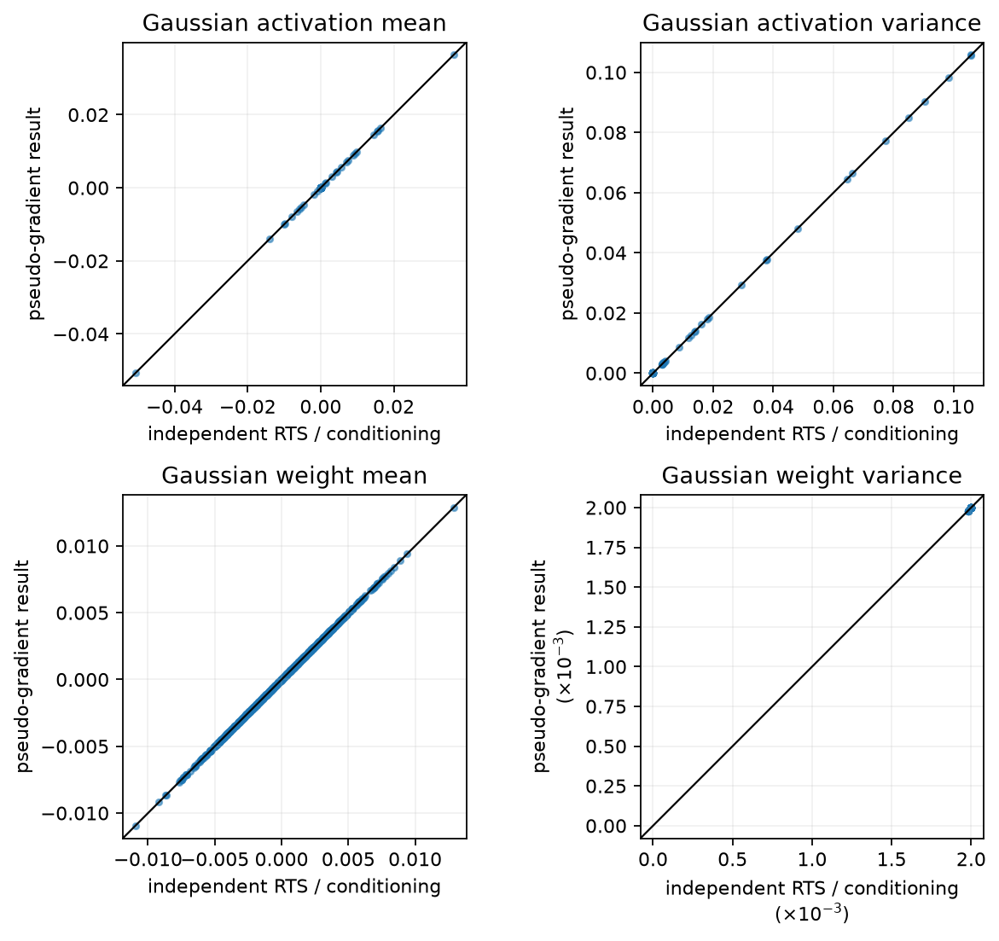

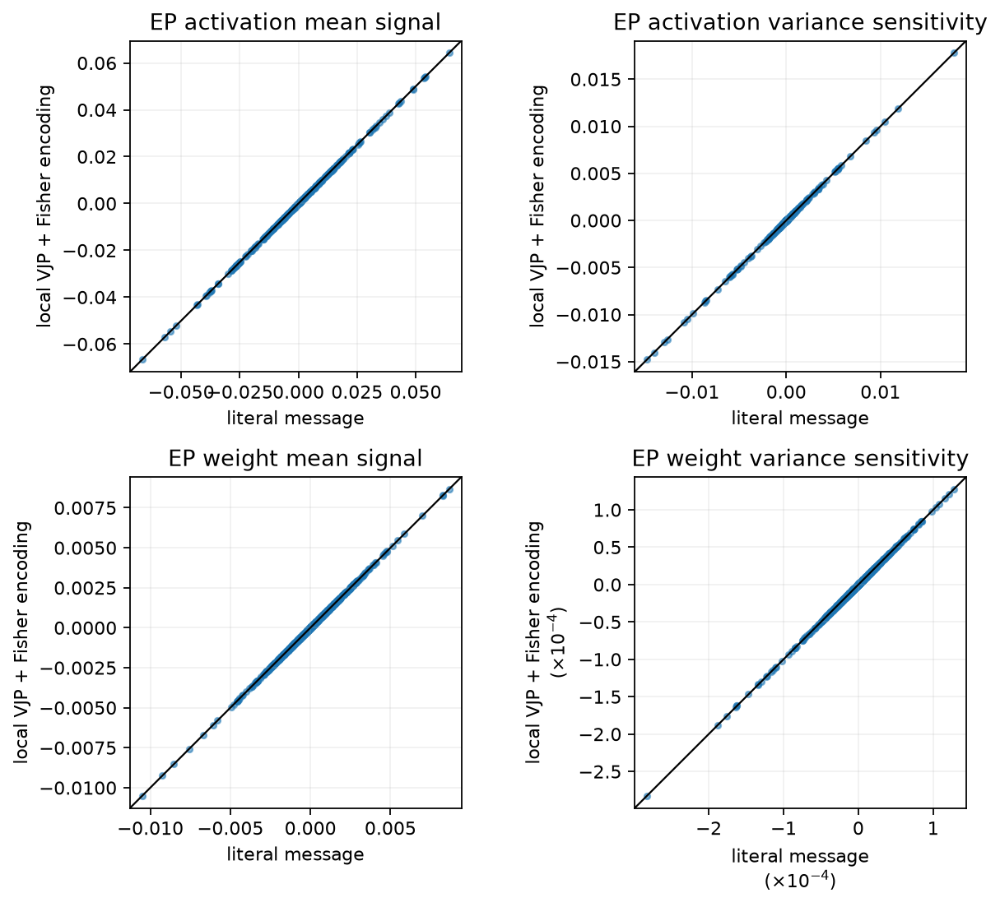

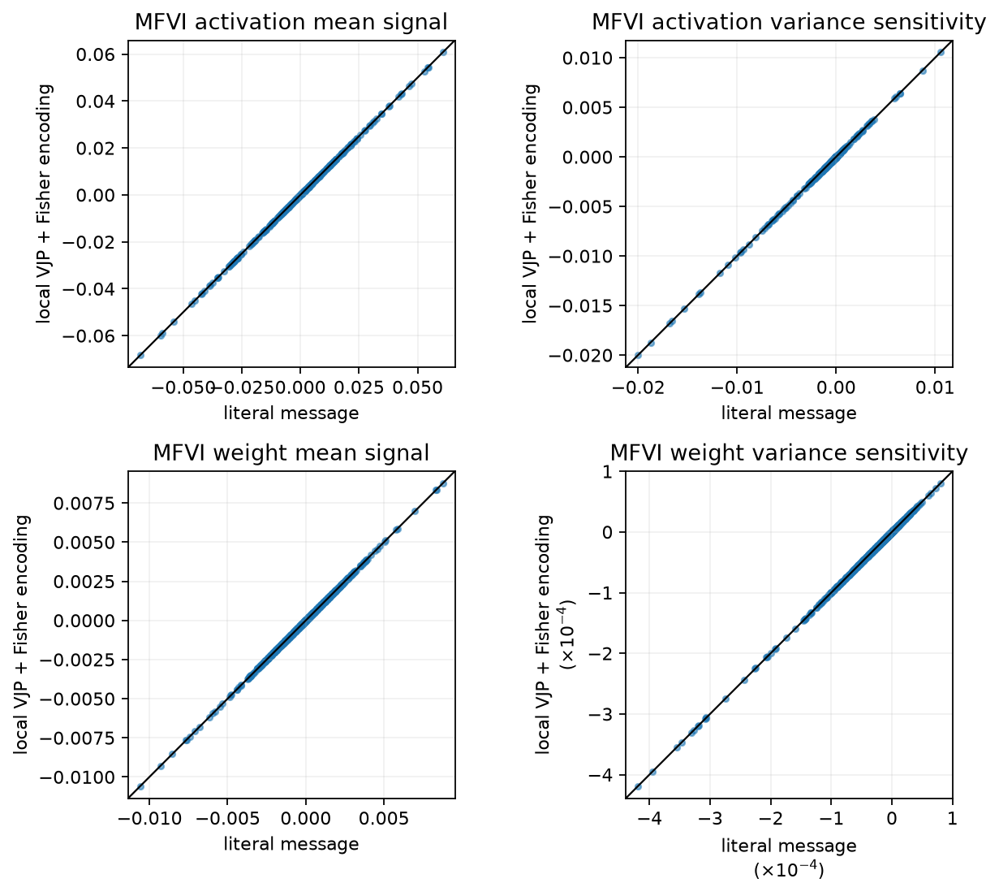

In [28]:
if RUN_SEMANTICS:
    comparison=experiments.exact_equivalence('results/semantics')
    nonlinear=experiments.nonlinear_equivalence('results/semantics')
else:
    import json
    comparison=json.loads(pathlib.Path('results/semantics/equivalence.json').read_text())
    nonlinear=json.loads(pathlib.Path('results/semantics/nonlinear_equivalence.json').read_text())
display(pd.DataFrame(comparison))
display(pd.DataFrame(nonlinear))
for name in ['gaussian_equivalence','ep_nonlinear_equivalence','mfvi_nonlinear_equivalence']:
    display(Image(filename=f'results/semantics/{name}.png'))

The identity line is the target. The exact Gaussian and explicit-site tables use independent
inference references. The EP/MFVI plots instead use a **64 → 12 → 8 → 10 ReLU moment MLP**:
they compare handwritten layer messages with local VJPs of the same declared nonlinear closure.
The mean signal is $v\partial\Phi/\partial m$; variance sensitivity is
$2v^2\partial\Phi/\partial v$. These are backward signals, not posterior variances.
Their agreement validates message transport, not exact nonlinear Bayesian inference.
The different covariance targets of diagonal EP and MFVI remain mathematically different.

## 3. Correlation, Monte Carlo fidelity, and computation

The main accuracy refinement in this section is **sampling-assisted moment
propagation**: integrate a frozen Gaussian surrogate, then use paired network
draws to estimate its nonlinear remainder. The weight belief stays one Gaussian.
The correction is stochastic; it is not the uncorrected 64-direction closure.

Read the residual identity and native implementation first, then the corrected
messages against Monte Carlo. The retained-direction plots are **ablations**:
they explain why covariance retention alone is insufficient. The exact Gaussian,
EP and MFVI message-equivalence checks in Section 2 retain their separate role.

The layers accept diagonal moments or shared covariance directions. A shared direction keeps its identity
through residual additions, concatenations, layers, and examples. Correlated weights, represented by a
diagonal residual plus low-rank factors, are a separate modeling choice.

### Shared factors on a directed acyclic computation graph

Write a boundary as $h\approx m+U\epsilon/\sqrt R$, $\epsilon\sim N(0,I_R)$.
The same columns represent the same latent perturbations at every use of that
boundary. The covariance is $UU^\top/R$; it is never necessary to allocate
this full matrix for a convolutional feature map or a token sequence.
For a local map $y=f(h,w)$, first-order propagation gives
$U_y=J_hU_h+J_wU_w$ and $m_y=f(m_h,m_w)$.
The JAX carrier computes these actions locally, not an enormous global Jacobian. In code, factor columns are stored on the leading axis; transpose them to match the column-oriented equations here.

**Residual proposition.** For $y=x+G(x)$, the represented covariance is
$(U_x+U_G)(U_x+U_G)^\top/R$. Expanding gives the two marginal covariances
and both cross terms. If $G(x)=x$, it is $4C_x$; replacing the branches by
independent copies gives $2C_x$. For DenseNet concatenation, stack the factors
to obtain a block covariance with off-diagonal block $U_xU_G^\top/R$.
Both statements follow directly by multiplying the stacked/summed factors. ∎

This is a computation DAG with repeated use, not a claim that all neural
posterior factors form an exact junction tree. Reverse traversal sums
sensitivities; cavity removal concerns likelihood sites. These are related
bookkeeping issues, but not interchangeable operations.

### A diagonal weight posterior can induce strongly correlated activations

For fixed $x$, $y=W^\top x+b$ with independent weight columns has diagonal
output covariance. But for uncertain shared input $X$, independent of the
current weight block, total covariance yields
\[
E[y]=M_W^\top m_X+m_b,\qquad
\operatorname{Cov}(y)=M_W^\top C_XM_W+
\operatorname{Diag}\{V_W^\top(\operatorname{diag}C_X+m_X^2)+v_b\}.
\]
**Proof.** Conditional on $X$, the mean is $M_W^\top X+m_b$ and covariance
is diagonal with entries $\sum_iV_{ij}X_i^2+v_{b_j}$. Average the latter and
add the covariance of the conditional mean. ∎

After one mixing layer, $M_W^\top C_XM_W$ is generally dense. In convolution,
the same filter is reused at every position. Independent weight draws per
pixel would be a different model. The global column identifiers in the
implementation preserve reuse across pixels and examples.

### Nonlinear closure: Gaussian ReLU means and the omitted Hermite residual

For $X\sim N(m,s^2)$, put $a=m/s$, $P=\Phi(a)$ and $p=\phi(a)$.
Integrating over $X>0$ gives $E[\max(X,0)]=mP+sp$ and
$E[\max(X,0)^2]=(m^2+s^2)P+msp$. These follow by substituting
$X=m+sZ$, using $\int_{-a}^\infty z\phi(z)dz=\phi(a)$ and
$\int_{-a}^\infty z^2\phi(z)dz=\Phi(a)-a\phi(a)$.
At $s=0$, use the deterministic value—no invented input noise.

Gaussian integration by parts gives $\operatorname{Cov}(X,\operatorname{ReLU}X)
=s^2P$. Hence the first linear/Hermite projection has slope $P$.
For jointly Gaussian inputs its retained covariance is
$\operatorname{Diag}(P)C\operatorname{Diag}(P)$.
The remaining diagonal variance is nonnegative by orthogonal projection:
$v_{\mathrm{ReLU}}-P^2s^2\ge0$. A diagonal-plus-factor closure may retain
this residual separately. The minimal shared-factor implementation here
retains the first component and **does not claim exact ReLU variance**.
Its omission is an explicit ablation against diagonal marginal matching and
complete-network sampling.

### What a finite covariance sketch guarantees

For diagonal weight variance $V$, choose fixed sign columns $e_r$ and
$U_r=J V^{1/2}e_r$. For independent Rademacher signs,
$E[U_rU_r^\top]=JVJ^\top$. For a scalar projection put
$b=V^{1/2}J^\top a$. Expanding fourth moments gives
$\operatorname{Var}((b^\top e)^2)=2(\|b\|^4-\sum_i b_i^4)$,
so the relative root-mean-square error of the averaged directional variance
is at most $\sqrt{2/R}$. The fourth-moment expansion retains only indices
paired an even number of times; its coefficients are 1 for $b_i^4$ and 6 for
$b_i^2b_j^2$. Subtracting $\|b\|^4$ proves the formula.

These are fixed-belief guarantees. Fitting a model to a fixed sketch can adapt
to its directions, so an independent sketch and sampled posterior prediction
are required after fitting. A low-rank covariance sketch of diagonal weights
is also **not** a learned low-rank weight posterior.

Here is a concrete reason for that qualification. Take weight covariance
$I_P$ and one fixed sign vector $e\in\{-1,+1\}^P$. If a fitted scalar map
has sensitivity $a=e/\sqrt P$, its actual variance under fresh Gaussian
weight perturbations is $a^\top I_Pa=1$, whereas the one-direction estimate
is $(a^\top e)^2=P$. Both equalities follow from $e^\top e=P$.
The usual unbiasedness argument holds when $a$ is fixed independently of
the random probe; it cannot be reapplied after choosing $a$ from that probe.
This linear counterexample explains why retaining covariance and satisfying
the local derivative identities do not alone guarantee trained-belief fidelity.
It is a possible mechanism to investigate, not proof that it caused a particular
experimental discrepancy. Independent-direction and shared-network checks distinguish that question from ordinary sampling variability; the small fixture below is not a learned-network diagnosis.

### Why a small number of directions can give a noisy covariance

For a fixed linearization, let $z_r\sim N(0,C)$ independently and
$\widehat C=R^{-1}\sum_r z_rz_r^\top$, with the mean known to be zero.
Then
\[
E\|\widehat C-C\|_F^2
=\frac{(\operatorname{tr}C)^2+\|C\|_F^2}{R}.
\]
**Proof.** Independence makes the variance of the average $1/R$ times that of
one outer product. For entries $i,j$, the Gaussian fourth-moment identity is
$E[z_i^2z_j^2]=C_{ii}C_{jj}+2C_{ij}^2$. Subtract $C_{ij}^2$ to obtain
$\operatorname{Var}(z_iz_j)=C_{ii}C_{jj}+C_{ij}^2$; sum over $i,j$.
For sign sketches $z=Ae$, the fourth moment has the same Gaussian terms minus
$2\sum_k A_{ik}^2A_{jk}^2$, so the displayed expression is an upper bound. ∎

Thus relative root-mean-square covariance error depends on
$\sqrt{[1+(\operatorname{tr}C)^2/\|C\|_F^2]/R}$, not just parameter count.
For $d$ equal-variance independent outputs this is $\sqrt{(d+1)/R}$.
A sketch can preserve shared-variable semantics and still have substantial
finite-direction error. Keeping a diagonal residual, shrinking noisy
off-diagonal entries, or allocating more directions are distinct remedies;
none removes nonlinear closure bias. This explains why the plots compare
rank and sampling uncertainty rather than using “correlated” as a certificate
of accurate covariance.

### Structured weight beliefs: $D+LL^\top$

This is a mathematical extension. The reported reproduction configurations
use diagonal weight beliefs; their correlated **activation** factors do not
change that weight family. A learned structured weight posterior would need
its own objective, updates and full-training evaluation.

A correlated generator is $w=m+D^{1/2}\epsilon+Lz$, with independent standard
Gaussians $\epsilon,z$. Its covariance follows by expanding the outer product
and observing that the two cross expectations vanish. Store $P$ diagonal
entries and $Pr$ factor entries, not a $P\times P$ matrix.
The matrix determinant lemma gives
$\log|D+LL^\top|=\log|D|+\log|I+L^\top D^{-1}L|$;
Woodbury gives its inverse using an $r\times r$ solve. For an isotropic prior
$N(m_0,\sigma_0^2I)$ the Gaussian KL uses
$\mathrm{tr}(D)+\|L\|_F^2$, $\|m-m_0\|^2$, and that determinant.
These identities make structured VI feasible without a dense weight covariance.

Explicitly, with $K=I+L^\top D^{-1}L$,
$C^{-1}=D^{-1}-D^{-1}LK^{-1}L^\top D^{-1}$; multiplying by $D+LL^\top$
verifies the inverse. The determinant identity follows by evaluating the
same block determinant using either Schur complement. Hence, for
$p_0=N(m_0,\sigma_0^2I_P)$,
$\mathrm{KL}(q\Vert p_0)=\tfrac12[(\operatorname{tr}D+\|L\|_F^2+
\|m-m_0\|^2)/\sigma_0^2-P+P\log\sigma_0^2-\log|C|]$.
This follows by taking the expectation of the Gaussian log-density ratio.
It assumes strictly positive diagonal $D$; a singular low-rank-only law
requires separate support analysis.

One column of $L$ can jointly change LoRA factors in several attention blocks.
Block-diagonal $L$ forbids those cross-block correlations; a global $L$ retains
them. If upstream and current-layer weights share $z$, then the current weight
and its incoming activation are correlated. Reusing an independent-layer
moment formula would drop this dependence. Common latent columns handle its
first-order contribution; second-order products need additional moments.

### Error accounting rather than automatic equality claims

Suppose $\|D^2 f\|\le M$ on the relevant neighborhood and
$\delta\sim N(0,C)$. Taylor's remainder satisfies
$\|r(\delta)\|\le M\|\delta\|^2/2$, hence
$\|E f(m+\delta)-f(m)\|\le M\mathrm{tr}(C)/2$.
Let $A=J\delta$. Since
$\operatorname{Cov}(A+r)-\operatorname{Cov}(A)$ is two cross terms plus
$\operatorname{Cov}(r)$, Cauchy–Schwarz bounds its norm by
$2\sqrt{E\|A\|^2 E\|r\|^2}+E\|r\|^2$, with
$E\|r\|^2\le M^2[(\mathrm{tr}C)^2+2\mathrm{tr}(C^2)]/4$.
The Gaussian fourth-moment identity gives the last expression. A local bound
needs a tail term if the Hessian bound holds only locally. ReLU requires
piecewise/crossing analysis rather than pretending it has a bounded classical
Hessian everywhere. Gradient-approximation bounds require bounds on derivatives
of the *loss gradient*, not just good forward moment estimates.

Thus Monte Carlo converges to the learned belief's actual neural distribution;
it need not converge to a fixed Gaussian closure. The plots should reveal the
approximation gap, its depth/rank dependence and its sampling uncertainty.

**Implementation: `covariance.py`**

```python
class Shared(NamedTuple):
    mean:object
    factors:object
    @property
    def variance(self):return jnp.mean(self.factors**2,0)
    @property
    def rank(self):return self.factors.shape[0]

class StructuredGaussian(NamedTuple):
    mean:object
    diagonal:object
    factors:object
    def sample(self,key,samples):
        k1,k2=jax.random.split(key)
        return self.mean+jnp.sqrt(self.diagonal)*jax.random.normal(k1,(samples,)+self.mean.shape,dtype=self.mean.dtype)+jax.random.normal(k2,(samples,self.factors.shape[0]),dtype=self.mean.dtype)@self.factors
    def covariance(self):return jnp.diag(self.diagonal)+self.factors.T@self.factors
    def logdet(self):
        # Matrix determinant lemma: |D+LLᵀ|=|D| |I+LᵀD⁻¹L|.
        A=jnp.eye(self.factors.shape[0])+(self.factors/self.diagonal)@self.factors.T
        return jnp.log(self.diagonal).sum()+jnp.linalg.slogdet(A)[1]
    def solve(self,b):
        # Woodbury, with small rank×rank solve. Requires strictly positive D.
        U=self.factors;A=jnp.eye(U.shape[0])+(U/self.diagonal)@U.T
        return b/self.diagonal-(U.T@jnp.linalg.solve(A,U@(b/self.diagonal)))/self.diagonal

def relu_shared(q):
    y,terms=L.relu_terms(Moments(q.mean,q.variance));positive,s,P,*_=terms
    gate=jnp.where(positive,P,(q.mean>0).astype(q.mean.dtype))
    # First Hermite projection; omitted residual is an explicit approximation.
    return Shared(y.mean,q.factors*gate)

def relu_shared_jvp(primals,tangents):
    # s²=mean(U²), ds=mean((U/s)dU), t=m/s. Differentiate the
    # Gaussian integrals BEFORE evaluating: dE[ReLU]=Phi(t)dm+phi(t)ds,
    # dPhi=(phi(t)dm-t phi(t)ds)/s. This avoids an overflowing 1/s³
    # intermediate times an underflowed Gaussian density in float32 tails.
    q,=primals;dq,=tangents;y=relu_shared(q)
    _,(positive,s,P,p,_,_)=L.relu_terms(Moments(q.mean,q.variance))
    t=q.mean/s;tp=jnp.where(jnp.isfinite(t),t,0)*p
    ds=jnp.mean((q.factors/s)*dq.factors,0)
    gate=jnp.where(positive,P,(q.mean>0).astype(q.mean.dtype))
    mean_gate=jnp.where(positive,P,(1+jnp.sign(q.mean))/2)
    dgate=jnp.where(positive,(p*dq.mean-tp*ds)/s,0)
    dm=mean_gate*dq.mean+jnp.where(positive,p*ds,0)
    return y,Shared(dm,gate*dq.factors+q.factors*dgate)

def shared_local(node,parents,beliefs,noise,statistics=None,training=False):
    """One closure per layer; the same weight noise IDs are used on every branch."""
    from .gaussian import RootMoments
    if node.kind=='relu':return relu_shared(parents[0])
    if node.kind=='readout':
        x=parents[0];w,b=beliefs;U=x.factors@w.mean
        noise_variance=(x.mean*x.mean+x.variance)@w.variance+b.variance
        # Preserve the Gram factor plus independent diagonal noise. Forming a
        # dense, nearly rank-one C first can erase its small eigenvalues.
        root=jnp.concatenate((U.transpose(1,2,0)/jnp.sqrt(x.rank),jax.vmap(jnp.diag)(jnp.sqrt(noise_variance))),-1)
        return RootMoments(x.mean@w.mean+b.mean,root)
    qs=tuple(Shared(q.mean,jnp.sqrt(q.variance)*e) for q,e in zip(beliefs,noise))
    if node.kind=='norm' and training:
        def f(x,g,b):
            m=x.mean(tuple(range(x.ndim-1)));v=((x-m)**2).mean(tuple(range(x.ndim-1)))
            return (x-m)*jax.lax.rsqrt(v+1e-5)*g+b
    elif node.kind=='maxpool':
        f=lambda x:jax.lax.reduce_window(x,-jnp.inf,jax.lax.max,(1,2,2,1),(1,2,2,1),'VALID')
    else:
        f=lambda *values:local_map(node,statistics)(*(Moments(z,jnp.zeros_like(z)) for z in values)).mean
    return push(f,parents+qs)

def structured_kl(q,prior_mean,prior_variance):
    # KL(N(m,D+UUᵀ)||N(m0,diag(v0))) with O(P r²+r³), no dense P² matrix.
    trace=jnp.sum((q.diagonal+jnp.sum(q.factors*q.factors,0))/prior_variance)
    quadratic=jnp.sum((q.mean-prior_mean)**2/prior_variance)
    return .5*(trace+quadratic-q.mean.size+jnp.log(prior_variance).sum()-q.logdet())
```

### What the approximation errors measure

For $S$ complete-network draws shared across diagnostic inputs, compute
$\widehat m=S^{-1}\sum_s f_{W_s}(X)$ and
$\widehat v=S^{-1}\sum_s(f_{W_s}(X)-\widehat m)^2$.
This is the empirical central second moment used in the saved arrays. Multiplying
by $S/(S-1)$ gives the usual unbiased variance for independent draws; antithetic
nodes instead require the independent-group uncertainty calculation below.
A relative discrepancy is $\|\widehat t-t_{\rm ref}\|_2/\|t_{\rm ref}\|_2$.
When the reference norm is zero, report the absolute discrepancy instead;
an arbitrary denominator floor is not a relative-error guarantee.
For independent batches at budget $B$, root-mean-square error is
$[K_B^{-1}\sum_b\|\widehat t_b-t_{\rm ref}\|_2^2]^{1/2}/\|t_{\rm ref}\|_2$.
Pointwise $\pm1.96$ MC standard-error bars, when displayed, concern the finite
reference estimator, not the learned posterior or the approximation's bias.
An independent repeat checks stability; it is not itself a confidence interval.
All comparisons must use the same objective, sum/average normalization,
coordinate system, weight belief and set of reported coordinates.

### Sampling-assisted moment propagation: integrate the nonlinear remainder

Use the Gaussian moment calculation as a control variate, and sample the part
that its nonlinear approximation omits. This retains a single Gaussian weight
belief while providing a measurable accuracy refinement for its messages.

Write $W=m+\sqrt v\odot\epsilon$, with standard-normal density $\phi$.
Freeze the linear logit approximation
$z_0(W)=f(m_*)+J_*(W-m_*)$ at the current snapshot. Let $h=\log p$ for
MFVI and $h=p$ for EP, and let $h_0$ apply the same likelihood to $z_0$.
For an integration proposal $r$ and its known weight $a=\phi/r$,
$E_\phi h=E_\phi h_0+E_r[a(h-h_0)]$.
The proof is the cancellation
$\int\phi h_0+\int r(\phi/r)(h-h_0)=\int\phi h$.
Differentiating under the integral, for integrable derivatives and fixed
surrogate/proposal coefficients, gives the identical decomposition for
$\partial_m E h$ and $\partial_v E h$. Pairing both paths with the same noise gives
$\operatorname{Var}(h-h_0)=\operatorname{Var}(h)+\operatorname{Var}(h_0)
-2\operatorname{Cov}(h,h_0)$. It reduces variance relative to direct sampling
when $2\operatorname{Cov}(h,h_0)>\operatorname{Var}(h_0)$; the control-variate
identity alone does not guarantee this condition. Importance integration also
depends on the proposal's weighted second moments.

For EP, integrate both $Z=E p$ and $\partial Z$ before dividing by $Z$;
the finite-sample ratio is consistent, not generally unbiased. For MFVI,
integrate $\partial E\log p$ directly. The Gaussian encoding remains
$d_m=v\odot g_m$, $c=2v^2\odot g_v$ and $d_s=2m\odot d_m+c$.
Finite EP and canonical MFVI updates remain distinct, as in the earlier
derivation; the code retains that distinction.

To resolve small derivatives, one may use the following antithetic
importance rule: $r(\epsilon)=\tfrac12\phi(\epsilon)+\tfrac12\phi(\epsilon-\delta)$,
where $\delta=\sqrt v\odot(J_{\rm competitor}-J_y)$ and
$a=2/[1+\exp(\delta^\top\epsilon-\|\delta\|^2/2)]\le2$.
The four nodes $\epsilon,-\epsilon,\delta+\epsilon,\delta-\epsilon$
form one independent integration group. This is an integration proposal;
the weight belief itself stays a single Gaussian.
The frozen surrogate is a function of $W$ anchored at $(m_*,J_*)$: freeze its
coefficients, not the dependence of $W=m+\sqrt v\odot\epsilon$ on the current
belief. Likewise freeze a proposal chosen at that snapshot, and retain all
ratio terms needed for the declared coordinate derivative. A convenient
reparameterized implementation samples $\epsilon$ and uses fixed proposal
coefficients in epsilon space. Stopping the entire surrogate graph would
remove the derivative one is trying to integrate.


**Implementation: `covariance.py`**

```python
def shared_records(nodes,beliefs,x,key,rank,statistics=None,training=False,noise=None):
    # Explicit directions permit the same finite approximation to be compared
    # across frameworks. Different PRNGs are not implementation discrepancies.
    if noise is None:
        keys=jax.random.split(key,len(beliefs))
        noise={n:jax.random.rademacher(k,(rank,)+q.mean.shape,dtype=q.mean.dtype) for (n,q),k in zip(sorted(beliefs.items()),keys)}
    states={'input':Shared(x,jnp.zeros((rank,)+x.shape,dtype=x.dtype))};records=[]
    for node in nodes:
        ps=tuple(states[n] for n in node.parents);ws=tuple(beliefs[n] for n in node.parameters)
        es=tuple(noise[n] for n in node.parameters)
        f=lambda ps,ws,node=node,es=es:shared_local(node,ps,ws,es,statistics,training)
        out=f(ps,ws);states[node.name]=out;records.append((node,ps,ws,f))
    return states,records

def shared_likelihood(nodes,beliefs,x,y,key,rank,statistics=None,method='mfvi',power=1.,training=False,noise=None):
    """Explicit local reverse, including shared-parent/weight accumulation.

    A finite rank factor is not a full-rank Gaussian Fisher coordinate. Its
    Euclidean adjoint is transported directly; persistent weights are encoded
    in Gaussian moment coordinates at the boundary.
    """
    from .gaussian import encode
    from .heads import categorical_nodes,categorical_objective
    states,records=shared_records(nodes,beliefs,x,key,rank,statistics,training,noise)
    objective=lambda q:categorical_objective(categorical_nodes(q),y,method,power)
    value,d=jax.value_and_grad(objective)(states[nodes[-1].name]);pending={nodes[-1].name:d};weight={}
    def accumulate(table,name,value):
        table[name]=value if name not in table else jax.tree_util.tree_map(lambda a,b:a+b,table[name],value)
    for node,ps,ws,f in reversed(records):
        _,pull=jax.vjp(f,ps,ws);dp,dw=pull(pending[node.name])
        for n,g in zip(node.parents,dp):accumulate(pending,n,g)
        for n,g in zip(node.parameters,dw):accumulate(weight,n,g)
    return value,weight,pending,{n:encode(beliefs[n],g) for n,g in weight.items()}

def residual_integral(f,surrogate,gaussian_value,epsilon):
    # Exact control-variate identity E f = E surrogate + E(f-surrogate).
    # Coefficients/proposal are fixed, but parameter dependence through f remains.
    return gaussian_value+jax.vmap(lambda e:f(e)-surrogate(e))(epsilon).mean(0)
```

<details><summary>Implementation: `residual.py`</summary>

```python
def residual_backward(q,gaussian,nonlinear,surrogate,weight,method='mfvi'):
    """Rows are integration draws; gm/gv are pathwise LOG-likelihood derivatives."""
    a=j.exp(nonlinear['log_likelihood']) if method=='ep' else j.ones_like(weight)
    b=j.exp(surrogate['log_likelihood']) if method=='ep' else j.ones_like(weight)
    gm=gaussian['gm']+j.mean(weight[:,None]*(a[:,None]*nonlinear['gm']-b[:,None]*surrogate['gm']),0)
    gv=gaussian['gv']+j.mean(weight[:,None]*(a[:,None]*nonlinear['gv']-b[:,None]*surrogate['gv']),0)
    Z=gaussian['Z']+j.mean(weight*(j.expm1(nonlinear['log_likelihood'])-j.expm1(surrogate['log_likelihood']))) if method=='ep' else j.asarray(1.,q.mean.dtype)
    gradient=Moments(gm/Z,gv/Z)
    return gradient,encode(q,gradient),Z
```

</details>

In [37]:
if RUN_SEMANTICS:
    fidelity=experiments.approximation_study('results/semantics',samples=16384)
else:
    import json
    fidelity=json.loads(pathlib.Path('results/semantics/approximation.json').read_text())
display(pd.DataFrame(fidelity['rows']).round(6))

,scheme,forward_seconds,compile_seconds,mean_relative_error,covariance_relative_error,mfvi_mean_relative_error,mfvi_second_relative_error,mfvi_centered_relative_error,mfvi_forward_backward_seconds,ep_mean_relative_error,ep_second_relative_error,ep_centered_relative_error,ep_forward_backward_seconds
0,diagonal,0.000240,0.506353,0.007987,0.036132,0.011706,0.014884,0.106628,0.001104,0.009033,0.012874,0.129576,0.001200
1,shared rank 4,0.000253,1.639231,0.059455,0.163989,0.108419,0.102268,0.745048,0.000930,0.104135,0.100432,0.965119,0.000828
2,shared rank 16,0.000220,1.632865,0.080509,0.083278,0.067067,0.063129,0.408337,0.000870,0.066324,0.061885,0.498603,0.000989
3,shared rank 64,0.000266,1.584635,0.026047,0.084279,0.031315,0.033807,0.259517,0.001229,0.030939,0.032927,0.316242,0.001135


This study uses a common nonlinear Gaussian-weight belief and 16,384 complete-network draws. The
backward comparison differentiates the same MFVI expectation or EP log normalizer with respect to the
same Gaussian mean/variance coordinates, then encodes both as moment signals. It does not compare a
sampled point-weight gradient directly with a pseudo-gradient.

Increasing rank reduces covariance-sketch error, but does not restore omitted nonlinear Hermite terms.
Accordingly, rank need not improve every error monotonically. These plots measure approximation quality
and execution cost on a small fixture; classification performance is measured separately below.

This small ablation uses `shared_forward`: it sketches every affine map, including
the readout. The trained CNN path uses `shared_records`, whose Gaussian readout
adds the exact conditional weight-noise term to the retained hidden covariance.
The learned-ResNet comparison later in this section uses that trained path. These are
declared readout choices within the common layer implementation, not separate
EP and MFVI layer libraries.

**Correcting nonlinear residuals.** The identity above also supplies a direct
accuracy control: integrate the Gaussian surrogate, then estimate the difference
between the nonlinear network and that surrogate with shared draws. This example
uses 32,768 independent reference draws. The table counts actual nonlinear
evaluations, including antithetic and shifted evaluations. Execution timings in
the saved record have different setup boundaries, so no speedup is inferred from
them. At finite budgets, direct sampling and residual integration both retain MC error.

In [40]:
if RUN_SEMANTICS:
    residual=experiments.residual_study('results/semantics',samples=32768)
else:
    import json
    residual=json.loads(pathlib.Path('results/semantics/residual.json').read_text())['rows']
display(pd.DataFrame(residual)[['method','scheme','draws','mean_relative_error','centered_relative_error']].round(5))

,method,scheme,draws,mean_relative_error,centered_relative_error
0,mfvi,direct sampling,128,0.06998,0.96550
1,mfvi,direct sampling,512,0.02998,0.40329
2,mfvi,direct sampling,2048,0.01557,0.19954
3,ep,direct sampling,128,0.06867,1.09004
4,ep,direct sampling,512,0.02951,0.43772
5,ep,direct sampling,2048,0.01585,0.21527
6,mfvi,Gaussian + nonlinear residual,128,0.05937,0.83443
7,ep,Gaussian + nonlinear residual,128,0.06258,0.89522
8,mfvi,Gaussian + nonlinear residual,512,0.02925,0.42143
9,ep,Gaussian + nonlinear residual,512,0.02880,0.45443


## Readout variance messages: conditioning before approximation

For an independent Gaussian readout, condition on its hidden input $h$ and
write $z_j=\sum_i W_{ji}h_i+b_j$. The hidden distribution need not be Gaussian.
For a smooth scalar likelihood function $F$, Gaussian integration by parts gives
$\partial_m E[F]=E[\partial_wF]$ and
$\partial_v E[F]=\tfrac12 E[\partial_w^2F]$. Indeed,
$\partial_mq=-\partial_wq$ and $\partial_vq=\tfrac12\partial_w^2q$;
integrating once or twice moves derivatives from the Gaussian density onto
$F$, with vanishing boundary terms. Applying the affine chain rule conditional
on $h$, then averaging over the independent upstream weights, proves
$$\partial_{m_{ji}}E[F]=E[h_i\partial_{z_j}F],\qquad
\partial_{v_{ji}}E[F]=\tfrac12E[h_i^2\partial_{z_j}^2F].$$
Let $p=\operatorname{softmax}(z)$, $r_j=1_{j=y}-p_j$, and
$H_{jj}=-p_j(1-p_j)$. For MFVI, $F=\log p_y$ has derivatives
$r_j,H_{jj}$. For EP, $F=p_y$ has derivatives
$p_y r_j,p_y(H_{jj}+r_j^2)$. Average the EP derivatives and $p_y$ separately,
then divide by $Z=E[p_y]$. Averaging log-probability derivatives instead would
change the objective to MFVI. Encode the resulting adjoints as
$d_m=v\odot g_m$ and $d_s-2m\odot d_m=2v^2\odot g_v$.

This readout identity avoids the often noisy pathwise variance estimator
$E[(\partial_wF)\epsilon/(2\sqrt v)]$. Both estimate the same derivative
under their regularity assumptions; their finite-sample variances differ.
The independent affine readout assumption is essential: correlated upstream
and readout weights need their joint conditional calculation.

The paired residual identity can be applied to these derivatives too:
$E_q[A]=E_q[A_0]+E_r[(q/r)(A-A_0)]$, where $A_0$ is a frozen surrogate
and the two paths use the same perturbation. EP corrects its normalizer and
unnormalized derivatives before division. A finite-sample EP ratio remains
biased; agreement with this identity does not prove exact finite-sample EP.
This is an integration refinement within a single Gaussian belief, not a
new optimizer or a mixture posterior. Forward covariance retention and
nonlinear head integration should be assessed separately.

**Follow the implementation:**

`src/bayesify_jax/heads.py`: `sampled_readout_adjoint`


## Conditional readout: implementation

**Implementation: `heads.py`**

```python
def sampled_readout_adjoint(features,logits,label,method='mfvi'):
    """Independent MC reference for a Gaussian last-layer weight block.

    Conditional on hidden h, z=h W+b is affine in independent Gaussian W.
    Price: d_v E[f]=E[d_W² f]/2; d_m E[f]=E[d_W f]. For log softmax,
    r=e_y-p and diag(H)=-p(1-p). For f=p_y, multiply by p_y and
    replace diag(H) by diag(H)+r². EP divides averaged dZ by averaged Z
    AFTER all samples. The hidden features need not have a Gaussian law.
    Returns per-network values and ordinary (mean, variance) adjoints.
    """
    logp=jax.nn.log_softmax(logits,-1);p=jnp.exp(logp)
    r=jax.nn.one_hot(label,p.shape[-1],dtype=p.dtype)-p;diagonal=-p*(1-p)
    if method=='mfvi':value=logp[:,label];scale=jnp.ones_like(value)
    elif method=='ep':
        value=p[:,label];scale=value;diagonal=diagonal+r*r
    else:raise ValueError(method)
    h=features[:,:,None];a=scale[:,None,None]
    return value,Moments(a*h*r[:,None,:],.5*a*h*h*diagonal[:,None,:])
```

### What the R/TensorFlow repair established

The earlier R/TensorFlow experiment applied this residual correction to 236
selected parameter coordinates spanning the ResNet-20 blocks. On the first of
four predeclared CIFAR-10 inputs, 2,048 correction evaluations were compared with
an independent 8,192-network reference. Relative errors were:

| Method | Mean signal: baseline → corrected ↓ | Raw-second signal: baseline → corrected ↓ |
|---|---:|---:|
| MFVI | 68.30% → 4.64% | 68.09% → 4.34% |
| EP | 50.29% → 9.09% | 52.13% → 9.14% |

Mean and raw-second errors decreased on all four inputs. This is the successful
sampling-assisted repair; it is not evidence that a 64-direction closure alone
is accurate. The raw-second signal is $d_s=2m\odot d_m+c$, whereas the centered
variance signal is $c=2v^2\odot g_v$. A large mean contribution can hide errors
in $c$. In this earlier experiment the corrected centered-signal error was about
133% for both methods, with very large MC uncertainty. The readout experiment
below therefore checks mean and centered variance separately with a larger,
independent reference. The two studies have different coordinates and references;
their percentages are not a common learning curve.

The source CSV, including every input and its MC standard error, is
`r_residual_confirmation.csv` in the supplied matched evidence. These are recorded
R/TensorFlow results, not newly executed full-network experiments in every backend.

## Sampling-assisted readout messages against Monte Carlo

Keep the learned ResNet-20 MFVI or EP belief and CIFAR-10 test input 0 fixed.
An independent **524,288-network** reference measures mean and centered-variance
signals, $d_m=v\odot g_m$ and $c=2v^2\odot g_v$. These are backward sensitivities,
not posterior variances. Both plot axes use the same units and scale; the diagonal
is ideal agreement.

The first figure shows the paired residual correction at 4,096 and 16,384
evaluations. The next two figures are closure ablations: forward variance against
MC, then forward/backward error versus retained directions. They do not represent
the repaired method. Antithetic-group reference standard errors are about 0.25%
for logit variance, 0.88%/0.75% for MFVI mean/variance signals and 2.31%/1.39% for EP.

The residual readout values and complete-network reference were computed in
PyTorch and are shared numerical evidence across the readers. Each framework
renders its own plots. The closure ablations use independently computed native
backend values: 80 checks agree within $1.82\times10^{-13}$ in float64.
Implementation agreement does not imply approximation accuracy. The selected-
coordinate R study above and this readout-only study establish different scopes;
neither establishes a matched all-layer corrected training run in all three backends.


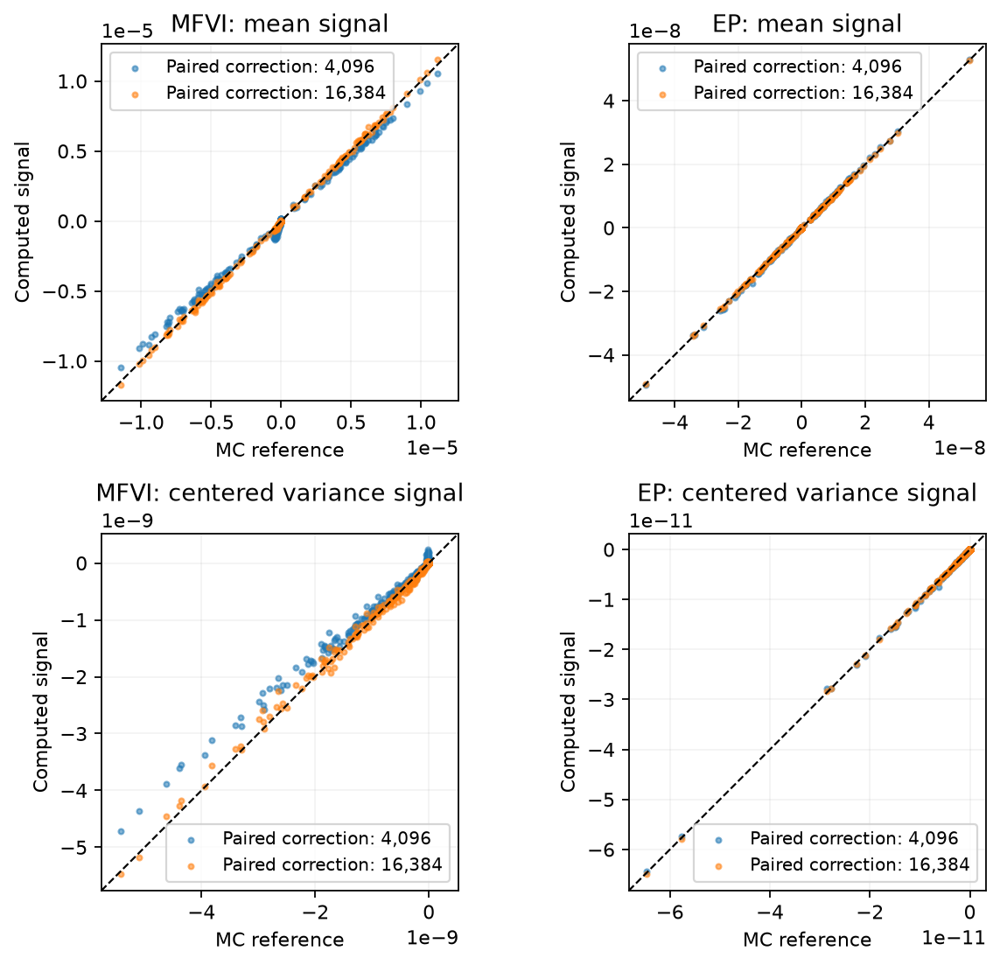

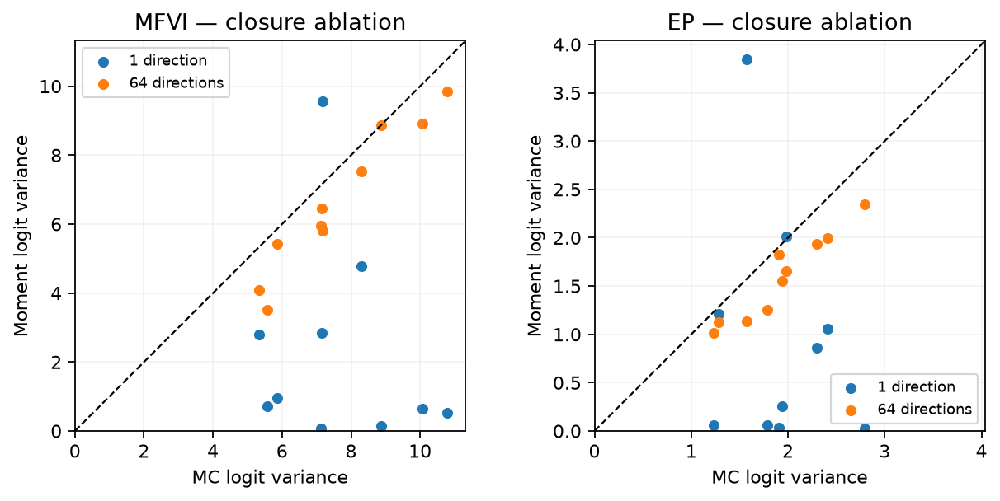

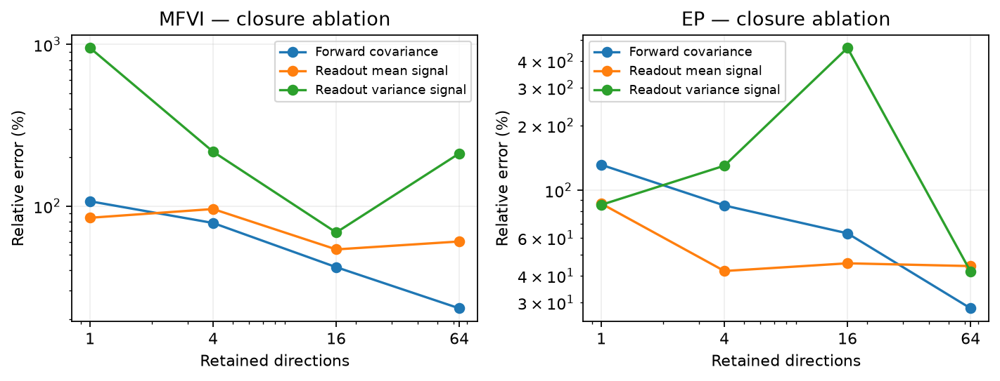

In [45]:
import importlib.util
spec=importlib.util.spec_from_file_location('matched_comparison',ROOT/'matched/compare_approximations.py')
matched=importlib.util.module_from_spec(spec);spec.loader.exec_module(matched)
comparison=matched.compare();matched.figures(comparison,backend='jax')
for name in ('readout_agreement','forward_agreement','covariance_and_message_error'):
    display(Image(filename=str(matched.ROOT/(name+'.png'))))

### Accuracy and measured work

| Readout calculation | MFVI mean / variance error ↓ | EP mean / variance error ↓ |
|---|---:|---:|
| Uncorrected 64-direction closure (ablation) | 60.30% / 211.49% | 44.37% / 41.83% |
| Paired correction: 4,096 evaluations | 10.1% / 17.2% | 2.73% / 2.09% |
| Paired correction: 16,384 evaluations | 2.79% / 5.85% | 0.98% / 0.97% |
| Paired correction: 65,536 evaluations | 1.45% / 2.92% | 1.29% / 0.70% |

The correction substantially improves readout agreement for both objectives.
Errors near the reference's MC standard error should not be ranked: the last
two EP rows do not establish that fewer evaluations are intrinsically better.

| Correction evaluations | MFVI seconds ↓ | EP seconds ↓ |
|---:|---:|---:|
| 4,096 | 3.75 | 2.06 |
| 16,384 | 9.34 | 7.69 |
| 65,536 | 31.80 | 30.15 |

These saved L4 timings include Jacobian/surrogate preparation and readout
correction. MFVI ran first and paid more setup overhead. They measure one-input
diagnostics, not training or serving. The correction uses float64 and returns
readout derivatives; the original reverse pass returns all weight derivatives.
They therefore do not establish a 2–3× training-cost claim. No benchmark below
has been retrained or credited with this correction.

**Why the closure remains an ablation.** With 64 directions, forward covariance
errors are still 23.3% (MFVI) and 28.2% (EP). Refining only the Gaussian head from
18 nodes to 262,144 Sobol nodes changes mean/variance errors to 49.2%/38.8% and
42.7%/31.6%. Thus neither adding directions nor integrating that approximate
head more accurately removes the missing nonlinear response. The paired residual
directly measures this missing contribution. It is the supported refinement for
this example; its budget and variance accuracy must be measured, not assumed.


## 4. MNIST: MLP and LeNet

The MLP has 478,410 parameters and widths 784 → 400 → 400 → 10. LeNet has 61,706 parameters:
5×5 convolutions with 6/16 channels, pooling, and 120/84/10 dense layers. Gaussian pooling precedes ReLU,
as in the R implementation. Both use full 10×10 readout covariance; moment EP's MLP includes the rank-four
hidden covariance correction. Observed pixels have zero probabilistic variance.

**Implementation: `models.py`**

```python
def mlp(seed=0,inputs=784,width=400,classes=10,**kwargs):
    b=Builder(seed,**kwargs);x=b.add('flatten','flatten','input')
    for i,dim in enumerate((inputs,width),1):
        x=b.add(f'dense{i}','dense',x,shape=(dim,width));x=b.add(f'relu{i}','relu',x)
    b.add('readout','readout',x,shape=(width,classes));return b.finish('MLP')

def lenet(seed=0,classes=10,**kwargs):
    b=Builder(seed,he=True,**kwargs);x='input'
    for i,ci,co,pad in ((1,1,6,2),(2,6,16,0)):
        x=b.add(f'conv{i}','conv',x,shape=(5,5,ci,co),options=(1,pad));x=b.add(f'pool{i}','maxpool',x);x=b.add(f'relu{i}','relu',x)
    x=b.add('flatten','flatten',x)
    for i,ci,co in ((1,400,120),(2,120,84)):
        x=b.add(f'dense{i}','dense',x,shape=(ci,co));x=b.add(f'dense_relu{i}','relu',x)
    b.add('readout','readout',x,shape=(84,classes));return b.finish('LeNet')

def correlated_mlp(model):
    """Rank-four hidden covariance, retaining all original parent adjoints."""
    from dataclasses import replace
    node=model.nodes[-1]
    node=replace(node,kind='correlated_readout',parents=('relu2','relu1','dense2'),parameters=node.parameters+('dense2.weight',))
    model.nodes=model.nodes[:-1]+(node,)
    model.layers[node.name]=MomentLayer(node,{n:model.parameters[n] for n in node.parameters})
    return model
```

**Implementation: `layers.py`**

```python
def max_pair(a,b):
    pos=a.variance+b.variance>0;s=jnp.sqrt(jnp.where(pos,a.variance+b.variance,1))
    t=(a.mean-b.mean)/s;P=ndtr(t);p=jnp.exp(-t*t/2)/math.sqrt(2*math.pi)
    m=a.mean*P+b.mean*(1-P)+s*p
    second=(a.variance+a.mean**2)*P+(b.variance+b.mean**2)*(1-P)+(a.mean+b.mean)*s*p
    return Moments(jnp.where(pos,m,jnp.maximum(a.mean,b.mean)),jnp.where(pos,jnp.maximum(second-m*m,0),jnp.where(a.mean>=b.mean,a.variance,b.variance)))

def max_pool(x):
    a,b,c,d=pool_parts(x)
    return max_pair(max_pair(a,b),max_pair(c,d))

def readout(x,w,b):
    """Exact output covariance under diagonal input and independent weights."""
    mean=x.mean@w.mean+b.mean
    C=jnp.einsum('bi,ic,id->bcd',x.variance,w.mean,w.mean)
    noise=(x.mean*x.mean+x.variance)@w.variance+b.variance
    return FullMoments(mean,C+jax.vmap(jnp.diag)(noise))

def correlated_readout(x,first,pre,w,b,w2,basis):
    # L_b=diag(Phi(pre_m/pre_sd)) W2^T diag(sqrt(v1)) Q.
    sd=jnp.sqrt(jnp.where(first.variance>0,first.variance,1))* (first.variance>0)
    scale=jnp.sqrt(jnp.where(pre.variance>0,pre.variance,1));gate=jnp.where(pre.variance>0,ndtr(pre.mean/scale),(pre.mean>0).astype(pre.mean.dtype))
    U=gate[:,:,None]*jnp.einsum('ih,bir->bhr',w2.mean,sd[:,:,None]*basis[None])
    residual=x.variance-jnp.sum(U*U,-1)
    # Roundoff at zero is allowed; a materially negative residual is diagnosed.
    residual=jnp.maximum(residual,0)
    output=jnp.einsum('ic,bir->bcr',w.mean,U)
    C=jnp.einsum('bi,ic,id->bcd',residual,w.mean,w.mean)+output@jnp.swapaxes(output,-1,-2)
    noise=(x.mean*x.mean+x.variance)@w.variance+b.variance
    return FullMoments(x.mean@w.mean+b.mean,C+jax.vmap(jnp.diag)(noise))
```

### Full readout covariance and a diagonal-plus-factor hidden state

The image benchmarks retain full Gaussian logit covariance. `layers.readout`
implements the affine total-covariance rule below; `layers.correlated_readout`
adds the rank-four hidden correction used in the moment-EP MLP. The general
categorical head also accepts diagonal logits for the simpler teaching examples.

For ten classes the full **10×10 logit covariance** is
$C_z=M\operatorname{Diag}(v)M^\top+\operatorname{Diag}(V(m^{\odot2}+v)+v_b)$.
This follows directly from total covariance, conditioning first on the hidden
activation. Independent readout weights contribute the diagonal term;
uncertain hidden activations contribute correlations between classes.

In the second hidden layer, define
$D=\operatorname{Diag}(\Phi(m_{z_2}/\sqrt{v_{z_2}}))$ and $Q^\top Q=I_4$,
let $L=DM_2\operatorname{Diag}(\sqrt{v_1})Q$. Use
$C_{h_2}=\operatorname{Diag}(v_2-\operatorname{diag}(LL^\top))$
$+LL^\top$.
The retained part is positive semidefinite and the diagonal is unchanged.
Under the Gaussian ReLU closure, the residual is nonnegative: the first
Hermite component contributes at most the total activation variance, and an
orthogonal projection cannot increase its squared row norm. Explicitly,
Gaussian integration gives $\operatorname{Cov}(Z,Z_+)=v\Phi(m/\sqrt v)$;
Cauchy–Schwarz then implies
$\operatorname{Var}(Z_+)\ge v\Phi(m/\sqrt v)^2$.
Together with $QQ^\top\preceq I$ and the nonnegative weight-variance
contribution to $v_{z_2}$, this bounds each retained row norm by $v_2$.
Hold the basis fixed within each reverse pass. For the once-per-epoch refresh
used by the MLP training loop, include the refresh in training time. Backpropagation
includes the covariance correction's dependence on both layer means and
activation variances; it does not differentiate through the basis refresh.



### Contrast-space probability integration

The reported probability is $\bar p(y\mid x)=E_q[p(y\mid x,W)]$.
NLL is $-\log\bar p(y\mid x)$, not an average of sampled losses. Moment
serving factors the covariance of nine logit contrasts and averages softmax
probabilities over 18 symmetric Gaussian cubature nodes. Those are small
head calculations, **not 18 sampled networks**. Explicitly, let
$D=[I_9,-\mathbf 1]$, $a=Dm_z$ and $LL^\top=DC_zD^\top$.
The nodes $a\pm3Le_j$, each with weight $1/18$, have mean $a$ and covariance
$LL^\top$: the signed terms cancel and
$\sum_{j,\pm}(\pm3Le_j)(\pm3Le_j)^\top/18=LL^\top$.
Append a zero tenth logit before softmax; removing a common logit offset leaves
probabilities unchanged. Matching these first two Gaussian moments does not
make integration of nonlinear softmax exact. Sampled serving instead averages
$S$ complete-network probability vectors; each benchmark records $S$.
Both use the same ten classes.

One moment pass performs three affine products in an ordinary hidden layer:
one for the mean, and two for its variance. It also evaluates the nonlinear
moment formulas and the small covariance-aware head. This explains the
additional arithmetic relative to a point forward pass; the reported clocks
measure its actual implementation rather than inferring a speedup from the
number of network passes.

### Complete finite-update recurrences and their state

For the reference Vadam recurrence write $N_{\rm eff}=N/\tau$, prior precision
$p_i=1/v_{0i}$ and $\lambda_i=p_i/N_{\rm eff}$. Here $g$ is the gradient
of the minibatch-average **negative** log likelihood. With moments
$a_i=E[g_i]$ and $b_i=E[g_i^2]$, its temporal state updates are
\[
r_i^+=\beta_1r_i+(1-\beta_1)[a_i+\lambda_i(m_i-m_{0i})],\qquad
s_i^+=\beta_2s_i+(1-\beta_2)b_i.
\]
Then $m_i^+=m_i-\eta\widehat r_i/(\sqrt{\widehat s_i}+\lambda_i)$ and
$v_i^+=1/(N_{\rm eff}s_i^++p_i)$, where hats denote the reference's bias
correction. Its initial $s_i=(v_i^{-1}-p_i)/N_{\rm eff}$ preserves the declared
initial belief variance. This initialization is part of the reproduced
algorithm, not a zero-state Adam replacement.

For sampled MFVI, average $g_i$ and $g_i^2$ separately across complete network
draws. For moment MFVI, the reference uses
$b_i\approx a_i^2+(H\sqrt{\operatorname{Diag}v}\,e)_i^2$ with one fixed
unit-covariance direction and the point-loss Hessian $H$. The executed image
protocol uses Gaussian directions, except for LeNet's Rademacher direction.
To derive the contraction,
linearize $g(w)\approx g(m)+H(w-m)$; independence and $E[ee^\top]=I$ give
$E_e[(H\sqrt{\operatorname{Diag}v}\,e)_i^2]=(H\operatorname{Diag}(v)H^\top)_{ii}$.
A single fixed direction is an approximation to that expectation, not an exact
second moment. This statistic differs from the VI variance derivative and needs
its own validation. The EP optimizer instead consumes the differentiated
cavity likelihood and external field in $(m,\log v)$; it does not replace
posterior variance by Adam's squared-gradient accumulator.

The optional Gaussian-text Vadam path also retains a separate, zero-initialized
likelihood normalization state $u_i^+=\beta_2u_i+(1-\beta_2)b_i$.
When that recorded option is active, the mean denominator uses
$\sqrt{\widehat u_i}+\lambda_i$, while the posterior variance still uses
$1/(N_{\rm eff}s_i+p_i)$. The initial prior-compatible $s_i$ and the temporal
normalizer $u_i$ have different roles. The code records this choice in
`vadam_init(..., likelihood_normalization=True)`; silently identifying these
two states changes the training trajectory even when the sampled gradients
are identical. `vadam_step` handles both states explicitly. The image
experiments use the single-$s$ recurrence. The conditional-Gaussian text
tables use the BLoB split optimizer, not either Vadam variant.
The image curvature refresh frequency is a recorded implementation
choice: one fixed direction, refreshed every four MLP or two LeNet updates,
while mean gradients and EMAs update every minibatch. It is not a theorem that
such stale curvature equals a fresh sampled gradient second moment.

For EP-Adam let $a=\log v$. The ordinary chain rule gives
$g_a=v\odot g_v$. Adam maintains separate first and second temporal
accumulators for $g_m$ and $g_a$ and subtracts their bias-corrected, normalized
steps. These accumulators neither replace the belief variance nor perform EP
site removal. The cavity/field objective supplies EP semantics before Adam.

**Implementation: `training.py`**

```python
class Protocol:
    architecture:str='mlp'
    method:str='moment_mfvi'
    seed:int=41
    epochs:int=40
    batch:int=128
    learning_rate:float=.001
    variance_rate:float=.001
    temperature:float=.01
    samples:int=1
    prediction_samples:int=20
    optimizer:str='vadam'
    weight_decay:float=0.
    rank:int=1
    curvature_refresh:int=4
    correlated_readout:bool=False
    limit_train:int=0
    limit_validation:int=0
    dataset:str="clean"

def protocol(architecture,method,seed=41):
    image=architecture in ('resnet20','densenet40');point=method=='ordinary';mfvi='mfvi' in method
    lr=.003 if image else (3e-4 if architecture=='mlp' and method in ('ordinary','sampled_ep') else .001)
    return Protocol(architecture,method,seed,100 if image else (40 if architecture=='mlp' else 30),125 if image else 128,
        lr,.003 if method=='sampled_ep' and architecture=='mlp' else lr,
        (.01 if method=='moment_ep' else .001) if image else .01,
        4 if method=='sampled_ep' else 1,20,'adamw' if point else ('vadam' if mfvi else 'adam'),
        .005 if image and point else 0.,1,1 if image else (4 if architecture=='mlp' else 2),
        architecture=='mlp' and method=='moment_ep')

def adam_recurrence(q,g,state,lr,vlr,decay=0.,point=False,beta2=.999):
    t,r,s,rv,sv=state;t=t+1;new={};nr={};ns={};nrv={};nsv={}
    for n,p in q.items():
        a=g[n].mean;nr[n]=.9*r[n]+.1*a;ns[n]=beta2*s[n]+(1-beta2)*a*a
        mean=p.mean*(1-lr*decay)-lr*(nr[n]/(1-.9**t))/(jnp.sqrt(ns[n]/(1-beta2**t))+1e-8)
        b=p.variance*g[n].variance;nrv[n]=.9*rv[n]+.1*b;nsv[n]=beta2*sv[n]+(1-beta2)*b*b
        logv=jnp.log(p.variance)-vlr*(nrv[n]/(1-.9**t))/(jnp.sqrt(nsv[n]/(1-beta2**t))+1e-8)
        new[n]=Moments(mean,p.variance if point else jnp.exp(logv))
    return new,(t,nr,ns,nrv,nsv)
```

**Implementation: `inference.py`**

```python
def vadam_step(beliefs,priors,g,g2,state,N,tau,lr,betas=(.9,.99),decay=0.):
    # Variance is inverse curvature; EMA of E[g²] is not (E[g])².
    step,r,s=state[:3];step=step+1;b1,b2=betas;Neff=N/tau;new={};nr={};ns={};nu={}
    for n,q in beliefs.items():
        p=priors[n];lam=1/(p.variance*Neff)
        nr[n]=b1*r[n]+(1-b1)*(g[n]+lam*(q.mean-p.mean))
        ns[n]=b2*s[n]+(1-b2)*g2[n]
        normalization=ns[n]
        if len(state)==4:
            nu[n]=b2*state[3][n]+(1-b2)*g2[n];normalization=nu[n]
        m=q.mean*(1-lr*decay)-lr*(nr[n]/(1-b1**step))/(jnp.sqrt(normalization/(1-b2**step))+lam)
        new[n]=Moments(m,1/(Neff*ns[n]+1/p.variance))
    return new,((step,nr,ns,nu) if len(state)==4 else (step,nr,ns))
```

Each update executes the actual forward/reverse graph. Sampled MFVI uses the gradient's sampled
second moment. Moment MFVI uses a declared Hessian-vector approximation with a cached contribution,
refreshed at the source protocol's interval. EP uses its cavity and external field, followed by the
explicitly labeled Adam mean/log-variance variant. These optimizer choices are separate from the exact
canonical MFVI and explicit-site EP checks in Section 2.

<details><summary>Implementation: `training.py`</summary>

```python
def make_step(model,prior,N,cfg,probes):
    nodes=model.nodes;point=cfg.method=='ordinary';method='ep' if 'ep' in cfg.method else 'mfvi'
    mode='sampled' if cfg.method.startswith('sampled') else 'moment'
    shared=cfg.architecture in ('resnet20','densenet40');direction_key=jax.random.PRNGKey(cfg.seed+7919)
    def likelihood(q,x,y,stats):
        if shared:return covariance.shared_likelihood(nodes,q,x,y,direction_key,cfg.rank,stats,method,training=True)[:2]
        return I.moment_likelihood(nodes,q,x,y,stats,method)[:2]
    def point_loss(w,x,y,stats):
        z,updated=messages.point_forward(nodes,w,x,stats,training=shared)
        return -heads.categorical_objective(z[None],y)/len(y),updated
    def step(state,x,y,rate):
        q=state['belief'];stats=state['statistics'];key,k=jax.random.split(state['key']);weights={n:p.mean for n,p in q.items()}
        cache=state['curvature'];newstats={}
        if point:
            (loss,newstats),g=jax.value_and_grad(point_loss,has_aux=True)(weights,x,y,stats)
            grad={n:Moments(a,jnp.zeros_like(a)) for n,a in g.items()}
        elif method=='mfvi' and cfg.optimizer=='vadam':
            if mode=='sampled':
                ws=I.sample_weights(q,k,cfg.samples)
                (losses,ns),grads=jax.vmap(jax.value_and_grad(point_loss,has_aux=True),in_axes=(0,None,None,None))(ws,x,y,stats)
                loss=losses.mean();g={n:a.mean(0) for n,a in grads.items()};g2={n:(a*a).mean(0) for n,a in grads.items()}
                newstats=jax.tree_util.tree_map(lambda a:a.mean(0),ns)
            else:
                value,gradient=likelihood(q,x,y,stats);loss=-value/len(y);g={n:-a.mean/len(y) for n,a in gradient.items()}
                def curvature(_):
                    d={n:jnp.sqrt(p.variance)*probes[n] for n,p in q.items()}
                    hvp=jax.jvp(jax.grad(lambda w:point_loss(w,x,y,stats)[0]),(weights,),(d,))[1]
                    return jax.tree_util.tree_map(jnp.square,hvp)
                cache=jax.lax.cond(state['updates']%cfg.curvature_refresh==0,curvature,lambda _:cache,operand=None)
                g2={n:a*a+cache[n] for n,a in g.items()}
            q,opt=I.vadam_step(q,prior,g,g2,state['optimizer'],N,cfg.temperature,cfg.learning_rate*rate)
        else:
            if method=='ep':(cavity,A),pull=jax.vjp(lambda q:I.power_cavity(q,prior,N,cfg.temperature),q)
            else:cavity=q;A=0.
            if mode=='moment':value,grad=likelihood(cavity,x,y,stats);grad=jax.tree_util.tree_map(lambda a:-a/len(y),grad);loss=-value/len(y)
            else:
                def sample_loss(q):
                    ws=I.sample_weights(q,k,cfg.samples)
                    logits,ns=jax.vmap(lambda w:messages.point_forward(nodes,w,x,stats,shared))(ws)
                    return -heads.categorical_objective(logits,y,method)/len(y),ns
                (loss,ns),grad=jax.value_and_grad(sample_loss,has_aux=True)(cavity)
                newstats=jax.tree_util.tree_map(lambda a:a.mean(0),ns)
            if method=='ep':loss=loss-A;grad=pull((grad,jnp.asarray(-1.,dtype=A.dtype)))[0]
            else:
                K,dK=jax.value_and_grad(lambda q:I.kl(q,prior))(q);loss+=cfg.temperature/N*K
                grad=jax.tree_util.tree_map(lambda a,b:a+cfg.temperature/N*b,grad,dK)
        if cfg.optimizer!='vadam':
            q,opt=adam_recurrence(q,grad,state['optimizer'],cfg.learning_rate*rate,cfg.variance_rate*rate,cfg.weight_decay,point,
                                 .99 if point and not shared else .999)
        if shared:
            if mode=='moment' and not point:
                states,_=covariance.shared_records(nodes,cavity if method=='ep' else state['belief'],x,direction_key,cfg.rank,stats,training=True)
                for node in nodes:
                    if node.kind=='norm':
                        h=states[node.parents[0]].mean;axes=tuple(range(h.ndim-1));newstats[node.name]=(h.mean(axes),h.var(axes)*(h.size/h.shape[-1])/(h.size/h.shape[-1]-1))
            stats={n:(.9*stats[n][0]+.1*m,.9*stats[n][1]+.1*v) for n,(m,v) in newstats.items()}
        return {'belief':q,'statistics':stats,'optimizer':opt,'curvature':cache,'key':key,'updates':state['updates']+1},loss
    return jax.jit(step)
```

</details>

### Metric definitions and uncertainty decomposition

For posterior draws $w_s$, use $\bar p(y\mid x)=S^{-1}\sum_s p(y\mid x,w_s)$
and predictive NLL $-N^{-1}\sum_n\log\bar p(y_n\mid x_n)$.
The expectation of sampled cross-entropy is a training quantity, not this
predictive NLL. The moment method instead integrates its declared logit
Gaussian; it is a one-moment-pass prediction, not 100 sampled networks charged
to its serving time. Cubature at the small classification head still has cost.

The Brier score is $N^{-1}\sum_n\sum_c(p_{nc}-1\{y_n=c\})^2$.
For bin $B_b$, ECE is $\sum_b |B_b|\,|\mathrm{acc}(B_b)-\mathrm{conf}(B_b)|/N$.
The reliability plot includes counts because a low-occupancy bin is noisy.
ECE depends on binning; it is not a proper scoring rule or a replacement for NLL.

Sort confidence descending; if $e_{(i)}$ is the corresponding 0–1 error,
the selective risk at coverage $k/N$ is $r_k=k^{-1}\sum_{i\le k}e_{(i)}$.
The step-integral AURC is $N^{-1}\sum_k r_k$. Do **not** divide by $N$ again.
Excess AURC subtracts the same error count's oracle ranking, separating ranking
quality from the base error rate. OOD scores use entropy or negative maximum
probability; declare **OOD as the positive class**, report prevalence, AUROC,
AUPRC and FPR at 95% OOD recall. CIFAR-10-C measures corruption robustness;
its severity curves are not automatically an OOD-detection benchmark.

Predictive entropy $H(\bar p)$ combines uncertainties. With actual network
samples, $H(\bar p)-S^{-1}\sum_sH(p_s)$ estimates mutual information with the
sampled weight variable. A moment-head cubature analogue is a quantity for
the represented logit law, not a proof of equality to the full weight mutual
information. Keep those labels distinct.
### Ambiguity is not the same as unfamiliarity

DirtyMNIST combines clean digits with ambiguous images bearing multiple labels.
For one image let $r_c$ be its empirical label frequencies. Any fixed class
prediction gets at most $\max_c r_c$ of those labels right. Its average log
loss is $-\sum_c r_c\log p_c=H(r)+\mathrm{KL}(r\Vert p)\ge H(r)$.
These are finite-label diagnostics, not population Bayes limits. Counting
each label pair is appropriate for classification loss; OOD detection should
count unique images, not duplicate an image for each of its labels.
The native archive here evaluates Fashion-MNIST OOD; it does not contain a
native DirtyMNIST run. Mutual information needs per-network
probabilities, not only their saved average; it is not inferred from the
averaged-probability archives shown below.

**Implementation: `uncertainty.py`**

```python
def uncertainty_metrics(probability: ArrayLike, labels: ArrayLike, bins: int = 15) -> dict[str, float]:
    """Accuracy, proper scores, calibration and selective-prediction metrics."""
    p = _probabilities(probability)
    y = np.asarray(labels, dtype=np.int64)
    if y.shape != (len(p),) or np.any(y < 0) or np.any(y >= p.shape[1]):
        raise ValueError("labels and probability matrix are incompatible")
    n = len(y)
    confidence, prediction = p.max(1), p.argmax(1)
    error = prediction != y
    target = np.eye(p.shape[1], dtype=np.float64)[y]
    table = reliability(p, y, bins)
    ece = np.nansum(table["count"] * np.abs(table["confidence"] - table["accuracy"])) / n
    order = np.argsort(-confidence, kind="stable")
    risk = np.cumsum(error[order]) / np.arange(1, n + 1)
    oracle = np.cumsum(np.sort(error)) / np.arange(1, n + 1)
    detection = ranking_curve(1 - confidence, error)
    at = lambda fraction: float(risk[int(np.ceil(fraction * n)) - 1])
    return {
        "n": float(n),
        "accuracy": float((~error).mean()),
        "nll": float(-np.log(np.maximum(p[np.arange(n), y], 1e-30)).mean()),
        "brier": float(np.square(p - target).sum(1).mean()),
        "ece": float(ece),
        "aurc": float(risk.mean()),
        "excess_aurc": float((risk - oracle).mean()),
        "error_auroc": detection.auroc,
        "error_auprc": detection.auprc,
        "risk80": at(0.80),
        "risk90": at(0.90),
        "risk95": at(0.95),
        "entropy": float(-(p * np.log(np.maximum(p, 1e-30))).sum(1).mean()),
    }

def ood_metrics(id_probability: ArrayLike, ood_probability: ArrayLike) -> dict[str, float]:
    """OOD ranking from entropy and one minus maximum softmax probability."""
    p_id, p_ood = _probabilities(id_probability), _probabilities(ood_probability)
    if p_id.shape[1] != p_ood.shape[1]:
        raise ValueError("ID and OOD predictions must have the same classes")
    entropy = lambda p: -(p * np.log(np.maximum(p, 1e-30))).sum(1)
    positive = np.r_[np.zeros(len(p_id), dtype=bool), np.ones(len(p_ood), dtype=bool)]
    ent = ranking_curve(np.r_[entropy(p_id), entropy(p_ood)], positive)
    msp = ranking_curve(np.r_[1 - p_id.max(1), 1 - p_ood.max(1)], positive)
    return {
        "entropy_auroc": ent.auroc,
        "entropy_auprc": ent.auprc,
        "entropy_fpr95": ent.fpr95,
        "msp_auroc": msp.auroc,
        "msp_auprc": msp.auprc,
        "msp_fpr95": msp.fpr95,
        "id_n": float(len(p_id)),
        "ood_n": float(len(p_ood)),
        "ood_prevalence": float(positive.mean()),
    }
```

<details><summary>Implementation: `plots.py`</summary>

```python
def calibration_plot(probability, labels, bins: int = 15, *, ax=None, label=None):
    """Reliability curve with bin mass shown by marker area."""
    r = reliability(probability, labels, bins)
    if ax is None:
        _, ax = plt.subplots(figsize=(4.4, 4.1))
    ax.plot([0, 1], [0, 1], color="black", lw=1, ls="--")
    valid = r["count"] > 0
    mass = r["count"] / max(r["count"].sum(), 1)
    line, = ax.plot(r["confidence"][valid], r["accuracy"][valid], marker="o", label=label)
    ax.scatter(
        r["confidence"][valid], r["accuracy"][valid], s=30 + 400 * mass[valid], alpha=0.7, color=line.get_color()
    )
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="mean confidence", ylabel="accuracy",
           title="Reliability")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.18)
    if label:
        ax.legend(frameon=False)
    return ax

def risk_coverage_plot(probability, labels, *, ax=None, label=None):
    """Selective risk in descending confidence order, matching metric AURC."""
    probability = np.asarray(probability)
    labels = np.asarray(labels)
    error = probability.argmax(1) != labels
    order = np.argsort(-probability.max(1), kind="stable")
    coverage = np.arange(1, len(error) + 1) / len(error)
    risk = np.cumsum(error[order]) / np.arange(1, len(error) + 1)
    if ax is None:
        _, ax = plt.subplots(figsize=(4.6, 4.0))
    ax.plot(coverage, risk, label=label)
    ax.set(xlabel="coverage", ylabel="selective error", title="Risk-coverage")
    ax.grid(alpha=0.18)
    if label:
        ax.legend(frameon=False)
    return ax

def ood_roc_plot(id_score, ood_score, *, ax=None, label=None):
    """OOD ROC where larger scores denote more uncertainty."""
    score = np.r_[np.asarray(id_score), np.asarray(ood_score)]
    truth = np.r_[np.zeros(len(id_score), dtype=int), np.ones(len(ood_score), dtype=int)]
    curve = ranking_curve(score, truth)
    if ax is None:
        _, ax = plt.subplots(figsize=(4.2, 4.2))
    ax.plot(curve.fpr, curve.tpr, label=label)
    ax.plot([0, 1], [0, 1], color="black", lw=1, ls="--")
    ax.set(xlabel="false-positive rate", ylabel="true-positive rate", title="OOD ROC")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.18)
    if label:
        ax.legend(frameon=False)
    return ax
```

</details>

**Reading the native summaries.** The MLP and LeNet summaries show every
layer; the larger models show selected stage or transformer-block boundaries.
The complete, unfiltered layer summaries and expanded graphs are linked beside
each model. Run the setup cell to activate their Colab download links; the HTML
and PDF use the corresponding files in the extracted supplement. NNX counts stored arrays: Gaussian means and log variances are
trainable arrays, while priors and normalization statistics are additional state.
These totals differ from the number of scalar weights in the mean network.

In [60]:
# Execute the real NNX modules; no pretrained download is needed for inspection.
inspection.all_summaries('assets/architectures')
for name in ['mlp','lenet']:
    print(pathlib.Path(f'assets/architectures/{name}_compact.txt').read_text())
    artifact(f'assets/architectures/{name}.txt','Complete Flax NNX summary: ')
    artifact(f'assets/architectures/onnx/{name}.onnx','Actual graph for Netron: ')
    artifact(f'assets/architectures/netron/{name}.pdf','Expanded graph PDF: ')

                                             MomentModel Summary                                              
┏━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┓
┃ path           ┃ type        ┃ inputs               ┃ outputs        ┃ Param            ┃ Variable         ┃
┡━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━┩
│                │ MomentModel │ x:                   │ float32[1,10]  │ 956,820 (3.8 MB) │ 956,820 (3.8 MB) │
│                │             │ float32[1,28,28,1]   │                │                  │                  │
├────────────────┼─────────────┼──────────────────────┼────────────────┼──────────────────┼──────────────────┤
│ layers/flatten │ MomentLayer │ parent0:             │ float32[1,784] │                  │                  │
│                │             │ float32[1,28,28,1]   │                │                  │                  │
├

<ipython-input-1-fd89ee91a415>:9: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(results.protocol_table(frame,architecture).round(5).fillna('—'))
<ipython-input-1-fd89ee91a415>:9: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(results.protocol_table(frame,architecture).round(5).fillna('—'))


,method,optimizer,learning_rate,log variance / rho LR,point / head decay,KL / external field strength,training samples,conditional_pairs,stochastic prediction passes,epochs,selected_epoch,compile s
18,Moment EP,adam,0.0010,0.001,0.0,0.01,0,0,0,40,35,28.06429
19,Moment MFVI,vadam,0.0010,—,0.0,0.01,0,0,0,40,25,24.77166
20,Ordinary,adamw,0.0003,—,0.0,—,0,0,0,40,10,16.67688
21,Sampled EP,adam,0.0003,0.003,0.0,0.01,4,0,20,40,35,28.78488
22,Sampled MFVI,vadam,0.0010,—,0.0,0.01,1,0,20,40,36,26.39419


,method,Accuracy ↑,NLL ↓,ECE ↓,Brier ↓,AURC ↓,Error AUROC ↑,OOD AUROC ↑,Train s ↓,Train × ↓,Infer s ↓,Infer × ↓
18,Moment EP,0.9856,0.04815,0.00187,0.02227,0.00045,0.97720,0.92786,45.82110,2.25730,0.06223,1.34086
19,Moment MFVI,0.9845,0.04922,0.00209,0.02379,0.00046,0.97893,0.92865,39.26289,1.93422,0.06128,1.32052
20,Ordinary,0.9799,0.06908,0.00578,0.03159,0.00103,0.96423,0.75022,20.29911,1.00000,0.04641,1.00000
21,Sampled EP,0.9826,0.05490,0.00345,0.02582,0.00065,0.97375,0.91973,34.25958,1.68774,0.07899,1.70200
22,Sampled MFVI,0.9845,0.04855,0.00207,0.02300,0.00049,0.97772,0.94823,27.03016,1.33159,0.07590,1.63542


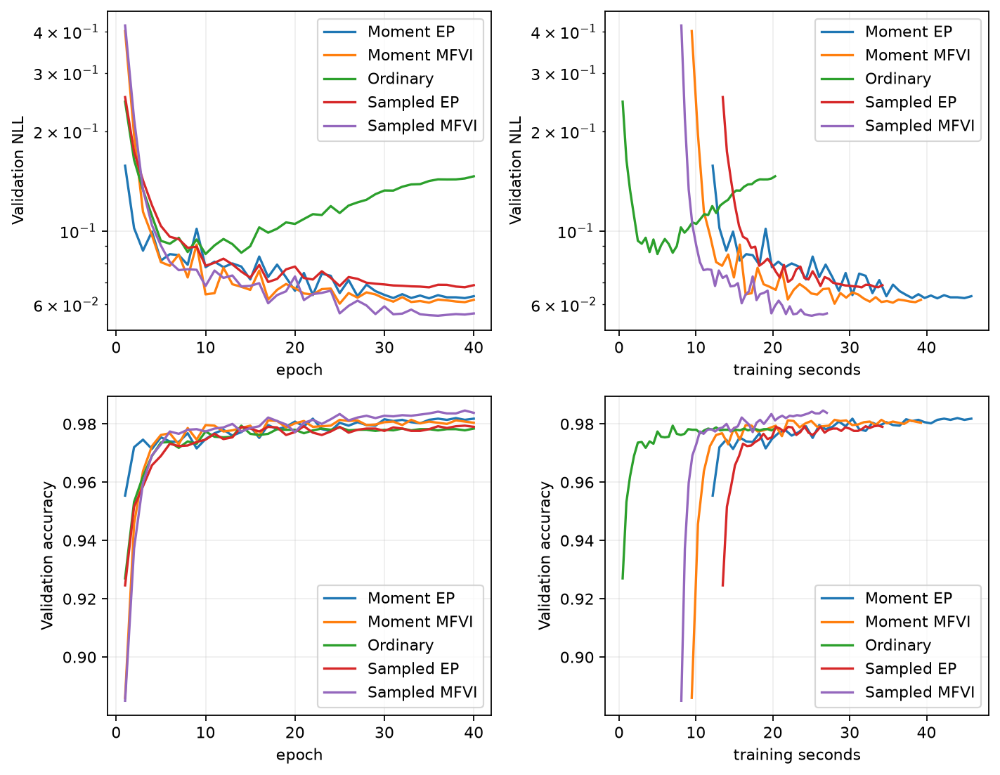

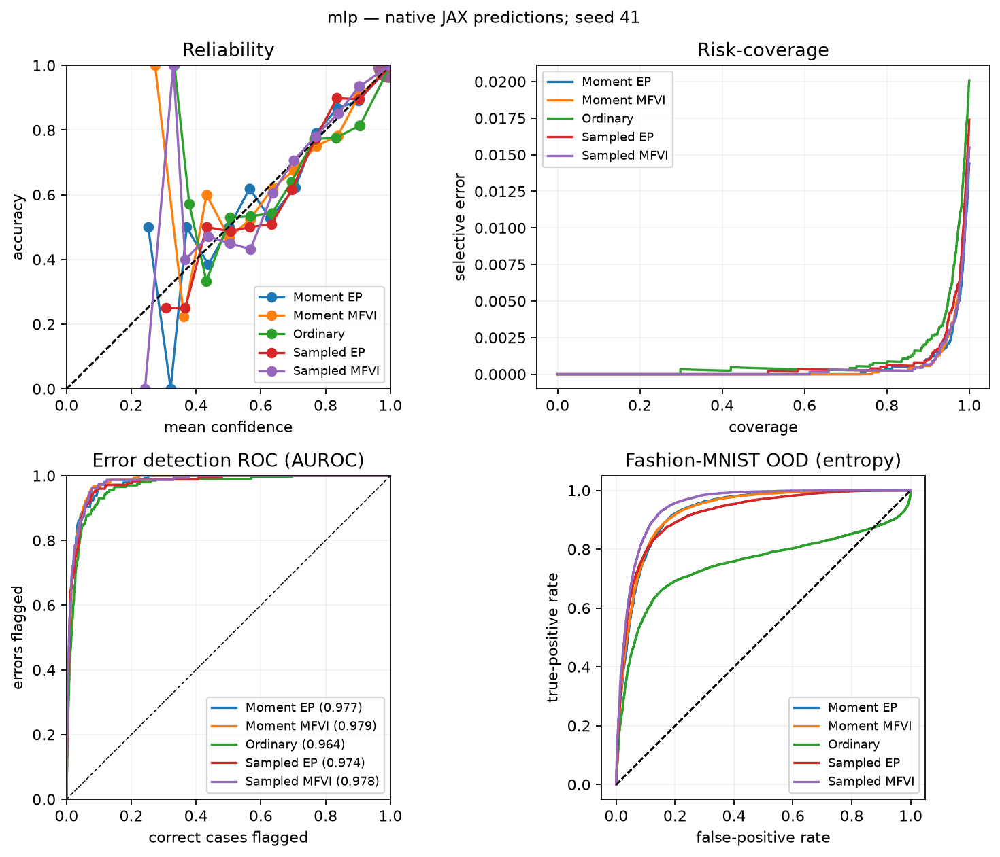

,method,optimizer,learning_rate,log variance / rho LR,point / head decay,KL / external field strength,training samples,conditional_pairs,stochastic prediction passes,epochs,selected_epoch,compile s
8,Moment EP,adam,0.001,0.001,0.0,0.01,0,0,0,30,14,30.97328
10,Moment MFVI,vadam,0.001,—,0.0,0.01,0,0,0,30,24,41.88900
12,Ordinary,adamw,0.001,—,0.0,—,0,0,0,30,8,24.53389
14,Sampled EP,adam,0.001,0.001,0.0,0.01,4,0,20,30,30,39.76529
16,Sampled MFVI,vadam,0.001,—,0.0,0.01,1,0,20,30,24,38.96296


,method,Accuracy ↑,NLL ↓,ECE ↓,Brier ↓,AURC ↓,Error AUROC ↑,OOD AUROC ↑,Train s ↓,Train × ↓,Infer s ↓,Infer × ↓
8,Moment EP,0.9921,0.02559,0.00207,0.01280,0.00016,0.98359,0.98655,58.72217,2.78087,0.08054,1.33301
10,Moment MFVI,0.9930,0.02116,0.00206,0.01075,0.00011,0.98761,0.98077,59.13176,2.80026,0.07770,1.28602
12,Ordinary,0.9893,0.03392,0.00447,0.01649,0.00023,0.98395,0.99277,21.11649,1.00000,0.06042,1.00000
14,Sampled EP,0.9920,0.02503,0.00282,0.01218,0.00014,0.98694,0.98661,41.35134,1.95825,0.12198,2.01879
16,Sampled MFVI,0.9924,0.02127,0.00342,0.01123,0.00010,0.99047,0.98901,32.85111,1.55571,0.12469,2.06374


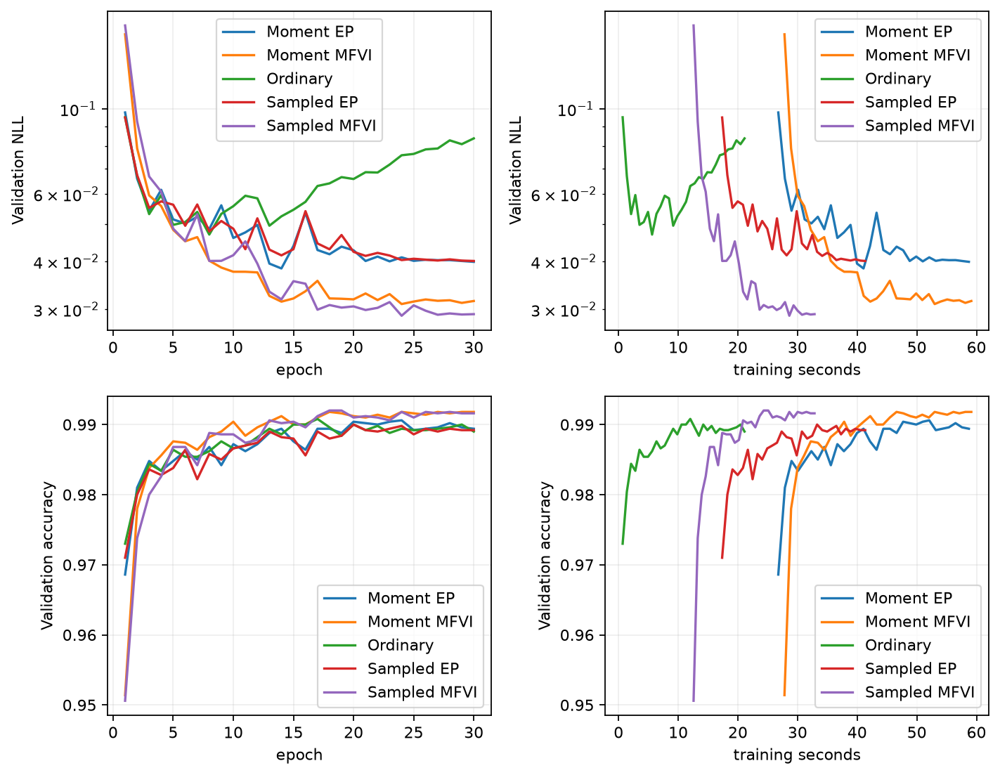

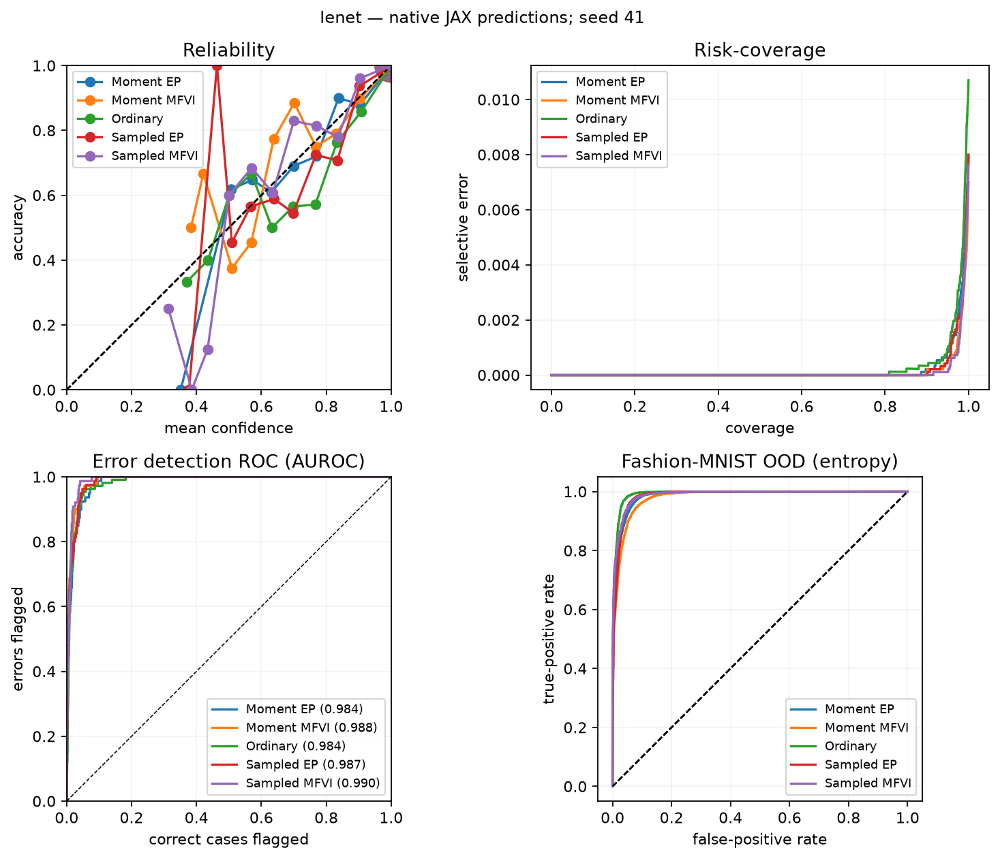

In [61]:
if RUN_MNIST:
    assert DOWNLOAD_PUBLIC_DATA, 'Enable public downloads before a full run.'
    jax.clear_caches();gc.collect()
    subprocess.check_call([sys.executable,'run_image_suite.py','--architectures','mlp','lenet'],env=TRAIN_ENV)
frame=results.plots('results','figures')
if len(frame):
    for architecture in ['mlp','lenet']:
        display(HTML('<h3>'+{'mlp':'MLP / MNIST','lenet':'LeNet / MNIST'}[architecture]+'</h3>'))
        display(results.protocol_table(frame,architecture).round(5).fillna('—'))
        display(results.reader_table(frame,architecture).round(5).fillna("—"))
        for name in ['learning','uncertainty']:
            path=pathlib.Path(f'figures/{architecture}_{name}.png')
            if path.exists():display(Image(filename=str(path)))

**What the MNIST runs demonstrate.** In the saved native runs, both moment MFVI
and moment EP improve accuracy and predictive NLL over the ordinary baseline
for both architectures. Their measured training costs are below three times the
ordinary cost, and one-pass moment prediction is below 1.4 times the ordinary
inference cost. The tables also retain the sampled alternatives, allowing quality
and computation to be compared directly on the same data.

Training uses the fixed original 55,000/5,000 partition and the official 10,000-image test set.
Both MNIST models use batch size 128, with 40 epochs for MLP and 30 for LeNet.
The reported checkpoint is selected on validation NLL. Pre-run compilation is recorded separately; training
time includes the forward pass, reverse pass, update, and any additional first-use compilation after warm-up. Moment prediction uses one moment pass.
Training seconds cover the complete fixed budget; `selected_epoch` identifies the checkpoint evaluated.
Sampled prediction averages class probabilities, with the draw count stored in each run configuration.
One seed is an implementation demonstration, not strong statistical evidence of a universal Bayesian win.
The full native runs use Consumer Colab NVIDIA L4 GPUs and float32 arithmetic.
Some independent methods run on different L4 runtimes; the recorded wall-time
ratios include host overhead and are measurements of these runs, not hardware-independent FLOP ratios.
The protocol table reports the base learning rates before their schedules.
OOD comparisons use Fashion-MNIST for MNIST, SVHN for CIFAR-10, and the official
CLINC out-of-scope test split. SST-2 reports ID error detection rather than an
additional OOD task; its OOD entries are marked with a dash.
Vadam derives variance from its curvature state and has no independent variance learning rate.
Full training runs in fresh processes, separating its recorded float32 protocol
from the reader's float64 mathematical checks. Text training explicitly requests
highest matrix-multiplication precision in its own implementation.
The main table shows the core uncertainty measures; `results/benchmark_table.csv`
also retains AUPRC, FPR95, excess AURC and risks at fixed coverage where defined.

**Dirty-MNIST.** The optional loader uses the authors' ambiguous images and ten labels per image,
without added noise. Splits group repeated images to prevent leakage. Fashion-MNIST is the OOD task;
ambiguous MNIST is an in-domain ambiguity test. They answer different uncertainty questions.

<details><summary>Implementation: `data.py`</summary>

```python
def ambiguous(root='data'):
    root=Path(root);cache=root/'ambiguous.npz'
    if not cache.exists():
        base='https://github.com/BlackHC/ddu_dirty_mnist/releases/download/data-v1.0.0/'
        files=[]
        for name,checksum in [('amnist_samples.pt','4f7865093b1d28e34019847fab917722'),('amnist_labels.pt','3bfc055a9f91a76d8d493e8b898c3c95')]:
            p=download(base+name,root/name)
            if hashlib.md5(p.read_bytes()).hexdigest()!=checksum:raise ValueError('Public data checksum mismatch')
            files.append(tensor_archive(p))
        x,y=files;np.savez_compressed(cache,images=x.transpose(0,2,3,1),labels=y.astype('int32'))
    with np.load(cache) as a:return a['images'],a['labels']

def dirty_mnist(root='data'):
    clean=mnist(root);x,y=ambiguous(root);order=np.random.default_rng(20261107).permutation(6000)
    for name,inds in [('train',order[:5500]),('validation',order[5500:])]:
        cx,cy=clean[name];clean[name]=(np.concatenate((cx,np.repeat(x[inds],10,axis=0))),np.concatenate((cy,y[inds].ravel())))
    clean['ambiguous_test']=(x[6000:],y[6000:]);return clean
```

</details>

,method,Accuracy ↑,NLL ↓,ECE ↓,Brier ↓,AURC ↓,Error AUROC ↑,OOD AUROC ↑,Train s ↓,Train × ↓,Infer s ↓,Infer × ↓
9,Moment EP,0.83701,0.48591,0.01630,0.24215,0.05051,0.81925,0.90669,78.52396,1.56688,0.08284,1.47810
11,Moment MFVI,0.83429,0.48312,0.01064,0.24332,0.05083,0.82232,0.93187,67.46557,1.34622,0.07826,1.39630
13,Ordinary,0.82924,0.49937,0.01305,0.25056,0.05399,0.81749,0.86102,50.11487,1.00000,0.05605,1.00000
15,Sampled EP,0.83446,0.48786,0.01330,0.24490,0.05163,0.81858,0.91482,54.39186,1.08534,0.12080,2.15531
17,Sampled MFVI,0.83674,0.47677,0.01424,0.24027,0.04930,0.82456,0.94899,48.65523,0.97087,0.11997,2.14047


,method,optimizer,learning_rate,log variance / rho LR,point / head decay,KL / external field strength,training samples,conditional_pairs,stochastic prediction passes,epochs,selected_epoch,compile s
9,Moment EP,adam,0.001,0.001,0.0,0.01,0,0,0,30,28,35.952753
11,Moment MFVI,vadam,0.001,NaN,0.0,0.01,0,0,0,30,19,46.176156
13,Ordinary,adamw,0.001,NaN,0.0,NaN,0,0,0,30,18,24.950431
15,Sampled EP,adam,0.001,0.001,0.0,0.01,4,0,20,30,19,50.252284
17,Sampled MFVI,vadam,0.001,NaN,0.0,0.01,1,0,20,30,28,40.794090


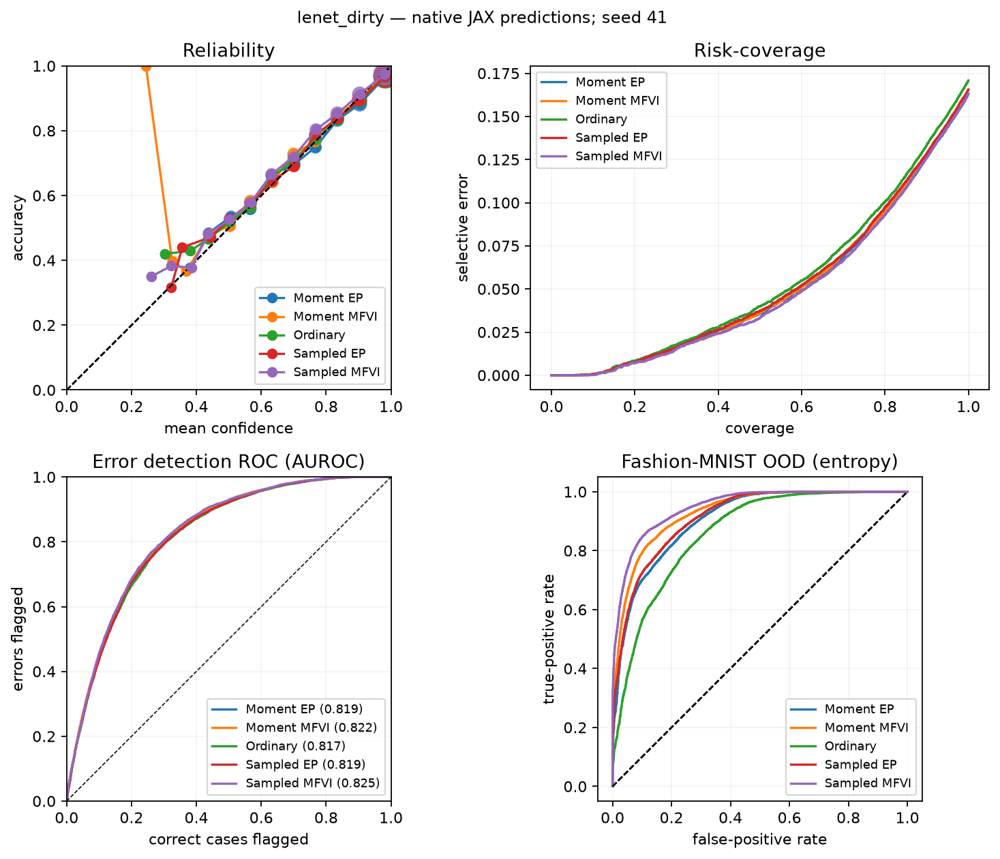

In [64]:
if RUN_DIRTY_MNIST:
    if not DOWNLOAD_PUBLIC_DATA:raise RuntimeError('Enable public-data downloads for training.')
    subprocess.run([sys.executable,'run_image_suite.py','--architectures','lenet','--dataset','dirty'],env=TRAIN_ENV,check=True)
frame=results.plots('results','figures')
dirty=frame[(frame.architecture=='lenet')&(frame.dataset=='dirty')]
assert len(dirty)==5,'The complete native Dirty-MNIST evidence must be bundled.'
display(results.reader_table(frame,'lenet','dirty').round(5))
display(results.protocol_table(frame,'lenet','dirty'))
display(Image(filename='figures/lenet_dirty_uncertainty.png'))

The five native Dirty-MNIST runs use 30 epochs, 110,000 training observations
and a fixed 10,000-observation validation set. Proper scores retain all ten labels
per ambiguous image, while the OOD ranking counts each image once. The shared
inference timer uses 10,000 clean test images; it does not count repeated labels
as additional forward evaluations. No new hyperparameter search is used here.
The native JAX results are separate from the R/PyTorch runs, with their own
random draws and compilation overhead. One seed is an implementation comparison,
not strong statistical evidence of a universal Bayesian advantage.

## 5. CIFAR-10: residual and dense connections

ResNet-20 uses three stages of three residual blocks and option-A shortcuts. DenseNet-40 uses growth 12
and 12 units per dense block. Their parameter counts are 269,722 and 1,019,722. A skip connection does not
make the forward computational graph cyclic. It does create correlated branches; adding their independent
variances would omit cross terms. Shared covariance factors retain those terms.
Each CIFAR run uses 45,000 training images, a fixed 5,000-image validation split,
and the official 10,000-image test set: batch size 125, 100 epochs, random crops
from four-pixel padding, and horizontal flips during training. All methods use
the same partition and seed 41; validation NLL selects the reported checkpoint.

**Implementation: `models.py`**

```python
def resnet20(seed=0,classes=10,**kwargs):
    b=Builder(seed,initial_ratio=.01,center_prior=False,he=True,**kwargs);x=b.add('stem_conv','conv0','input',shape=(3,3,3,16),options=(1,1))
    x=b.add('stem_bn','norm',x,shape=(16,));x=b.add('stem_relu','relu',x);ci=16
    for stage,co in enumerate((16,32,64),1):
        for block in range(1,4):
            prefix=f'stage{stage}_block{block}';stride=2 if stage>1 and block==1 else 1
            skip=x if stride==1 else b.add(prefix+'_shortcut','shortcut',x)
            h=b.add(prefix+'_conv1','conv0',x,shape=(3,3,ci,co),options=(stride,1));h=b.add(prefix+'_bn1','norm',h,shape=(co,));h=b.add(prefix+'_relu1','relu',h)
            h=b.add(prefix+'_conv2','conv0',h,shape=(3,3,co,co),options=(1,1));h=b.add(prefix+'_bn2','norm',h,shape=(co,))
            x=b.add(prefix+'_sum','add',skip,h);x=b.add(prefix+'_relu2','relu',x);ci=co
    x=b.add('global_pool','globalpool',x);b.add('classifier','readout',x,shape=(ci,classes));return b.finish('ResNet-20')

def densenet40(seed=0,classes=10,growth=12,**kwargs):
    b=Builder(seed,initial_ratio=.01,center_prior=False,he=True,**kwargs);ci=16;x=b.add('stem_conv','conv0','input',shape=(3,3,3,ci),options=(1,1))
    for stage in range(1,4):
        for block in range(1,13):
            p=f'dense{stage}_{block}';h=b.add(p+'_bn','norm',x,shape=(ci,));h=b.add(p+'_relu','relu',h)
            h=b.add(p+'_conv','conv0',h,shape=(3,3,ci,growth),options=(1,1));x=b.add(p+'_concat','concat',x,h);ci+=growth
        if stage<3:
            p=f'transition{stage}';x=b.add(p+'_bn','norm',x,shape=(ci,));x=b.add(p+'_relu','relu',x)
            x=b.add(p+'_conv','conv0',x,shape=(1,1,ci,ci),options=(1,0));x=b.add(p+'_pool','avgpool',x)
    x=b.add('final_bn','norm',x,shape=(ci,));x=b.add('final_relu','relu',x);x=b.add('global_pool','globalpool',x)
    b.add('classifier','readout',x,shape=(ci,classes));return b.finish('DenseNet-40')
```

### What the optimizer adds—and what it does not

The mathematical EP/MFVI messages above are independent of Adam or Vadam.
For large-scale experiments we must additionally specify a finite update.
Vadam retains moving averages of the likelihood gradient and its squared
value, uses the second statistic to normalize mean steps, and ties posterior
precision to its optimizer state. $E[g^2]$ is not $(E[g])^2$ and is not the
VI derivative with respect to variance. The moment implementation approximates
it with a linearized gradient: if $g(W)\simeq g(m)+H(W-m)$, then
$E[g(W)^{\odot2}]\simeq g(m)^{\odot2}+\operatorname{diag}(HC H^\top)$.
A shared random direction estimates the last diagonal; the optimizer's time
average remains a separate operation. This is an optimizer approximation,
not the exact Gaussian message-passing theorem.

For MFVI, an unbiased minibatch likelihood **sum** is
$(N/B)\sum_{n\in\mathcal B}E_q\log p(y_n\mid x_n,W)$; the KL is counted
once. An equivalent average objective divides both likelihood and KL by $N$.
Temperature changes that objective and must be reported.

### Tied power EP and the external field

The scalable EP-style training path has a tied Gaussian cavity, rather than
storing one full weight-space site per example. Put $k=\alpha/N$ and
$q_c=q^{1-k}p_0^k/A$. The declared energy is

$$\mathcal F=-\frac{\tau}{\alpha}
\left[\frac1N\sum_n\log E_{q_c}
p(y_n\mid x_n,W)^{\alpha/\tau}+\log A\right].$$

For one diagonal coordinate, let $r=v/v_0$ and $d=1+k(r-1)$.
Completing the Gaussian square gives
$v_c=v/d$, $m_c=m_0+(1-k)(m-m_0)/d$, and
$-\log A=\tfrac12[\log d-k\log r+k(1-k)(m-m_0)^2/(v_0d)]$.
Sum this last expression over coordinates. The external field is part of
the scalar objective every minibatch; it is not diluted by the number of
epochs. Differentiating must include the cavity and field dependence on $q$.

Expanding $\log E_q\exp[(\alpha/\tau)\log p]$ to first order in $\alpha$
and using $\log A=-(\alpha/N)\mathrm{KL}(q\|p_0)+O(\alpha^2)$ gives
$\mathcal F\to-\frac1N\sum_n E_q\log p_n
+\frac\tau N\mathrm{KL}(q\|p_0)$.
This connects the tied energy to VI in its small-power limit. Adam on the
mean and log variance optimizes this energy; it is **not** a literal EP site
replacement. The exact site algorithm and this scalable surrogate are named
separately throughout.

The full readout covariance is retained as a square root, $C=RR^\top$.
For the softmax contrast matrix $D$, a thin QR factorization $(DR)^\top=QT$
gives $DCD^\top=T^\top T$. Choosing the positive diagonal gives the same Cholesky
quadrature nodes, while avoiding loss of small positive directions when a dense
Gram matrix is formed. This changes the numerical representation, not the Gaussian model.

                                             MomentModel Summary                                              
┏━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┓
┃ path             ┃ type        ┃ inputs           ┃ outputs          ┃ Param            ┃ Variable         ┃
┡━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━┩
│                  │ MomentModel │ x:               │ float32[1,10]    │ 539,444 (2.2 MB) │ 540,820 (2.2 MB) │
│                  │             │ float32[1,32,32, │                  │                  │                  │
│                  │             │ 3]               │                  │                  │                  │
├──────────────────┼─────────────┼──────────────────┼──────────────────┼──────────────────┼──────────────────┤
│ layers/stem_conv │ MomentLayer │ parent0:         │ float32[1,32,32, │ 864 (3.5 KB)     │ 864 (3.5 KB)     │
│

<ipython-input-1-ce2a4d8b501c>:18: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(results.protocol_table(frame,architecture).round(5).fillna('—'))
<ipython-input-1-ce2a4d8b501c>:18: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(results.protocol_table(frame,architecture).round(5).fillna('—'))


,method,optimizer,learning_rate,log variance / rho LR,point / head decay,KL / external field strength,training samples,conditional_pairs,stochastic prediction passes,epochs,selected_epoch,compile s
23,Moment EP,adam,0.003,0.003,0.000,0.01,0,0,0,100,89,95.72247
24,Moment MFVI,vadam,0.003,—,0.000,0.001,0,0,0,100,71,91.18296
25,Ordinary,adamw,0.003,—,0.005,—,0,0,0,100,50,13.52649
26,Sampled EP,adam,0.003,0.003,0.000,0.001,4,0,20,100,52,93.75502
27,Sampled MFVI,vadam,0.003,—,0.000,0.001,1,0,20,100,88,74.47993


,method,Accuracy ↑,NLL ↓,ECE ↓,Brier ↓,AURC ↓,Error AUROC ↑,OOD AUROC ↑,Train s ↓,Train × ↓,Infer s ↓,Infer × ↓
23,Moment EP,0.9114,0.32071,0.02297,0.13692,0.01540,0.89256,0.85709,1277.11131,2.95232,0.62214,2.45981
24,Moment MFVI,0.9026,0.36166,0.03837,0.15314,0.01727,0.88967,0.81595,1688.02925,3.90224,0.62933,2.48825
25,Ordinary,0.8815,0.42309,0.05945,0.17978,0.02059,0.90071,0.89298,432.57934,1.00000,0.25292,1.00000
26,Sampled EP,0.8901,0.38963,0.05168,0.16741,0.01803,0.90525,0.92430,1855.26755,4.28885,4.54333,17.96349
27,Sampled MFVI,0.9020,0.30351,0.02061,0.14089,0.01441,0.91392,0.85825,486.04671,1.12360,4.55214,17.99831


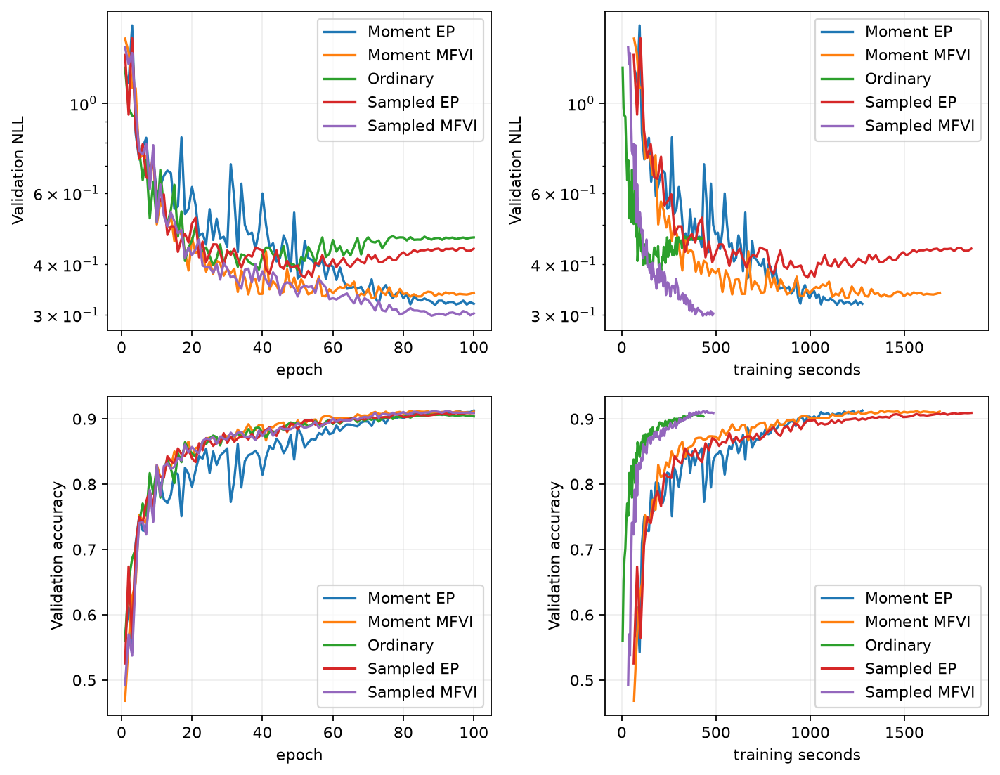

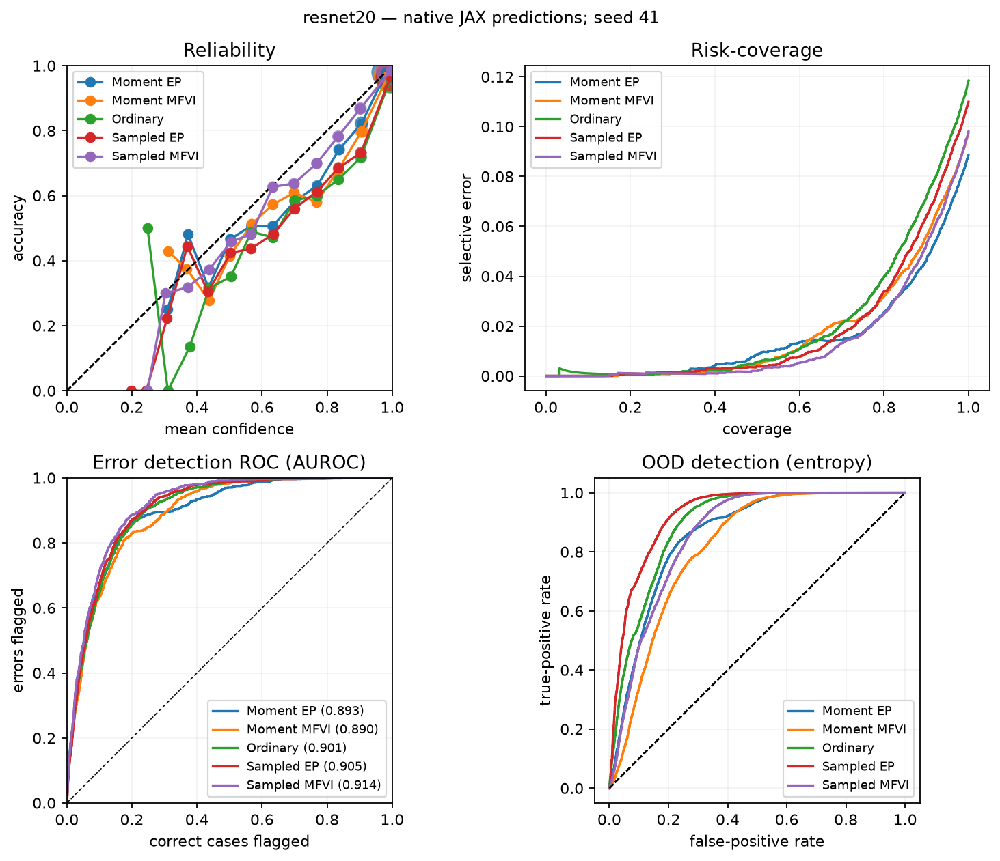

,method,optimizer,learning_rate,log variance / rho LR,point / head decay,KL / external field strength,training samples,conditional_pairs,stochastic prediction passes,epochs,selected_epoch,compile s
3,Moment EP,adam,0.003,0.003,0.000,0.01,0,0,0,100,80,419.42946
4,Moment MFVI,vadam,0.003,—,0.000,0.001,0,0,0,100,95,521.46966
5,Ordinary,adamw,0.003,—,0.005,—,0,0,0,100,36,121.62970
6,Sampled EP,adam,0.003,0.003,0.000,0.001,4,0,20,100,43,322.35320
7,Sampled MFVI,vadam,0.003,—,0.000,0.001,1,0,20,100,99,468.80235


,method,Accuracy ↑,NLL ↓,ECE ↓,Brier ↓,AURC ↓,Error AUROC ↑,OOD AUROC ↑,Train s ↓,Train × ↓,Infer s ↓,Infer × ↓
3,Moment EP,0.9092,0.32071,0.01510,0.13686,0.01585,0.89476,0.87440,11545.94391,3.36838,6.26315,3.32276
4,Moment MFVI,0.9290,0.30016,0.02925,0.11313,0.01079,0.90572,0.90425,18405.08043,5.36944,6.13209,3.25323
5,Ordinary,0.8987,0.40951,0.05655,0.15986,0.01654,0.90426,0.86184,3427.74657,1.00000,1.88492,1.00000
6,Sampled EP,0.8984,0.38785,0.05093,0.15936,0.01683,0.90079,0.87433,16403.77357,4.78559,46.40422,24.61866
7,Sampled MFVI,0.9284,0.24170,0.00831,0.10881,0.00950,0.91582,0.91693,3251.45996,0.94857,46.73360,24.79341


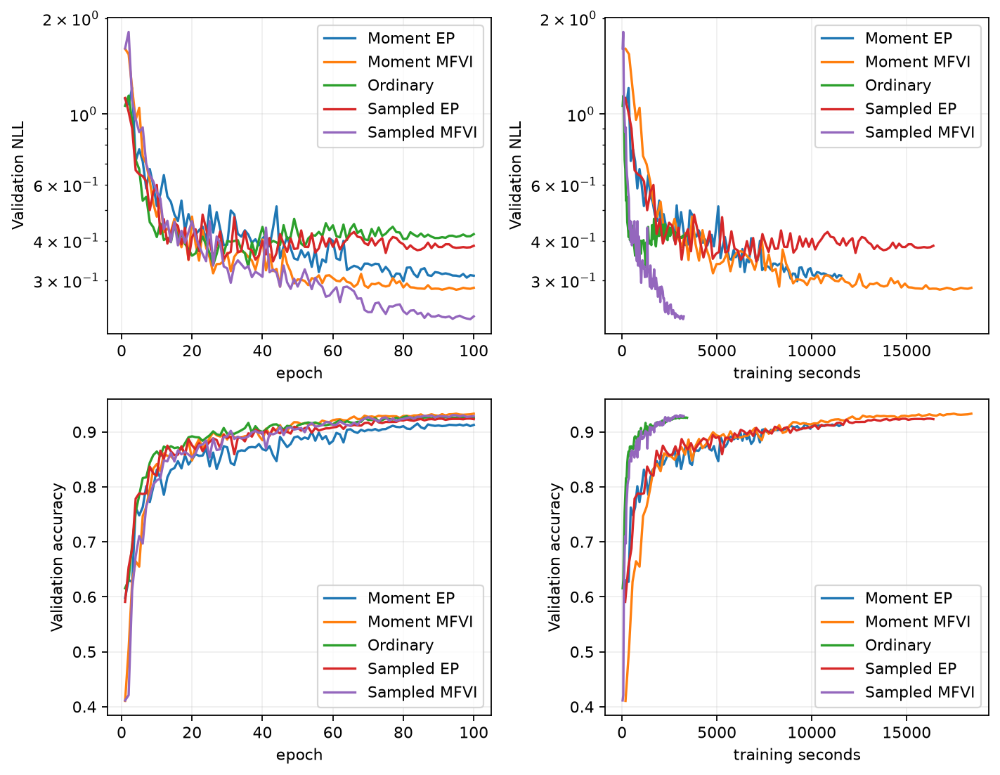

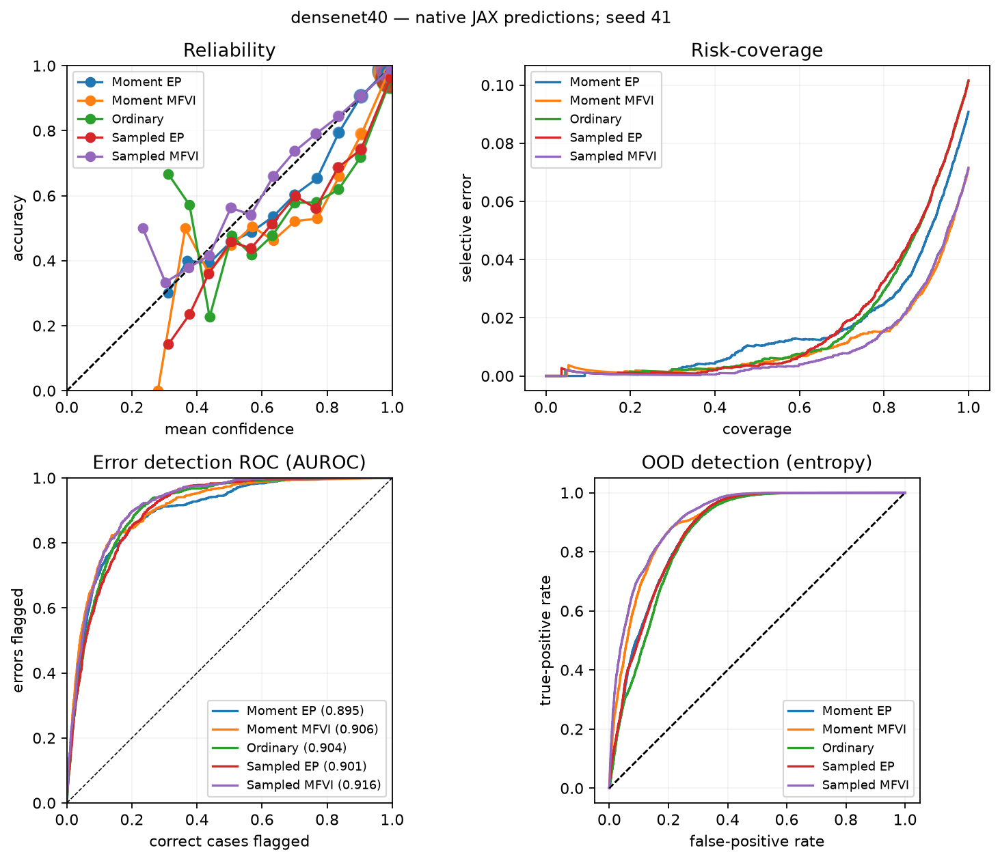

In [70]:
for name in ['resnet20','densenet40']:
    print(pathlib.Path(f'assets/architectures/{name}_compact.txt').read_text())
    artifact(f'assets/architectures/{name}.txt','Complete Flax NNX summary: ')
    artifact(f'assets/architectures/onnx/{name}.onnx','Actual graph for Netron: ')
    artifact(f'assets/architectures/netron/{name}.pdf','Expanded graph PDF: ')
if RUN_CIFAR:
    assert DOWNLOAD_PUBLIC_DATA
    jax.clear_caches();gc.collect()
    subprocess.check_call([sys.executable,'run_image_suite.py','--architectures','resnet20','densenet40'],env=TRAIN_ENV)
    for script in ['evaluate_cifar_ood.py','learned_fidelity.py']:
        subprocess.check_call([sys.executable,script],env=TRAIN_ENV)
frame=results.plots('results','figures')
if len(frame):
    for architecture in ['resnet20','densenet40']:
        rows=frame[frame.architecture==architecture]
        if len(rows):
            display(HTML('<h3>'+{'resnet20':'ResNet-20 / CIFAR-10','densenet40':'DenseNet-40 / CIFAR-10'}[architecture]+'</h3>'))
            display(results.protocol_table(frame,architecture).round(5).fillna('—'))
            display(results.reader_table(frame,architecture).round(5).fillna("—"))
            for name in ['learning','uncertainty']:
                path=pathlib.Path(f'figures/{architecture}_{name}.png')
                if path.exists():display(Image(filename=str(path)))

**What the CIFAR runs demonstrate.** Both moment methods improve accuracy and
predictive NLL over ordinary training on both architectures in these native runs.
The cost depends on the architecture and update: ResNet moment EP takes about
three times the training time and 2.5 times the inference time, while DenseNet
moment MFVI has a larger training cost. The tables retain these differences rather
than implying one overhead factor for every model. OOD evaluation uses the same
selected beliefs and is assessed separately from in-distribution calibration.

**Same-belief approximation check.** Section 3 separately compares the native
learned-belief forward and backward approximation with a high-precision MC
reference. Predictive performance and local moment fidelity are different
measurements; neither is substituted for the other.

## 6. GPT-2 LoRA: attention and Gaussian message boundaries

GPT-2-small retains its pretrained backbone and uses rank-four query/value adapters. SST-2 is evaluated
through the probabilities of the negative/positive answer tokens. The model does not average the two
answer logits and call that Bayesian model averaging. Gaussian-A+B and conditional Gaussian-A/point-B
are distinct families and are labeled separately.

### Conditional Gaussian carriers and probability averaging

The BLoB-inspired construction learns **one diagonal Gaussian adapter
distribution**, not a mixture or an ensemble: $A=M_A+\rho^{\odot2}\odot\epsilon$
with $\epsilon\sim N(0,I)$; $B$ is a point parameter and the pretrained backbone
is frozen. Thus $\operatorname{Var}(A)=\rho^{\odot4}$. The objective is expected
log likelihood plus the source Gaussian KL, with prior standard deviation 0.2
and the source cyclic KL schedule. Likelihood AdamW and the separate
prior/variance SGD step follow that source update. This is **mean-field VI
with a conditional-moment approximation**, not EP or a canonical unit MFVI step.

**Why activation correlations survive diagonal weights.** For one adapter,
write $z=(W+sBA)x$ and $\overline W=W+sBM_A$. With independent $A$ and $x$,
mean $m_x$ and covariance $C_x$, conditional expectation gives
$E[z]=\overline Wm_x$. The law of total covariance gives the exact affine
identity $\operatorname{Cov}(z)=\overline W C_x\overline W^\top
+s^2B\operatorname{Diag}\{V_A(\operatorname{diag}C_x+m_x^{\odot2})\}B^\top$,
where $V_A=\operatorname{Var}(A)$. To derive the second term, condition on $x$:
independent rows of $A$ have conditional output variance
$\sum_j(V_A)_{ij}x_j^2$; then average $x_j^2$.
Multiplication by $B$ induces correlated outputs even though $V_A$ is diagonal.
For different inputs, the same random adapter is reused; their injected
cross-covariance contains $\sum_j(V_A)_{ij}E[x_jx'_j]$, not separate weight draws.

The training approximation retains these dependencies through shared local
directions. For paired nonlinear block outputs $Y_k^\pm$, define their mean
$m=(2K)^{-1}\sum_k(Y_k^++Y_k^-)$, odd deviations
$O_k=(Y_k^+-Y_k^-)/2$ and even deviations
$E_k=(Y_k^++Y_k^-)/2-m$. A moment carrier
$\widetilde Y=m+K^{-1/2}\sum_k(\epsilon_kO_k+\zeta_kE_k)$,
with independent coefficient vectors uniformly distributed on the sphere of
radius $\sqrt K$, has conditional mean $m$
and covariance $K^{-1}\sum_k(O_kO_k^\top+E_kE_k^\top)$.
Indeed, $\epsilon=\sqrt K g/\|g\|$ for $g\sim N(0,I_K)$ satisfies
$E\epsilon=0$ and $E[\epsilon\epsilon^\top]=I_K$ by rotational symmetry and
its fixed squared norm $K$; the independently generated $\zeta$ does too.
Expanding the paired centered outer products proves that this equals the
paired empirical covariance. Two antithetic pairs per block were used in the
training fit. This spherical carrier is stochastic and need not be Gaussian
conditional on its integration nodes; the finite-node nonlinear calculation
remains an approximation. The posterior weights are still a single Gaussian.
The Gaussian coordinate
bridge remains the same; this extension changes the moment closure and update.

The source training code also uses Flipout signs to reduce gradient variance.
Here the signs vary across **tokens**, not only across examples. They preserve
the perturbation marginal of one affine token row, but do not generally preserve
the joint perturbation of a complete sequence. For a scalar shared readout
$z_t=x_t^\top w$, independent Gaussian weight variances give
$\operatorname{Cov}(z_t,z_s)=\sum_i x_{ti}x_{si}v_i$. Independent zero-mean
output signs at distinct tokens instead make this cross-token covariance zero:
the cross product contains the factor $E[s_ts_s]=0$. Attention can depend on
these correlations. Thus increasing the number of source-Flipout predictions
need not reproduce the global shared-weight predictor. The serving table labels
these two probability averages separately. Cross-input covariance diagnostics
likewise use actual shared sampled weights.

The original Gaussian-A+B path offers a separate deterministic predictor:
for SST-2 it integrates $E[\sigma(D)]$ over a Gaussian logit contrast;
for multiclass CLINC it averages softmax probabilities at symmetric output
nodes. The conditional Gaussian-A/point-B experiments use the source-coupled
stochastic carrier instead. Their serving comparison records how many carrier
passes or complete-network draws are averaged. These are different
approximations; neither applies softmax only to averaged logits.


**Training and serving carriers are different.** The spherical law above is
stochastic and bounded conditional on its nodes. A Gaussian carrier with the
same columns has the same first two moments but a different higher-moment law.
`blob.coupled_nodes` couples these nodes to the source sampler's random stream.
If $a$ is a unit vector, $\xi_*$ and $Z_i$ are independent
standard Gaussians, set $\Xi_i=a_i\xi_*+Z_i-a_i\sum_j a_jZ_j$.
Conditional on $a$, the joint covariance is $aa^\top+(I-aa^\top)^2=I$ and
$\sum_i a_i\Xi_i=\xi_*$. Thus the nodes have the intended independent Gaussian
law while preserving the source draw under recombination. Since this law does
not depend on $a$, the nodes are independent of $a$ under the ideal random
construction. This coupling and its stop-gradient/randomness choices matter
when comparing updates, not only predicted moments.

### LayerNorm, attention and LoRA: the actual directional equations

For LayerNorm, $a=x-\bar x$, $s=(d^{-1}\|a\|^2+\varepsilon)^{-1/2}$.
Its directional derivative is
$\delta y=\gamma s[\delta x-\overline{\delta x}-a s^2\overline{a\delta x}]
+\delta\gamma\,sa+\delta\beta$.
Differentiate the centering, variance and scale successively to obtain this
expression. Merely scaling each marginal variance by $\gamma^2s^2$ omits both
projection terms. The local JVP in the notebook includes them.

For attention, $S=QK^\top/\sqrt d$, $P=\mathrm{softmax}(S)$, $O=PV$.
The three directional equations are
$\delta S=(\delta QK^\top+Q\delta K^\top)/\sqrt d$,
$\delta P=P\odot[\delta S-\sum_jP_j\delta S_j]$, and
$\delta O=\delta P V+P\delta V$.
Shared columns preserve $Q$–$K$–$V$ cross terms that independent marginal
propagation discards. Causal and padding masks remain deterministic.

For LoRA, $Y=XW_0+cXAB$ and
$\delta Y=\delta X(W_0+cAB)+cX\delta A B+cXA\delta B$.
The first-order rule omits $cX\delta A\delta B$ and related products involving
$\delta X$. If $B=0$ at initialization, the first-order derivative with respect
to $A$ vanishes, while the product uncertainty need not vanish. Therefore the
initial and learned-belief tests must both be run; checking only the mean
network or only late checkpoints misses this failure mode.

**Implementation: `transformers.py`**

```python
def attention(q,k,v,mask,heads,causal):
    B,T,D=q.shape;d=D//heads
    reshape=lambda z:z.reshape(B,T,heads,d).transpose(0,2,1,3)
    q,k,v=map(reshape,(q,k,v));scores=jnp.einsum('bhtd,bhsd->bhts',q,k)/math.sqrt(d)
    valid=mask[:,None,None,:].astype(bool)
    if causal:valid=valid & jnp.tril(jnp.ones((T,T),dtype=bool))[None,None]
    P=jax.nn.softmax(jnp.where(valid,scores,jnp.finfo(scores.dtype).min),-1)
    return jnp.einsum('bhts,bhsd->bhtd',P,v).transpose(0,2,1,3).reshape(B,T,D)

def block(x,mask,base,adapters,cfg,index,linear_fn=None):
    p=f'block{index}.';scale=cfg.alpha/cfg.rank
    normal=adapters if cfg.family=='full' else base
    ln=lambda z,n:layer_norm(z,normal[p+n+'.weight'],normal[p+n+'.bias'],cfg.eps)
    linear=(lambda z,n:affine(z,base,p+n,adapters,scale)) if linear_fn is None else (lambda z,n:linear_fn(z,p+n))
    h=ln(x,'ln1') if cfg.architecture=='gpt2' else x
    q,k,v=[linear(h,n) for n in ('query','key','value')]
    h=linear(attention(q,k,v,mask,cfg.heads,cfg.architecture=='gpt2'),'attention_output')
    x=x+h
    if cfg.architecture=='roberta':x=ln(x,'ln1')
    h=ln(x,'ln2') if cfg.architecture=='gpt2' else x
    h=linear(jax.nn.gelu(linear(h,'ff1'),approximate=cfg.architecture=='gpt2'),'ff2')
    y=x+h
    return y if cfg.architecture=='gpt2' else ln(y,'ln2')

def readout(h,base,adapters,mask,cfg,target_ids):
    if cfg.architecture=='gpt2':
        weights=adapters if cfg.family=='full' else base
        h=layer_norm(h,weights['final_ln.weight'],weights['final_ln.bias'],cfg.eps)
        last=h[jnp.arange(h.shape[0]),jnp.maximum(mask.sum(-1)-1,0)]
        return last@weights['token_embedding'][target_ids].T
    h=jnp.tanh(affine(h[:,0],base,'classifier.dense',adapters,cfg.alpha/cfg.rank))
    return affine(h,base,'classifier.out',adapters,cfg.alpha/cfg.rank)

def tangent(base,beliefs,ids,mask,cfg,target_ids,key,rank=4,return_states=False):
    """One shared direction identity throughout all blocks; local JVPs only."""
    keys=jax.random.split(key,len(beliefs));means={n:q.mean for n,q in beliefs.items()}
    U={n:jnp.sqrt(q.variance)*jax.random.rademacher(k,(rank,)+q.mean.shape,dtype=q.mean.dtype) for (n,q),k in zip(sorted(beliefs.items()),keys)}
    embed=lambda w:embeddings(w if cfg.family=='full' else base,ids,mask,cfg)
    h=embed(means);s=Shared(h,jax.vmap(lambda u:jax.jvp(embed,(means,),(u,))[1])(U));states=[s]
    for i in range(cfg.layers):
        f=lambda x,w:block(x,mask,base,w,cfg,i)
        mean=f(s.mean,means)
        factors=jax.vmap(lambda dh,dw:jax.jvp(f,(s.mean,means),(dh,dw))[1])(s.factors,U)
        s=Shared(mean,factors);states.append(s)
    f=lambda x,w:readout(x,base,w,mask,cfg,target_ids)
    out=Shared(f(s.mean,means),jax.vmap(lambda dh,dw:jax.jvp(f,(s.mean,means),(dh,dw))[1])(s.factors,U))
    return (out,states) if return_states else out
```

<details><summary>Implementation: `transformers.py`</summary>

```python
def moment_likelihood(base,beliefs,ids,mask,cfg,target_ids,key,labels,rank=4,method='mfvi'):
    """Explicit local reverse of the transformer moment graph.

    Each block receives one Shared activation boundary and its own Gaussian
    adapter blocks. Forward snapshots and noise IDs stay fixed during reverse.
    No full-network posterior oracle or numerical conditioning enters updates.
    """
    from .heads import categorical_objective
    from .gaussian import encode
    keys=jax.random.split(key,len(beliefs));noise={n:jax.random.rademacher(k,(rank,)+q.mean.shape,dtype=q.mean.dtype) for (n,q),k in zip(sorted(beliefs.items()),keys)}
    records=[]
    names=tuple(n for n in sorted(beliefs) if not n.startswith(('block','classifier.','final_ln.')))
    qs={n:beliefs[n] for n in names} if cfg.family=='full' else {}
    def embed_local(unused,q):
        means={n:p.mean for n,p in q.items()};U={n:jnp.sqrt(p.variance)*noise[n] for n,p in q.items()}
        f=lambda w:embeddings(w if cfg.family=='full' else base,ids,mask,cfg)
        h=f(means)
        factors=jax.vmap(lambda u:jax.jvp(f,(means,),(u,))[1])(U) if U else jnp.zeros((rank,)+h.shape,dtype=h.dtype)
        return Shared(h,factors)
    s=embed_local((),qs);records.append(((),qs,embed_local))
    for i in range(cfg.layers):
        names=tuple(n for n in sorted(beliefs) if n.startswith(f'block{i}.'));qs={n:beliefs[n] for n in names}
        def local(s,q,i=i,names=names):
            means={n:p.mean for n,p in q.items()};U={n:jnp.sqrt(p.variance)*noise[n] for n,p in q.items()}
            f=lambda h,w:block(h,mask,base,w,cfg,i)
            return Shared(f(s.mean,means),jax.vmap(lambda dh,dw:jax.jvp(f,(s.mean,means),(dh,dw))[1])(s.factors,U))
        out=local(s,qs);records.append((s,qs,local));s=out
    names=tuple(n for n in sorted(beliefs) if n.startswith('classifier.') or (cfg.family=='full' and n.startswith(('final_ln.','token_embedding'))));qs={n:beliefs[n] for n in names}
    def head_local(s,q):
        means={n:p.mean for n,p in q.items()};U={n:jnp.sqrt(p.variance)*noise[n] for n,p in q.items()}
        f=lambda h,w:readout(h,base,w,mask,cfg,target_ids)
        return Shared(f(s.mean,means),jax.vmap(lambda dh,dw:jax.jvp(f,(s.mean,means),(dh,dw))[1])(s.factors,U))
    out=head_local(s,qs);records.append((s,qs,head_local))
    objective=lambda z:categorical_objective(jnp.concatenate((z.mean[None]+z.factors,z.mean[None]-z.factors),0),labels,method)
    value,adj=jax.value_and_grad(objective)(out);grad={};boundary=[]
    for s,qs,f in reversed(records):
        _,pull=jax.vjp(f,s,qs);adj,g=pull(adj)
        for n,a in g.items():grad[n]=jax.tree_util.tree_map(lambda x,y:x+y,grad[n],a) if n in grad else a
        boundary.append(adj)
    return value,grad,list(reversed(boundary)),{n:encode(beliefs[n],g) for n,g in grad.items()}
```

</details>

### The same Gaussian adapters in two independent implementations

This check transfers the selected MFVI and EP beliefs, with both Gaussian LoRA
factors, into native JAX without training again. Both implementations use the same
frozen GPT-2 weights, 872 SST-2 inputs and 20-node scalar Gaussian integral.
For the logit contrast $z(w)$, the delta approximation is $m_z=z(m)$ and
$v_z=\sum_j(\partial_jz(m))^2v_j$. Differentiating this map includes the
dependence of its Jacobian on the mean. It does not replace that Jacobian by a
constant during the backward pass.
This check uses the fully differentiated map; a frozen-Jacobian training variant
is a separate approximation.

The four-example likelihood comparison checks all adapter mean and variance
derivatives in matching coordinates. It establishes implementation agreement for
this approximation. It is separate from accuracy against nonlinear network samples,
which is the question addressed by the earlier Monte Carlo study.

**Implementation: `transformers.py`**

```python
def scalar_moments(base,beliefs,ids,mask,cfg,target_ids):
    """Exact delta-method binary variance; no random directional sketch.

    J_n is refreshed at the current mean. v_n=sum_j J_nj² v_j. A per-example
    VJP avoids constructing a B×B activation Jacobian; transformer examples
    have no cross-example operators. Differentiating this map includes dJ/dm.
    """
    means={n:q.mean for n,q in beliefs.items()}
    one=lambda w,ids,mask:jnp.diff(point(base,w,ids[None],mask[None],cfg,target_ids),axis=-1)[0,0]
    m,J=jax.vmap(jax.value_and_grad(one),in_axes=(None,0,0))(means,ids,mask)
    v=sum((a*a*beliefs[n].variance).reshape(len(ids),-1).sum(-1) for n,a in J.items())
    return Moments(m,v),J

def scalar_likelihood(base,beliefs,ids,mask,cfg,target_ids,labels,method='ep'):
    from .heads import binary_gaussian
    # Forward scalar moments -> head adjoint -> pullback through the same
    # cached delta-method map. This is distinct from freezing J in Vadam.
    f=lambda q:scalar_moments(base,q,ids,mask,cfg,target_ids)[0]
    output,pull=jax.vjp(f,beliefs)
    value,adj=jax.value_and_grad(lambda q:binary_gaussian(q,labels,method))(output)
    return value,pull(adj)[0]
```

In [79]:
folder=pathlib.Path('results/transferred_gaussian_text')
subprocess.run([sys.executable,'matched/compare_text_beliefs.py',str(folder)],
               check=True,capture_output=True,text=True)
agreement=json.loads((folder/'native_agreement.json').read_text())
assert agreement['passed'],'Investigate the matched-belief discrepancy before reporting equivalence.'
records=[]
for method in ['mfvi','ep']:
    for suffix,framework in [('', 'JAX'),('_torch','PyTorch reference')]:
        r=json.loads((folder/(method+suffix+'.json')).read_text())
        records.append({'Belief':method.upper(),'Implementation':framework,
                        'Accuracy ↑':r['accuracy'],'NLL ↓':r['nll'],'ECE ↓':r['ece']})
display(pd.DataFrame(records).round(7))
display(pd.DataFrame(agreement['rows']).rename(columns={
    'max_abs':'Maximum absolute error ↓','relative_l2':'Relative L2 error ↓'}))

,Belief,Implementation,Accuracy ↑,NLL ↓,ECE ↓
0,MFVI,JAX,0.918578,0.225980,0.030367
1,MFVI,PyTorch reference,0.918578,0.225980,0.030367
2,EP,JAX,0.923165,0.223255,0.029407
3,EP,PyTorch reference,0.923165,0.223255,0.029407


,method,quantity,Maximum absolute error ↓,Relative L2 error ↓,passed
0,mfvi,probabilities,9.000301e-06,0.000001,True
1,mfvi,objective,5.066395e-07,0.000004,True
2,mfvi,mean,9.512529e-06,0.000010,True
3,mfvi,variance,3.767014e-05,0.000005,True
4,ep,probabilities,6.139278e-06,0.000001,True
5,ep,objective,0.000000e+00,0.000000,True
6,ep,mean,2.960209e-06,0.000005,True
7,ep,variance,1.716614e-05,0.000008,True


**Full-weight RoBERTa counterpart.** Setting `family='full'` gives a Gaussian belief to every embedding, normalization, attention, feed-forward and classifier parameter. Local embedding JVPs seed the activation covariance; repeated token IDs reuse the same uncertain embedding rows. This is separate from the fixed-backbone LoRA model. Token IDs and attention masks remain observed tensors.

**Implementation: `transformers.py`**

```python
def full_weight_beliefs(base,variance=1e-8):
    """Independent Gaussian coordinates for every embedding, norm, affine and head.

    The data IDs and masks remain deterministic. Repeated token IDs gather the
    SAME uncertain embedding rows; shared directions retain that covariance.
    The R full-RoBERTa path uses variance 1e-8 and prior variance 1e-6.
    """
    return {n:Moments(a,jnp.full_like(a,variance)) for n,a in base.items()}
```

<details><summary>Implementation: `gaussian_text.py`</summary>

```python
def initialize(cfg,base,seed=41,full_weight=False,optimizer='adam',N=1,temperature=1.,likelihood_normalization=False):
    cfg=replace(cfg,family='full' if full_weight else 'ab')
    q=T.full_weight_beliefs(base) if full_weight else T.initial_beliefs(cfg,seed)
    # Full-weight prior is centered at the supplied pretrained checkpoint.
    prior={n:Moments(p.mean if full_weight else j.zeros_like(p.mean),j.full_like(p.variance,1e-6 if full_weight else 1/2500)) for n,p in q.items()}
    zero={n:j.zeros_like(p.mean) for n,p in q.items()}
    opt=I.vadam_init(q,prior,N,temperature,likelihood_normalization) if optimizer=='vadam' else (j.array(0),zero,zero,zero,zero)
    return cfg,prior,{'belief':q,'optimizer':opt,'key':jax.random.PRNGKey(seed),'updates':j.array(0)}

def frozen_statistics(cfg,base,targets,q,ids,mask,labels,key,rank=4):
    """The R frozen-sensitivity closures; J is refreshed at every update.

    Binary: integrate E[r] and E[rr'] under the full minibatch Gaussian,
    then g=J'E[r]/B and E[g²]=diag(J'E[rr']J)/B².
    Multiclass: g=J' E[softmax(z)-y]/B and a shared-direction GGN correction
    sum_r (J' H_loss U_r/sqrt(R))². Neither is the VI variance derivative.
    """
    means={n:p.mean for n,p in q.items()};B=len(labels)
    f=lambda w:T.point(base,w,ids,mask,cfg,targets)
    if cfg.classes==2:
        scalar,J=T.scalar_moments(base,q,ids,mask,cfg,targets);m=scalar.mean
        names=tuple(sorted(q));flat=j.concatenate([J[n].reshape(B,-1) for n in names],1)
        v=j.concatenate([q[n].variance.reshape(-1) for n in names])
        gm,g2,C=covariance.frozen_gradient_moments(m,flat,v,labels,order=20)
        first={};second={};offset=0
        for n in names:
            count=q[n].mean.size;first[n]=gm[offset:offset+count].reshape(q[n].mean.shape);second[n]=g2[offset:offset+count].reshape(q[n].mean.shape);offset+=count
        return first,second
    out=T.tangent(base,q,ids,mask,cfg,targets,key,rank)
    nodes=j.concatenate((out.mean[None]+out.factors,out.mean[None]-out.factors),0)
    adj=(jax.nn.softmax(nodes,-1).mean(0)-jax.nn.one_hot(labels,cfg.classes,dtype=out.mean.dtype))/B
    _,pull=jax.vjp(f,means);first=pull(adj)[0];p=jax.nn.softmax(out.mean,-1)
    variation=p*(out.factors-(p*out.factors).sum(-1,keepdims=True))/(B*j.sqrt(rank))
    directions=jax.vmap(lambda a:pull(a)[0])(variation)
    return first,{n:first[n]**2+(directions[n]**2).sum(0) for n in q}

def make_step(cfg,base,targets,prior,N,method='mfvi',mode='moment',rank=4,samples=4,learning_rate=1e-4,temperature=1.,optimizer='adam',damping=.01):
    if optimizer in ('canonical','vadam') and method!='mfvi':raise ValueError('This MFVI update is not an EP site update.')
    def step(state,ids,mask,labels):
        q=state['belief'];key,k=jax.random.split(state['key']);B=len(ids)
        if optimizer=='vadam':
            point_loss=lambda w:-heads.categorical_objective(T.point(base,w,ids,mask,cfg,targets)[None],labels)/B
            if mode=='sampled':
                losses,g=jax.vmap(jax.value_and_grad(point_loss))(I.sample_weights(q,k,samples))
                gm={n:a.mean(0) for n,a in g.items()};g2={n:(a*a).mean(0) for n,a in g.items()};loss=losses.mean()
            else:
                gm,g2=frozen_statistics(cfg,base,targets,q,ids,mask,labels,k,rank)
                value,_,_,_=T.moment_likelihood(base,q,ids,mask,cfg,targets,k,labels,rank,'mfvi');loss=-value/B
            new,opt=I.vadam_step(q,prior,gm,g2,state['optimizer'],N,temperature,learning_rate)
            return {'belief':new,'optimizer':opt,'key':key,'updates':state['updates']+1},loss
        if method=='ep':(cavity,A),pull=jax.vjp(lambda p:I.power_cavity(p,prior,N,temperature),q)
        else:cavity=q
        if mode=='moment' and cfg.classes==2:value,g=T.scalar_likelihood(base,cavity,ids,mask,cfg,targets,labels,method)
        elif mode=='moment':value,g,_,_=T.moment_likelihood(base,cavity,ids,mask,cfg,targets,k,labels,rank,method)
        else:
            objective=lambda p:heads.categorical_objective(T.sampled(base,p,ids,mask,cfg,targets,k,samples),labels,method)
            value,g=jax.value_and_grad(objective)(cavity)
        if optimizer=='canonical':
            # Maximize scaled likelihood / temperature - KL. Independent of
            # the sampled-gradient normalization state used by Vadam.
            like=jax.tree_util.tree_map(lambda a:a*N/(B*temperature),g)
            new={n:mfvi_update(q[n],encode(q[n],like[n]),prior[n],damping) for n in q};opt=state['optimizer'];loss=-value/B
        else:
            loss=-value/B;g=jax.tree_util.tree_map(lambda a:-a/B,g)
            if method=='ep':loss=loss-A;g=pull((g,j.asarray(-1.,dtype=A.dtype)))[0]
            else:
                K,gK=jax.value_and_grad(lambda p:I.kl(p,prior))(q);loss+=temperature/N*K
                g=jax.tree_util.tree_map(lambda a,b:a+temperature/N*b,g,gK)
            new,opt=adam_recurrence(q,g,state['optimizer'],learning_rate,learning_rate)
        return {'belief':new,'optimizer':opt,'key':key,'updates':state['updates']+1},loss
    return jax.jit(step)
```

</details>

In [83]:
for name in ['gpt2','roberta']:
    print(pathlib.Path(f'assets/architectures/{name}_compact.txt').read_text())
    artifact(f'assets/architectures/{name}.txt','Complete Flax NNX summary: ')
    artifact(f'assets/architectures/onnx/{name}.onnx','Actual graph for Netron: ')
    artifact(f'assets/architectures/netron/{name}.pdf','Expanded graph PDF: ')

                                             Transformer Summary                                              
┏━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ path      ┃ type             ┃ inputs            ┃ outputs          ┃ Param            ┃ Variable          ┃
┡━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│           │ Transformer      │ ids: int32[1,8]   │ float32[1,2]     │ 294,912 (1.2 MB) │ target_ids:       │
│           │                  │ mask: int32[1,8]  │                  │                  │ int64[2]          │
│           │                  │                   │                  │                  │                   │
│           │                  │                   │                  │                  │ 124,734,722       │
│           │                  │                   │                  │                  │ (498.9 MB)        │
├

## 7. Conditional moment MFVI: GPT-2 and RoBERTa LoRA

This path mirrors the BLoB-inspired source experiment. It uses Gaussian A with variance $\rho^4$,
point B, and a full point classifier for CLINC150. It is not full-weight Bayesian RoBERTa, nor EP.
The split optimizer preserves the source ordering: a likelihood AdamW step on means, followed by SGD
of the retained variance adjoint and a KL evaluated after the mean step.

Both text protocols use batches of 32 and at most 128 tokens. GPT-2 uses 67,349
SST-2 training sentences, three epochs, and the official 872-sentence validation
set as the reporting cohort. Its fixed two-example sentiment prompt and answer
tokens are defined in `data.text_data`; no hidden-test result is claimed.
CLINC uses 13,500 fitting utterances and a 1,500-utterance stopping split taken
from the training set, six epochs, and 4,500 official in-scope test utterances.
The 1,000 official out-of-scope test utterances are used only for OOD evaluation.
Duplicate token sequences stay in the same fitting/stopping group. The ordinary
and Bayesian variants share the pretrained backbone, adapter initialization,
data partitions, and reporting protocol.

For unit vector $a$, source Gaussian noise $\xi$ and independent Gaussian $Z_i$, define
$\Xi_i=a_i\xi+Z_i-a_i\sum_j a_j Z_j$. Conditional on $a$, the joint covariance is the identity,
and $\sum_i a_i\Xi_i=\xi$. Antithetic evaluations form local means and odd/even deviations.
Spherical recompression preserves their conditional first two moments. It does not preserve all higher
moments. With one direction, the source-coupled construction recovers the source output and derivatives
exactly; this is an executable exact-limit check for the approximation.

**Implementation: `blob.py`**

```python
def coupled_nodes(xi,a,key):
    # Xi_i=a_i xi+Z_i-a_i sum_j a_j Z_j; Cov(Xi_i,Xi_j)=delta_ij I.
    Z=jax.random.normal(key,(len(a),)+xi.shape,dtype=xi.dtype)
    av=a.reshape((len(a),)+(1,)*xi.ndim)
    return av*xi+Z-av*(av*Z).sum(0)

def transition(h,base,means,rho,mask,cfg,index,key,auxiliary,pairs=2,reference=False):
    k1,k2,k3=jax.random.split(auxiliary,3)
    a=jax.random.normal(k1,(pairs,),dtype=h.dtype);a=a/jnp.linalg.norm(a)
    b=jax.random.normal(k2,(pairs,),dtype=h.dtype);b=b/jnp.linalg.norm(b)
    samples={};signs={};prefix=f'block{index}.'
    names=[prefix+n for n in ['query','value']]
    for n,ks,ka in zip(names,jax.random.split(key,len(names)),jax.random.split(k3,len(names))):
        r,t,e=jax.random.split(ks,3);A=means[n+'.A']
        signs[n]=(jax.random.rademacher(r,h.shape,dtype=h.dtype),jax.random.rademacher(t,h.shape[:-1]+(cfg.rank,),dtype=h.dtype))
        xi=jax.random.normal(e,A.shape,dtype=h.dtype)
        if reference:samples[n]=xi[None]
        else:
            z=coupled_nodes(xi,a,ka);samples[n]=jnp.concatenate((z,-z),0)
    def one(noise):
        def linear(x,name):
            y=T.affine(x,base,name,means,cfg.alpha/cfg.rank)
            if name in noise:
                r,t=signs[name]
                y=y+cfg.alpha/cfg.rank*((((x*r)@(noise[name]*rho[name+'.A']**2))*t)@means[name+'.B'])
            return y
        return T.block(h,mask,base,means,cfg,index,linear_fn=linear)
    nodes=jax.vmap(one)(samples)
    if reference:return nodes[0]
    plus,minus=nodes[:pairs],nodes[pairs:];mean=((plus+minus)/2).mean(0)
    odd=(plus-minus)/2;even=(plus+minus)/2-mean;shape=(pairs,)+(1,)*mean.ndim
    return mean+(a.reshape(shape)*odd+b.reshape(shape)*even).sum(0)

def source_kl(means,rho,prior_std=.2,epsilon=1e-6):
    # Source-stabilized Gaussian KL. eps=0 recovers the exact Gaussian formula.
    return sum(jnp.sum(jnp.log(prior_std+epsilon)-jnp.log(r**2+epsilon)+
                      (r**4+means[n]**2)/(2*prior_std**2+epsilon)-.5) for n,r in rho.items())

def split_update(means,rho,g_mean,g_rho,state,optimizer,lr,variance_lr,step,cycle,decay=0.,prior_std=.2):
    # 1. AdamW likelihood update of means/point parameters; rho is excluded.
    u,state=optimizer.update(g_mean,state,means)
    next_mean={n:m-lr*u[n]-lr*(decay[n] if isinstance(decay,dict) else decay)*m for n,m in means.items()}
    # 2. Evaluate KL at updated means, retaining rho's OLD likelihood adjoint.
    pi=cycle_weight(step,cycle);value,(dm,dr)=jax.value_and_grad(source_kl,argnums=(0,1))(next_mean,rho,prior_std)
    next_mean=jax.tree_util.tree_map(lambda m,d:m-variance_lr*pi*d,next_mean,dm)
    next_rho={n:r-variance_lr*(g_rho[n]+pi*dr[n]) for n,r in rho.items()}
    return next_mean,next_rho,state,value,pi
```

<details><summary>Implementation: `text_training.py`</summary>

```python
def make_step(cfg,base,target_ids,method,N,epochs,optimizer,batch=32,pairs=2):
    total=epochs*math.ceil(N/batch);warm=max(1,round((.05 if cfg.architecture=='gpt2' else .06)*total));cycle=int(100*N**(math.pi/8)/batch)
    learning_rate=3e-4 if cfg.architecture=='gpt2' else .001
    def step(state,ids,mask,labels):
        key,source,aux=jax.random.split(state['key'],3)
        def objective(means,rho):
            logits=T.point(base,means,ids,mask,cfg,target_ids) if method=='ordinary' else blob.forward(base,means,rho,ids,mask,cfg,target_ids,source,aux,pairs,reference=method=='sampled')
            return -jnp.take_along_axis(jax.nn.log_softmax(logits,-1),labels[:,None],-1).mean()
        value,(gm,gr)=jax.value_and_grad(objective,argnums=(0,1))(state['means'],state['rho'])
        step=state['updates'];t=step+1;u=jnp.maximum(t-warm,0)/max(total-warm,1)
        cool=.1+.9*(1+jnp.cos(jnp.pi*u))/2 if cfg.architecture=='gpt2' else jnp.maximum(0.,1-u)
        rate=jnp.where(t<=warm,t/warm,cool);lr=learning_rate*rate
        # Head weights share the ordinary decay; head biases have none.
        decay={n:(.01 if (method=='ordinary' or n.startswith('classifier.')) and not n.endswith('.bias') else 0.) for n in state['means']}
        if method=='ordinary':
            updates,opt=optimizer.update(gm,state['optimizer'],state['means'])
            means={n:m-lr*(updates[n]+decay[n]*m) for n,m in state['means'].items()};rho=state['rho'];K=0.;pi=0.
        else:means,rho,opt,K,pi=blob.split_update(state['means'],state['rho'],gm,gr,state['optimizer'],optimizer,lr,.002*rate,step,cycle,decay)
        return {'means':means,'rho':rho,'optimizer':opt,'key':key,'updates':t},(value,K,pi,lr)
    return jax.jit(step)
```

</details>

In [87]:
# Native tests include K=1 output/derivative identity and actual split updates.
import unittest
from bayesify_jax import blob
if RUN_TEXT:
    assert DOWNLOAD_PUBLIC_DATA
    jax.clear_caches();gc.collect()
    subprocess.check_call([sys.executable,'run_text_suite.py','--tasks','clinc','sst2'],env=TRAIN_ENV)
    subprocess.check_call([sys.executable,'evaluate_text_serving.py'],
        env=TRAIN_ENV)

The primary text tables below use ten source-style Flipout probability predictions for both learned Bayesian beliefs, so they compare training outcomes under a common predictor. This is not a one-pass moment inference claim. Flipout uses token-dependent signs; it is not one complete sampled weight matrix shared across all tokens. The serving diagnostic also includes `global` sampling, which draws Gaussian adapter matrices shared throughout each sequence. The separate same-belief serving table compares sampled and conditional-moment prediction and records both draw counts and elapsed time. In that table, `sampled` means source Flipout, `hybrid` means conditional moments with two antithetic pairs per block, and `global` means shared Gaussian adapter draws. CLINC uses its training-only stopping split; SST-2 reports the fixed final epoch. In these text protocols, the second learning rate updates $\rho$ (variance is $\rho^4$); decoupled decay applies to ordinary weights and the point classifier, not Gaussian adapter means. The graph downloads open in [Netron](https://netron.app); their numerical export checks are in `assets/architectures/onnx/*manifest.json`.

<ipython-input-1-4475584edfcd>:5: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(results.protocol_table(frame,task).round(5).fillna('—'))
<ipython-input-1-4475584edfcd>:6: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(results.reader_table(frame,task).round(5).fillna("—"))
<ipython-input-1-4475584edfcd>:5: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(results.protocol_table(frame,task).round(5).fillna('—'))


,method,optimizer,learning_rate,log variance / rho LR,point / head decay,KL / external field strength,training samples,conditional_pairs,stochastic prediction passes,epochs,selected_epoch,compile s
28,Conditional moment MFVI,BLoB split AdamW/SGD,0.0003,0.002,0.00,—,1,2,10,3,3,210.71859
29,Ordinary,AdamW,0.0003,—,0.01,—,0,0,0,3,3,22.21449
30,Sampled conditional MFVI,BLoB split AdamW/SGD,0.0003,0.002,0.00,—,1,0,10,3,3,73.69624


,method,Accuracy ↑,NLL ↓,ECE ↓,Brier ↓,AURC ↓,Error AUROC ↑,OOD AUROC ↑,Train s ↓,Train × ↓,Infer s ↓,Infer × ↓
28,Conditional moment MFVI,0.91514,0.21325,0.01843,0.12513,0.01764,0.86608,—,6367.65045,5.05561,25.63251,10.51934
29,Ordinary,0.91628,0.24157,0.04333,0.13022,0.01784,0.86355,—,1259.52049,1.00000,2.43670,1.00000
30,Sampled conditional MFVI,0.90940,0.21360,0.01894,0.12581,0.01739,0.88027,—,1836.59583,1.45817,26.10381,10.71275


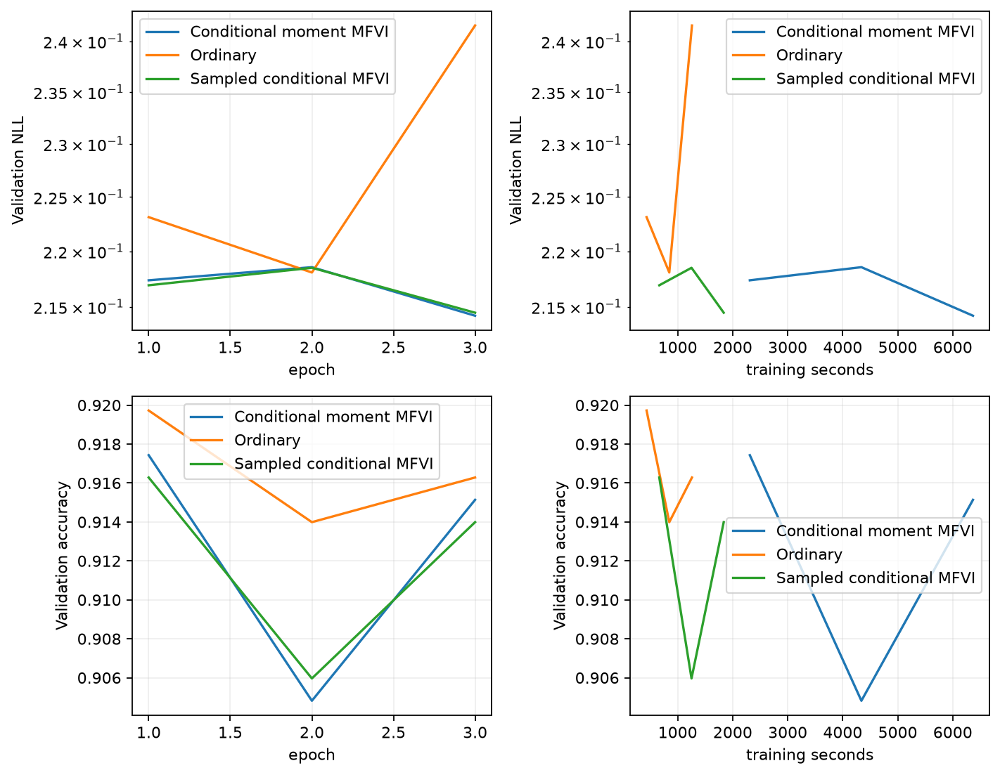

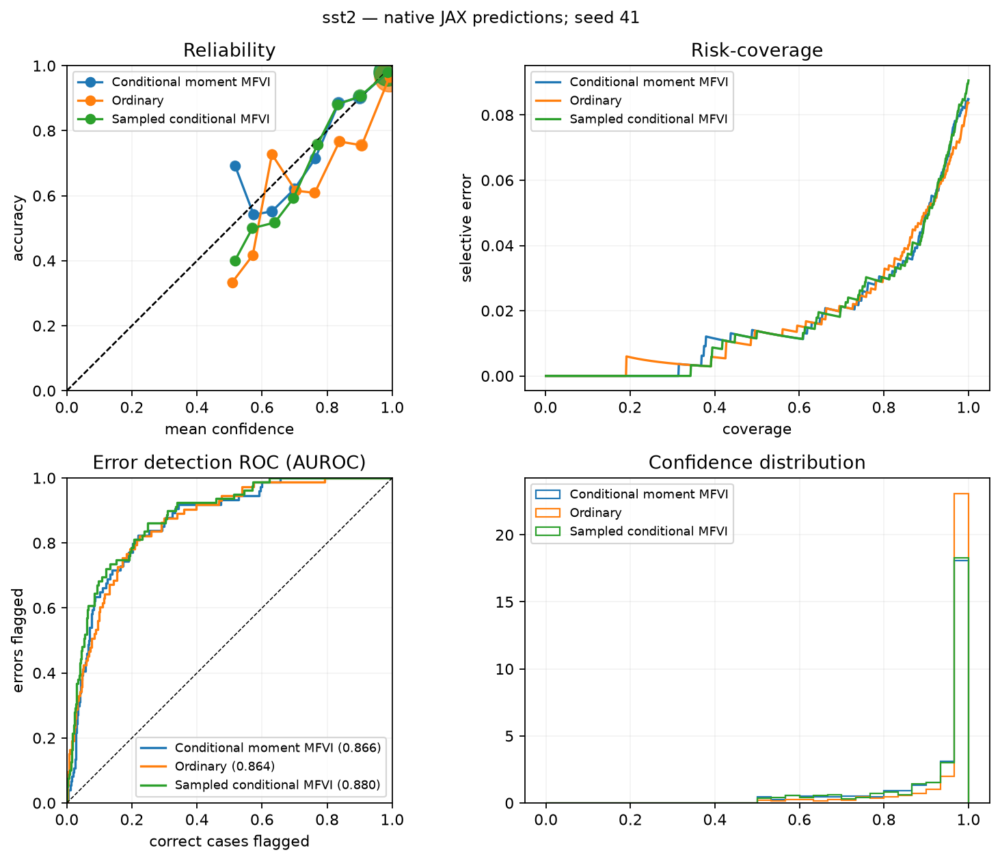

,method,optimizer,learning_rate,log variance / rho LR,point / head decay,KL / external field strength,training samples,conditional_pairs,stochastic prediction passes,epochs,selected_epoch,compile s
0,Conditional moment MFVI,BLoB split AdamW/SGD,0.001,0.002,0.01,—,1,2,10,6,6,219.41328
1,Ordinary,AdamW,0.001,—,0.01,—,0,0,0,6,5,49.95933
2,Sampled conditional MFVI,BLoB split AdamW/SGD,0.001,0.002,0.01,—,1,0,10,6,6,77.33050


,method,Accuracy ↑,NLL ↓,ECE ↓,Brier ↓,AURC ↓,Error AUROC ↑,OOD AUROC ↑,Train s ↓,Train × ↓,Infer s ↓,Infer × ↓
0,Conditional moment MFVI,0.96378,0.14202,0.00889,0.05471,0.00279,0.94960,0.96645,2680.52021,5.46228,124.93430,10.34921
1,Ordinary,0.96067,0.15858,0.01102,0.05915,0.00291,0.95312,0.96885,490.73286,1.00000,12.07187,1.00000
2,Sampled conditional MFVI,0.96333,0.14637,0.01167,0.05559,0.00303,0.94702,0.96590,831.10161,1.69359,124.56052,10.31825


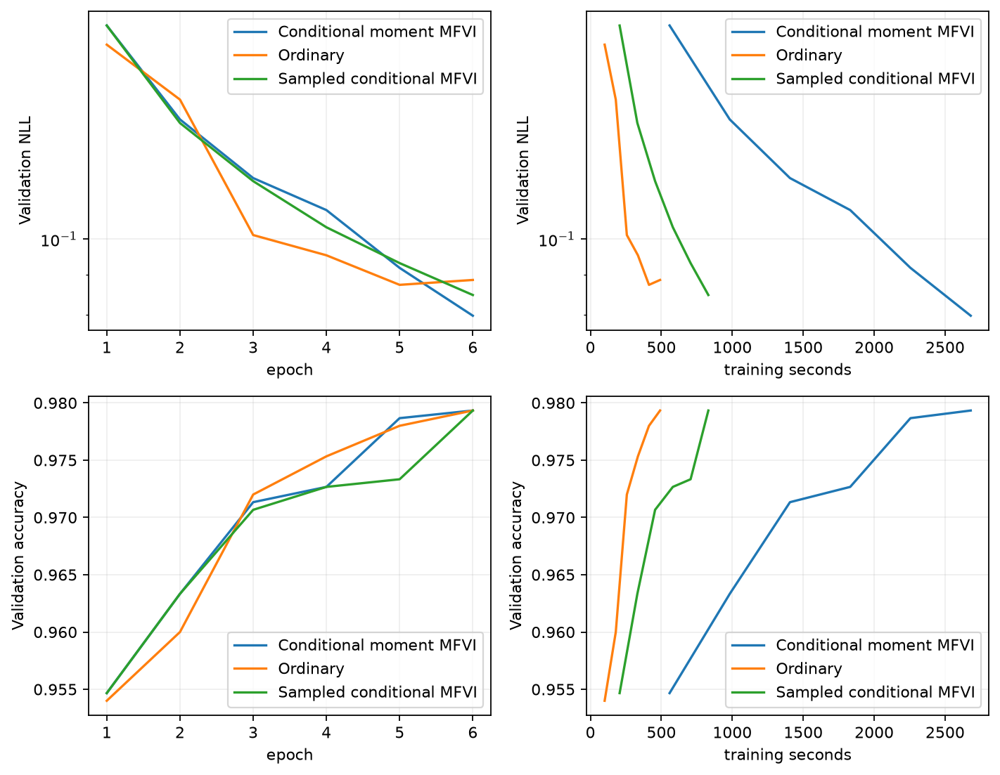

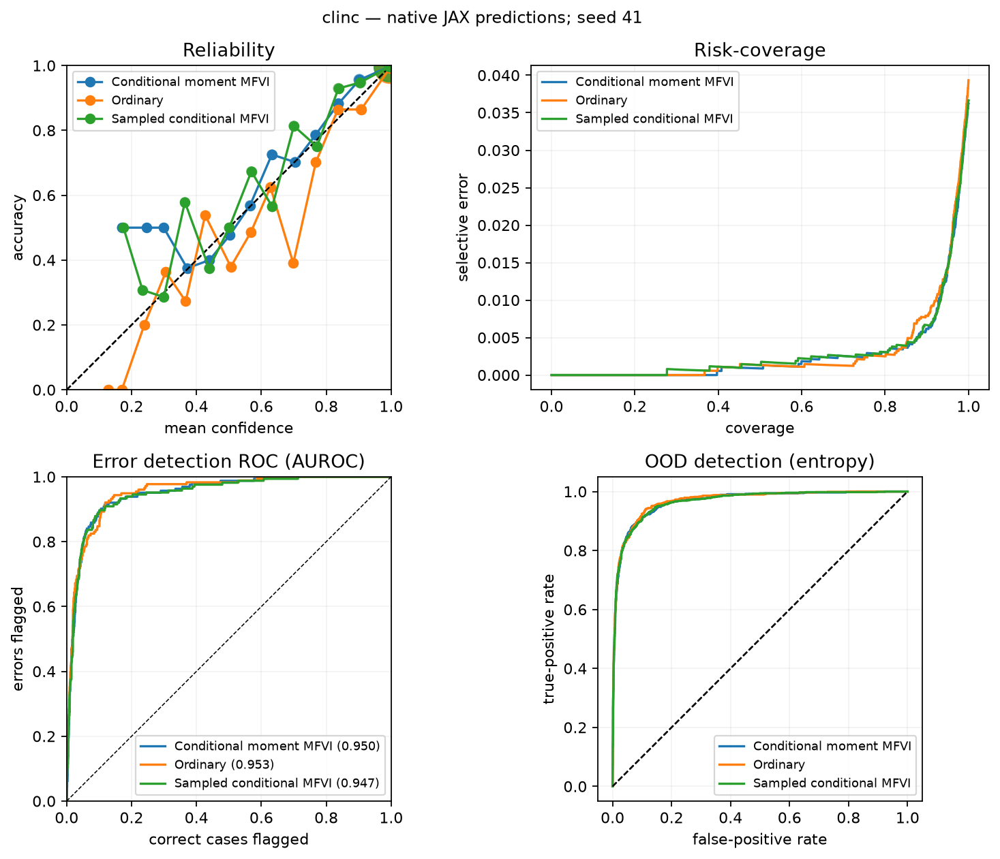

,task,training,prediction,draws,accuracy,nll,ece,inference_seconds
0,clinc,sampled,sampled,1,0.95933,0.16904,0.00950,13.09695
1,clinc,hybrid,sampled,1,0.95844,0.16703,0.00770,13.06203
2,clinc,sampled,sampled,4,0.96089,0.15194,0.00715,50.82428
3,clinc,hybrid,sampled,4,0.96178,0.15096,0.00576,50.58888
4,clinc,sampled,sampled,10,0.96333,0.14637,0.01167,124.93844
5,clinc,hybrid,sampled,10,0.96378,0.14202,0.00889,124.57160
6,clinc,sampled,hybrid,1,0.95956,0.16866,0.00711,44.13825
7,clinc,hybrid,hybrid,1,0.96044,0.16676,0.00830,43.77104
8,clinc,sampled,hybrid,4,0.96267,0.15198,0.00873,169.11998
9,clinc,hybrid,hybrid,4,0.96244,0.15051,0.00827,168.75258


In [89]:
frame=results.plots('results','figures')
for task in ['sst2','clinc']:
    if len(frame) and (frame.architecture==task).any():
        display(HTML('<h3>'+{'sst2':'GPT-2 LoRA / SST-2','clinc':'RoBERTa LoRA / CLINC150'}[task]+'</h3>'))
        display(results.protocol_table(frame,task).round(5).fillna('—'))
        display(results.reader_table(frame,task).round(5).fillna("—"))
        for name in ['learning','uncertainty']:
            p=pathlib.Path(f'figures/{task}_{name}.png')
            if p.exists():display(Image(filename=str(p)))
p=pathlib.Path('results/text_serving.json')
if p.exists():
    import json
    serving=pd.DataFrame(json.loads(p.read_text()))
    display(serving[['task','training','prediction','draws','accuracy','nll','ece','inference_seconds']].round(5))

**What the text examples demonstrate.** The native conditional-moment training
path improves predictive NLL and ECE over the ordinary baseline in both datasets.
CLINC also improves accuracy; SST-2's accuracy is slightly lower. These are distinct
outcomes, and the OOD table is assessed separately. The same-belief serving table
shows how prediction choices change both quality and cost. In particular, the
ten-pass primary predictor is not evidence of one-pass transformer deployment.
The faster one-pass MNIST result and this transformer result therefore support
different computational claims.

## 8. Reproduction and code reading

Start with `gaussian.py`, `layers.py`, and `messages.py`. Then read the method-specific heads and
updates in `heads.py` and `inference.py`. `covariance.py` changes the retained moment representation,
not the definition of EP or MFVI. `models.py` and `transformers.py` define the architectures.
`training.py` and `text_training.py` execute the minibatch protocols. `data.py`, `uncertainty.py`,
`plots.py`, and `results.py` supply the shared data and evaluation path.

Exact conditioning and site references are independent NumPy/SciPy code. Every figure is generated
from saved numeric arrays or newly executed JAX computations. The source-only supplement excludes
checkpoints and large datasets. The complete source remains in the notebook's collapsed bootstrap cell. `gaussian_text.py` supplies the original independent-Gaussian EP/MFVI adapter or full-weight updates; the conditional Gaussian MFVI path is separately named.

In [92]:
if RUN_CHECKS:
    completed=subprocess.run([sys.executable,'run_validation.py','--output','results/checks'],
        env={**os.environ,'PYTHONPATH':str(ROOT/'src')},capture_output=True,text=True)
    pathlib.Path('results/checks/execution.log').write_text(completed.stdout+'\n'+completed.stderr)
    import json
    receipt=json.loads(pathlib.Path('results/checks/validation_receipt.json').read_text())
    display(pd.DataFrame([{k:receipt[k] for k in ['status','tests_run','failures','errors','seconds','jax']}]))
    artifact('results/checks/validation_receipt.json','Versions, device and tested source hash: ')
    if completed.returncode:
        print(completed.stderr)
        raise RuntimeError('JAX validation failed')

,status,tests_run,failures,errors,seconds,jax
0,PASS,55,0,0,440.864536,0.4.38


Implementation references: [JAX automatic differentiation](https://docs.jax.dev/en/latest/automatic-differentiation.html),
[Flax NNX summaries](https://flax.readthedocs.io/en/latest/api_reference/flax.nnx/summary.html),
[ONNX export and Netron](https://enpasos.github.io/jax2onnx/), and
[BLoB source](https://github.com/Wang-ML-Lab/bayesian-peft/tree/7d960082efa3a680b76aac79d2a4f13d7f0f651a).